# ID2223 — Lab 1: Practical ML Foundations and CIFAR-10 Experiments

**Group Skibzz:** Md Ahsanul Karim, Md Sakibul Islam, Rong Jin

This notebook combines the **practical ML foundations** of `ID2223_Lab1.ipynb` with our **CIFAR-10 experiments for Tasks 1–6 and both optional challenges**. The original introductory material is retained in **Part A**, and the CIFAR-10 work is presented in **Part B** with explanations before each implementation step. The accompanying report is `ID2223_Lab1_Tasks1-6_Report.pdf`.

**How to read it:** Part A uses the small scikit-learn digits dataset to introduce training, evaluation, and checkpointing. Part B is a separate experimental workflow using CIFAR-10 (32 × 32 RGB images). Its results and trained models should not be confused with the earlier digits example.

**Reproducibility:** The stored outputs come from one top-to-bottom run of this notebook on a Google Colab Tesla T4, with every model retrained in that run (`FORCE_RETRAIN = True`, `CLEAR_ARTIFACTS = True`). Part B uses the `local` profile (eight epochs), fixed seeds and a fixed 45,000/5,000 training/validation split. A rerun on the same GPU type reproduces the accuracies, while timings vary by a few percent.

**Note on a few outputs:** The Colab session was interrupted and partly re-run, and twelve cells lost their displayed output although they ran (their results feed the later tables). For those cells (the strong-L2 and no-dropout training logs and plots and the Task 3 summary table in B10–B11, the two augmented training logs and the evaluation-set cell in B12, and the Task 5 metrics, confusion matrices, prediction examples and FGSM shape check) we show the output of the previous T4 run of the same code. Every accuracy in them is identical to this run (for example strong L2 69.28%, no dropout 78.64%, augmented 77.56%, strong augmentation 76.40%, ResNet-18 test 81.71%), and only the training times differ by about 1%. The severity example figure in B13 uses no model and was drawn locally from the same validation images. The FP16 cell in Challenge 1 has no displayed output, but its rows appear in the next table.

## How to reproduce

1. Open this notebook in [Google Colab](https://colab.research.google.com) (**File → Upload notebook**, or open it from GitHub).
2. Select a GPU: **Runtime → Change runtime type → T4 GPU**.
3. Run everything: **Runtime → Run all**. Allow access to Google Drive when asked.
4. Check that the first Part B device cell prints `Device: cuda | Tesla T4`. If it prints `cpu`, the GPU runtime is not active.

**What happens:** CIFAR-10 is downloaded with torchvision (about 170 MB). Checkpoints and figures are written to `MyDrive/kth-sml-lab1/local/` (`checkpoints/`, `figures/`). The Challenge 2 section also downloads CIFAR-10.1 (about 6 MB). A full run with `FORCE_RETRAIN = True` retrains all models, including the challenge fine-tuning, and takes a little over one hour on a T4.

**Settings** (in the Part B configuration cell):
- `PROFILE = "local"`: eight epochs on the full data, as used for all reported results. `"smoke"` is a two-epoch run on small subsets that only checks the code runs.
- `FORCE_RETRAIN = True`: retrain every model. Set it to `False` to load finished runs from Drive and resume interrupted ones, which is useful after a Colab disconnect.
- `CLEAR_ARTIFACTS` (cell after the Drive mount): set it to `True` to delete the stored checkpoints and figures of the profile before a fresh run.
- `USE_DRIVE = True`: keep artifacts in Google Drive. Outside Colab, artifacts go to `artifacts/` next to the notebook and data to `data/`.

**Environment of the reported run:** Python 3.13.16, PyTorch 2.14.1+cu130, torchvision 0.29.1+cu130, Tesla T4, FP32. The notebook also runs locally on Apple MPS or CPU, with different timings.

## Part A. Practical ML foundations — original tutorial

The following tutorial sections and explanations are retained from `ID2223_Lab1.ipynb`.

<a href="https://colab.research.google.com/github/isakibul15/kth-sml-lab-assign/blob/main/ID2223_Lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 1 Practical ML foundations

We will build a small handwritten-digit classifier, compare it with simple baselines, and learn how to train and evaluate it on a GPU.

Choose **Runtime → Change runtime type → T4 GPU** (or another available GPU) before starting. Changing runtime can reset variables and temporary files. We will configure device placement when we reach training. CPU can be used as a fallback in this lab.

Lab 1 has **no assignments, report, homework or submissions**. It is supposed to be an introductory to popular ML libraries and common workflow that will be used in later tasks.

## Building and evaluating a classifier
### A1. Basic libraries
Our task is to predict a digit from a small grayscale image and learn how to use ML libraries in this process. NumPy stores numeric arrays, pandas makes data summaries readable, Matplotlib visualizes images and learning curves, scikit-learn supplies classical ML tools, and PyTorch supplies differentiable neural networks.

**NumPy: inspect shape and dtype.** A batch has a sample dimension and a feature dimension. Here are two examples and three numeric features describing their shape, data type and means.

In [128]:
import numpy as np

example_array = np.array(
    [[0.0, 1.0, 2.0], [3.0, 4.0, 5.0]],
    dtype=np.float32,
)

print("Shape:", example_array.shape)
print("Dtype:", example_array.dtype)
print("Feature means:", example_array.mean(axis=0)) # change axis = 1 to see what happens

Shape: (2, 3)
Dtype: float32
Feature means: [1.5 2.5 3.5]


**pandas: put the same values in a data frame.** It makes it easier to inspect and operate data.

In [129]:
import pandas as pd

example_table = pd.DataFrame(
    example_array,
    columns=["feature_0", "feature_1", "feature_2"],
)
example_table

,feature_0,feature_1,feature_2
0,0.0,1.0,2.0
1,3.0,4.0,5.0


**Matplotlib: visualization.** We will use plots for images, class counts, losses and errors.

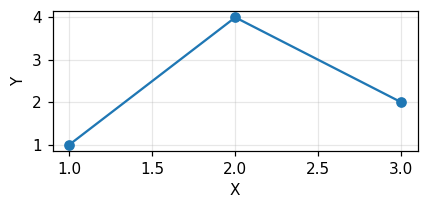

In [130]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(4, 2))
ax.plot([1, 2, 3], [1, 4, 2], marker="o")
ax.set(xlabel="X", ylabel="Y")
fig.tight_layout()
plt.show()

**PyTorch: tensors and automatic differentiation.** A tensor has a shape, dtype and device. It can also track gradients. For now we use CPU tensors, and later we will explicitly move neural computation to CUDA.

In [131]:
import torch
from torch import nn

example_tensor = torch.from_numpy(example_array)

print("Shape:", example_tensor.shape)
print("Dtype:", example_tensor.dtype)
print("Device:", example_tensor.device)

Shape: torch.Size([2, 3])
Dtype: torch.float32
Device: cpu


**A tiny gradient example.** For a scalar $f(w) = \sum_i w_i x_i$, the gradient with respect to $w$ is $x$. Predict the result, then inspect it. Gradients accumulate unless cleared.

In [132]:
features = torch.tensor([2.0, -3.0])
weights = torch.tensor([1.0, 2.0], requires_grad=True)

value = (weights * features).sum()
value.backward()

print("Scalar value:", value.item())
print("Gradient:", weights.grad)
assert torch.allclose(weights.grad, features) # validate that these are close

Scalar value: -4.0
Gradient: tensor([ 2., -3.])


### A2. Data setup
**Digits dataset from scikit-learn.** Each observation is an 8 × 8 grayscale image with a label from 0 to 9. The flat array contains 64 pixel features per example.

In [133]:
from sklearn.datasets import load_digits

digits = load_digits()

pixel_features = digits.data
image_labels = digits.target

print(digits.DESCR)

.. _digits_dataset:

Optical recognition of handwritten digits dataset
--------------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 1797
:Number of Attributes: 64
:Attribute Information: 8x8 image of integer pixels in the range 0..16.
:Missing Attribute Values: None
:Creator: E. Alpaydin (alpaydin '@' boun.edu.tr)
:Date: July; 1998

This is a copy of the test set of the UCI ML hand-written digits datasets
https://archive.ics.uci.edu/ml/datasets/Optical+Recognition+of+Handwritten+Digits

The data set contains images of hand-written digits: 10 classes where
each class refers to a digit.

Preprocessing programs made available by NIST were used to extract
normalized bitmaps of handwritten digits from a preprinted form. From a
total of 43 people, 30 contributed to the training set and different 13
to the test set. 32x32 bitmaps are divided into nonoverlapping blocks of
4x4 and the number of on pixels are counted in each block. This generates
an in

**Inspect the dataset.** Check dimensions, value ranges, label classes and finite values. It is important to understand your data before applying any complicated models. You oftentimes catch some downstream training errors from this stage.

In [134]:
print("Images:", digits.images.shape)
print("Flat features:", pixel_features.shape)
print("Labels:", image_labels.shape)
print("Pixel range:", pixel_features.min(), pixel_features.max())
print("Classes:", np.unique(image_labels))

assert np.isfinite(pixel_features).all()
assert pixel_features.shape[1] == 64
assert set(np.unique(image_labels)) == set(range(10))

Images: (1797, 8, 8)
Flat features: (1797, 64)
Labels: (1797,)
Pixel range: 0.0 16.0
Classes: [0 1 2 3 4 5 6 7 8 9]


**Analyze class balance.** A high accuracy can be misleading when one class dominates. The class-count table will also tell us what a majority-class baseline might achieve.

In [135]:
class_counts = (
    pd.Series(image_labels, name="digit").value_counts().sort_index().rename("count")
)

display(class_counts.to_frame())

,count
digit,
0,178
1,182
2,177
3,183
4,181
5,182
6,181
7,179
8,174


**Look at representative images.** The same sample can be represented as an 8 × 8 image for plotting or a length-64 feature vector for a fully connected model. Reshaping must preserve sample and pixel order.

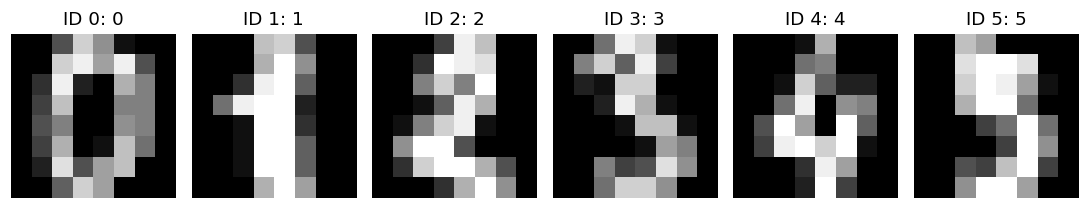

In [136]:
fig, axes = plt.subplots(1, 6, figsize=(10, 2))

for image_id, ax in enumerate(axes):
    ax.imshow(digits.images[image_id], cmap="gray", vmin=0, vmax=16)
    ax.set_title(f"ID {image_id}: {image_labels[image_id]}")
    ax.axis("off")

fig.tight_layout()
plt.show()

**Process the pixel features.** Divide by the maximum pixel value of 16 and produce raw features in $[0, 1]$. This fixed conversion does not learn statistics from validation or test examples. The StandardScaler in the next steps does learn statistics, so it must be fitted on training data only.

In [137]:
raw_features = (pixel_features / 16.0).astype(np.float32)
labels = image_labels.astype(np.int64)
sample_ids = np.arange(len(labels))

assert 0.0 <= raw_features.min() <= raw_features.max() <= 1.0
print(raw_features.min(), raw_features.max())

0.0 1.0


**Train/validation/test split.** We use a fixed split: 1,077 training, 360 validation and 360 test examples. We use training set to update model parameters, validation set to support decisions and monitor performance, and test set to measure against a frozen pipeline.

In [138]:
from sklearn.model_selection import train_test_split

SPLIT_SEED = 2223 # for data split only
# stratify ensures that the train and test sets preserve approximately the same class distribution as the original dataset
train_ids, holdout_ids = train_test_split(
    sample_ids,
    test_size=720,
    stratify=labels,
    random_state=SPLIT_SEED
)
val_ids, test_ids = train_test_split(
    holdout_ids,
    test_size=360,
    stratify=labels[holdout_ids],
    random_state=SPLIT_SEED,
)

train_ids, val_ids, test_ids = (np.sort(ids) for ids in (train_ids, val_ids, test_ids))

print("Split sizes:", len(train_ids), len(val_ids), len(test_ids))

Split sizes: 1077 360 360


**Verify class counts.** Original sample IDs let us trace labels back to images. We can inspect the split design to ensure we have a reasonable testbed for the model.

In [139]:
# np.bincount counts how many times each non-negative integer appears in an array
split_counts = pd.DataFrame(
    {
        "train": np.bincount(labels[train_ids], minlength=10),
        "validation": np.bincount(labels[val_ids], minlength=10),
        "test": np.bincount(labels[test_ids], minlength=10),
    }
)
display(split_counts)

,train,validation,test
0,107,36,35
1,109,36,37
2,106,36,35
3,110,36,37
4,108,36,37
5,109,37,36
6,109,36,36
7,107,36,36
8,104,35,35
9,108,36,36


**Scaling the data.** The validation and test arrays use the same learned means and scales as the training data. Constant pixel features are handled by StandardScaler without division by zero. We scale the data as $\displaystyle z = \frac{x-\mu}{\sigma}$ so they have approximately zero mean and unit variance.

In [140]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
train_features = scaler.fit_transform(raw_features[train_ids]).astype(np.float32)
val_features = scaler.transform(raw_features[val_ids]).astype(np.float32)
test_features = scaler.transform(raw_features[test_ids]).astype(np.float32)

print("Prepared training features:", train_features.shape)

Prepared training features: (1077, 64)


**Convert arrays to PyTorch datasets.** TensorDataset keeps a feature vector, integer label and original ID together. These tensors stay on CPU until we explicitly move a batch to GPU.

In [141]:
from torch.utils.data import DataLoader, TensorDataset

def make_dataset(features, ids):
    return TensorDataset(
        torch.from_numpy(features),
        torch.from_numpy(labels[ids]),
        torch.from_numpy(ids),
    )


train_dataset = make_dataset(train_features, train_ids)
val_dataset = make_dataset(val_features, val_ids)
test_dataset = make_dataset(test_features, test_ids)

In [142]:
# you can inspect an individual sample
train_dataset[0]

(tensor([ 0.0000, -0.3490, -1.1004,  0.0345,  0.2529, -0.1452, -0.4032, -0.1183,
         -0.0644, -0.6412, -1.9427, -0.2174,  1.2070,  0.1291, -0.5122, -0.1275,
         -0.0409, -0.7378, -1.2182,  1.4090,  1.4609, -0.3047, -0.5499, -0.1173,
         -0.0305,  1.4287,  0.9551,  1.2380,  0.9838, -0.9617, -0.6284, -0.0431,
          0.0000, -0.6712, -1.0578,  1.1213,  0.9621, -0.9917, -0.8226,  0.0000,
         -0.0624, -0.5371, -0.9067,  1.3681,  1.3249, -0.4021, -0.7938, -0.0781,
         -0.0386, -0.4085, -1.1597,  1.2517,  1.1972, -0.4630, -0.7659, -0.2210,
         -0.0305, -0.3097, -1.0943, -0.2427,  0.8654,  0.5531, -0.5076, -0.1975]),
 tensor(1),
 tensor(1))

### A3. Define a neural classifier and establish baselines
**Define a model with nn.Module.** The `__init__` constructor defines reusable components and basic architecture. The `forward` function defines the computations. The default example is a small one-hidden-layer MLP.

The model accepts standardized features of shape `[B, 64]` and returns ten raw logits per example. Do not apply softmax in forward when training with CrossEntropyLoss.

In [143]:
class MLP(nn.Module):
    def __init__(self, input_dim=64, hidden_dims=(32,), num_classes=10):
        super().__init__() # remember this
        layers = []
        previous_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.extend(
                [
                    nn.Linear(previous_dim, hidden_dim), # linear layer
                    nn.ReLU(), # non-linear activation
                ]
            )
            previous_dim = hidden_dim

        layers.append(nn.Linear(previous_dim, num_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, features):
        return self.network(features)

**Check the interface before training.** This temporary prototype only demonstrates shapes.

In [144]:
prototype = MLP(input_dim=64, hidden_dims=(32,), num_classes=10)

with torch.no_grad():
    prototype_logits = prototype(torch.zeros(4, 64))

print("Batch logits:", prototype_logits.shape)
assert prototype_logits.shape == (4, 10)
del prototype

Batch logits: torch.Size([4, 10])


**Construct baselines for comparison.** Before training the neural model, fit simple baselines on the same training dataset. Both baselines run on CPU.

In [145]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import make_pipeline

**Majority-class baseline.** Always predicting the most common training label tests whether the learned classifier adds value beyond class prevalence.

In [146]:
majority_baseline = DummyClassifier(strategy="most_frequent")
majority_baseline.fit(raw_features[train_ids], labels[train_ids])

majority_val_predictions = majority_baseline.predict(raw_features[val_ids])

**Logistic regression baseline.** We can build a stronger baseline with scikit-learn.

In [147]:
linear_baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=500, C=1.0),
)
linear_baseline.fit(raw_features[train_ids], labels[train_ids])

linear_val_predictions = linear_baseline.predict(raw_features[val_ids])

**Evaluate the baselines on validation.** We use accuracy and macro F1 as the metrics.

*   Accuracy
$$
\text{accuracy} = \frac{\text{Number of correct predictions}}{\text{Total predictions}}
$$
*   Macro F1
For each class,
$$
\text{Precision} = \frac{TP}{TP + FP}, \quad \text{Recall} = \frac{TP}{TP + FN}
$$
and F1
$$
F1 = 2\frac{\text{Precision}\cdot \text{Recall}}{\text{Precision} + \text{Recall}}.
$$
Macro F1 is the unweighted average of F1 across all classes:
$$
\text{Macro F1} = \frac{1}{K}\sum_{k=1}^K F1_k,
$$
where $K$ is the number of classes.

In [148]:
def classification_metrics(targets, predictions):
    return {
        "accuracy": accuracy_score(targets, predictions),
        "macro_f1": f1_score(
            targets,
            predictions,
            labels=list(range(10)),
            average="macro",
            zero_division=0,
        ),
    }


baseline_validation = {
    "Majority": classification_metrics(labels[val_ids], majority_val_predictions),
    "Logistic regression": classification_metrics(labels[val_ids], linear_val_predictions),
}
display(pd.DataFrame(baseline_validation).T)

,accuracy,macro_f1
Majority,0.1000,0.0182
Logistic regression,0.9528,0.9528


### A4. Prepare for reproducible training
**Choose and inspect the device.** If CUDA is unavailable, the example falls back to CPU.

In [149]:
GPU_AVAILABLE = torch.cuda.is_available()
device = torch.device("cuda" if GPU_AVAILABLE else "cpu")

print("Selected device:", device)
print("PyTorch:", torch.__version__, "CUDA runtime:", torch.version.cuda)

if GPU_AVAILABLE:
    print("GPU:", torch.cuda.get_device_name(0))
    torch.cuda.reset_peak_memory_stats(device) # useful for measuring the maximum GPU memory consumed during a particular operation, such as training

Selected device: cuda
PyTorch: 2.14.1+cu130 CUDA runtime: 13.0
GPU: Tesla T4


**Tensor movement is explicit.** Model parameters, input features and class labels must share a device during the forward/loss computation. DataLoader does not move them automatically.

In [150]:
cpu_example = torch.tensor([[1.0, 2.0]])
device_example = cpu_example.to(device)

print("Original tensor:", cpu_example.device)
print("Transferred tensor:", device_example.device)
print("For NumPy:", device_example.detach().cpu().numpy())

Original tensor: cpu
Transferred tensor: cuda:0
For NumPy: [[1. 2.]]


**Device mismatch.** Tensors should be on the same device for computations.

In [151]:
if GPU_AVAILABLE:
    demo_layer = nn.Linear(2, 1) # currently on cpu
    try:
        demo_layer(device_example)
    except RuntimeError as error:
        print("Expected device mismatch:", str(error).splitlines()[0])
    demo_layer = demo_layer.to(device)
    with torch.inference_mode():
        print("Aligned output device:", demo_layer(device_example).device)
    del demo_layer
else:
    print("Skipped for CPU fallback.")

Expected device mismatch: Expected all tensors to be on the same device, but got mat1 is on cuda:0, different from other tensors on cpu (when checking argument in method wrapper_CUDA_addmm)
Aligned output device: cuda:0


**Config training hyperparameters.** Save running hyperparameters and other information to make your experiments trackable and reproducible.

In [152]:
from dataclasses import asdict, dataclass

@dataclass
class TrainConfig:
    hidden_dims: tuple = (32,)
    learning_rate: float = 0.01
    batch_size: int = 64
    epochs: int = 8
    seed: int = 42

config = TrainConfig()
config

TrainConfig(hidden_dims=(32,), learning_rate=0.01, batch_size=64, epochs=8, seed=42)

**Randomness control for reproduction.** The split was reproducible with SPLIT_SEED. This seed controls model initialization and training randomness.

In [153]:
import random

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed(config.seed)

**Create dataloaders.** We create reproducible batch with a controlled generator seed here.

In [154]:
def make_loaders(batch_size, seed):
    generator = torch.Generator().manual_seed(seed)
    return {
        "train": DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True, # batches are shuffled during training
            generator=generator,
            num_workers=0,
        ),
        "train_eval": DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=False,
        ),
        "validation": DataLoader(
            val_dataset,
            batch_size=batch_size,
            shuffle=False,
        ),
    }

loaders = make_loaders(config.batch_size, config.seed)

**Initialize model, optimizer and define loss.** The optimizer must receive the parameters of the model that will actually be trained.

In [155]:
set_seed(config.seed)

model = MLP(input_dim=64, hidden_dims=config.hidden_dims, num_classes=10).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate)
loss_function = nn.CrossEntropyLoss()

print("Model parameter device:", next(model.parameters()).device)

Model parameter device: cuda:0


**Inspect one forward pass and its loss.** We use a non-shuffled batch so it does not consume the training loader's shuffle sequence.

In [156]:
batch_features, batch_labels, batch_ids = next(iter(loaders["train_eval"]))
batch_features = batch_features.to(device)
batch_labels = batch_labels.to(device)

with torch.no_grad():
    batch_logits = model(batch_features)
    initial_loss = loss_function(batch_logits, batch_labels)

print("Inputs / logits:", batch_features.shape, batch_logits.shape)
print("Target dtype:", batch_labels.dtype, "initial loss:", initial_loss.item())
assert batch_logits.shape == (len(batch_labels), 10)
assert torch.isfinite(batch_logits).all()

Inputs / logits: torch.Size([64, 64]) torch.Size([64, 10])
Target dtype: torch.int64 initial loss: 2.3097379207611084


### A5. Train, validate and inspect learning
**Commonly used operations.** Clear old gradients, compute logits (model outputs), compute loss, backpropagate, then update parameters.

In [157]:
def train_batch(model, batch, optimizer, loss_function, device):
    features, labels, _ = batch
    features = features.to(device)
    labels = labels.to(device)

    optimizer.zero_grad(set_to_none=True) # clear old gradients
    logits = model(features) # model pass
    loss = loss_function(logits, labels) # compute loss
    loss.backward() # backpropagate
    optimizer.step() # update parameters

    count = labels.numel()
    correct = (logits.argmax(dim=1) == labels).sum().item()
    return loss.item() * count, correct, count # return useful statistics so we can monitor the training

**One epoch visits all training batches.** Training mode is explicitly set.

In [158]:
def train_one_epoch(model, loader, optimizer, loss_function, device):
    model.train() # set to train mode
    total_loss, total_correct, total_count = 0.0, 0, 0

    for batch in loader:
        loss_sum, correct, count = train_batch(
            model, batch, optimizer, loss_function, device
        ) # defined above
        total_loss += loss_sum
        total_correct += correct
        total_count += count

    return {
        "cross_entropy": total_loss / total_count,
        "accuracy": total_correct / total_count,
    }

**An evaluate helper function.** It uses evaluation mode and disables autograd, but keeps ordered sample IDs for later error analysis.

In [159]:
@torch.inference_mode() # no gradients
def evaluate(model, loader, device):
    model.eval() # set to evaluation mode
    loss_sum = 0.0
    all_ids, all_targets, all_probabilities = [], [], []

    for features, targets, ids in loader:
        features, targets = features.to(device), targets.to(device)
        logits = model(features)
        loss_sum += nn.functional.cross_entropy(logits, targets, reduction="sum").item()
        all_ids.extend(ids.tolist())
        all_targets.extend(targets.cpu().tolist())
        all_probabilities.extend(logits.softmax(dim=1).cpu().tolist())

    probabilities = np.asarray(all_probabilities)
    predictions = probabilities.argmax(axis=1)
    return {
        "cross_entropy": loss_sum / len(all_targets),
        **classification_metrics(all_targets, predictions),
        "ids": np.asarray(all_ids),
        "targets": np.asarray(all_targets),
        "predictions": predictions,
        "probabilities": probabilities,
    }

**Checkpoint decision.** We will select the checkpoint with the lowest validation cross entropy.

In [160]:
import time

history = []
best_validation_loss = float("inf")
best_epoch = 0
best_state = None

**Put the pieces together for eight epochs.** Now we construct the loop: train, validate, log and select a checkpoint.

In [161]:
training_started = time.perf_counter() # timer

for epoch in range(1, config.epochs + 1):
    train_metrics = train_one_epoch(
        model, loaders["train"], optimizer, loss_function, device
    )
    val_metrics = evaluate(model, loaders["validation"], device)
    history.append(
        {
            "epoch": epoch,
            "train_loss": train_metrics["cross_entropy"],
            "val_loss": val_metrics["cross_entropy"],
            "train_accuracy": train_metrics["accuracy"],
            "val_accuracy": val_metrics["accuracy"],
        }
    )

    if val_metrics["cross_entropy"] < best_validation_loss:
        best_validation_loss = val_metrics["cross_entropy"]
        best_epoch = epoch
        best_state = {
            name: value.detach().cpu().clone()
            for name, value in model.state_dict().items()
        }

training_seconds = time.perf_counter() - training_started
display(pd.DataFrame(history))

,epoch,train_loss,val_loss,train_accuracy,val_accuracy
0,1,1.3170,0.5283,0.7057,0.8694
1,2,0.2851,0.2199,0.9220,0.9389
2,3,0.1232,0.1726,0.9675,0.9500
3,4,0.0703,0.1651,0.9824,0.9500
4,5,0.0461,0.1568,0.9935,0.9556
5,6,0.0316,0.1540,0.9981,0.9583
6,7,0.0223,0.1562,0.9991,0.9583
7,8,0.0169,0.1505,0.9991,0.9611


**Restore the selected checkpoint.** This may differ from the final epoch.

In [162]:
model.load_state_dict(best_state)
model.eval()

mlp_validation = evaluate(model, loaders["validation"], device)
validation_table = pd.DataFrame(
    {
        **baseline_validation,
        "MLP": {name: mlp_validation[name] for name in ("accuracy", "macro_f1")},
    }
).T

print("Best epoch:", best_epoch, "training seconds:", round(training_seconds, 3))
display(validation_table)

Best epoch: 8 training seconds: 0.521


,accuracy,macro_f1
Majority,0.1000,0.0182
Logistic regression,0.9528,0.9528
MLP,0.9611,0.9610


**The loss curve.** Cross-entropy can change even when accuracy does not. It's usually helpful to look at optimization progress to diagnose the overfitting/underfitting when something is wrong.

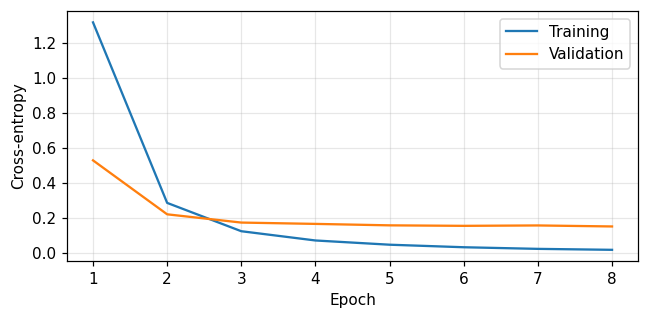

In [163]:
history_table = pd.DataFrame(history)

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(history_table["epoch"], history_table["train_loss"], label="Training")
ax.plot(history_table["epoch"], history_table["val_loss"], label="Validation")
ax.set(xlabel="Epoch", ylabel="Cross-entropy")
ax.legend()
fig.tight_layout()
plt.show()

**Accuracy.** The training curve here was measured during optimization. Without dropout or augmentation it is easier to compare with validation, but it is still not the deterministic score of the selected checkpoint.

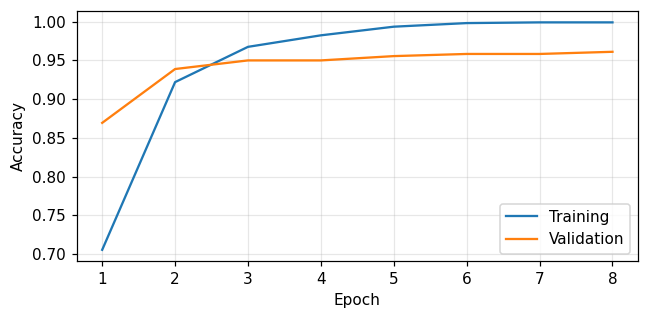

In [164]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(history_table["epoch"], history_table["train_accuracy"], label="Training")
ax.plot(history_table["epoch"], history_table["val_accuracy"], label="Validation")
ax.set(xlabel="Epoch", ylabel="Accuracy")
ax.legend()
fig.tight_layout()
plt.show()

**GPU memory.** Allocated memory tracks live tensors, and reserved memory includes the caching allocator. It's helpful if you want to consider GPU memory management.

In [165]:
gpu_memory = None

if GPU_AVAILABLE:
    gpu_memory = {
        "allocated_MiB": torch.cuda.memory_allocated(device) / 2**20,
        "reserved_MiB": torch.cuda.memory_reserved(device) / 2**20,
        "peak_allocated_MiB": torch.cuda.max_memory_allocated(device) / 2**20,
    }
    display(pd.DataFrame([gpu_memory]))
else:
    print("CUDA memory measurements are unavailable in the CPU fallback.")

,allocated_MiB,reserved_MiB,peak_allocated_MiB
0,1805.6377,2862.0,1832.2227


### A6. Evaluation, inference and portable checkpoints
**Define inference for a new raw input.** Training/evaluation loaders already contain standardized features. A new input instead arrives as raw $[0, 1]$ pixels, so this function applies the saved training means/scales exactly once and returns CPU probabilities. Softmax is useful here for interpreting predictions, not inside the training model's forward method.

In [166]:
@torch.inference_mode()
def predict_raw(model, raw, normalization, device):
    model.eval()
    raw = raw.to(device)
    mean = raw.new_tensor(normalization["mean"])
    scale = raw.new_tensor(normalization["scale"])
    standardized = (raw - mean) / scale # standardize the raw input
    return model(standardized).softmax(dim=1).cpu()

**Try a few training images before opening the test set.** This checks the inference interface safely.

In [167]:
normalization = {
    "mean": scaler.mean_.tolist(),
    "scale": scaler.scale_.tolist(),
}
raw_probe = torch.from_numpy(raw_features[train_ids[:4]])
probabilities_probe = predict_raw(model, raw_probe, normalization, device)

assert probabilities_probe.shape == (4, 10)
assert torch.allclose(probabilities_probe.sum(dim=1), torch.ones(4))
print("Predicted digits:", probabilities_probe.argmax(dim=1).tolist())

Predicted digits: [1, 2, 3, 4]


**Save what is needed to reconstruct the model.** A state_dict contains learned tensors, not the architecture or preprocessing contract. Save the constructor arguments, normalization and configuration as well.

In [168]:
from pathlib import Path
import uuid

run_directory = Path("lab1_runs") / f"session-{uuid.uuid4().hex[:8]}"
run_directory.mkdir(parents=True, exist_ok=False)
checkpoint_path = run_directory / "classifier.pt"

checkpoint = {
    "state_dict": model.state_dict(),
    "model_kwargs": {
        "input_dim": 64,
        "hidden_dims": config.hidden_dims,
        "num_classes": 10,
    },
    "normalization": normalization,
    "config": asdict(config),
    "best_epoch": best_epoch,
}
torch.save(checkpoint, checkpoint_path)
print("Saved in Colab:", checkpoint_path)

Saved in Colab: lab1_runs/session-cd07459c/classifier.pt


**Load GPU-trained weights on CPU.** `map_location='cpu'` makes the tensor placement explicit. Rebuild the same architecture before loading its state.

In [169]:
loaded = torch.load(checkpoint_path, map_location="cpu", weights_only=True)

cpu_model = MLP(**loaded["model_kwargs"])
cpu_model.load_state_dict(loaded["state_dict"])
cpu_model.eval()

print("Restored parameter device:", next(cpu_model.parameters()).device)

Restored parameter device: cpu


**Test the frozen model.** The MLP configuration and checkpoint were selected without test scores.

In [170]:
RUN_FINAL_DEMO = True  # Optional closing demonstration after validation decisions.
final_results = None

**Evaluate the frozen classifiers on the same test IDs.** The test loader is created here. We reuse the same evaluation function rather than writing a second metric implementation.

In [171]:
if RUN_FINAL_DEMO:
    test_loader = DataLoader(test_dataset, batch_size=config.batch_size, shuffle=False)
    final_results = evaluate(model, test_loader, device)
    final_rows = {
        "Majority": classification_metrics(
            labels[test_ids], majority_baseline.predict(raw_features[test_ids])
        ),
        "Logistic regression": classification_metrics(
            labels[test_ids], linear_baseline.predict(raw_features[test_ids])
        ),
        "MLP": {key: final_results[key] for key in ("accuracy", "macro_f1")},
    }
    display(pd.DataFrame(final_rows).T)
else:
    print("Final test evaluation is off; continue with the explanations below.")

,accuracy,macro_f1
Majority,0.1028,0.0186
Logistic regression,0.9583,0.9587
MLP,0.9722,0.9720


**Inspect per-class errors.** A confusion matrix adds information that one aggregate score hides. It uses the MLP predictions already obtained above, without retraining or choosing new settings.

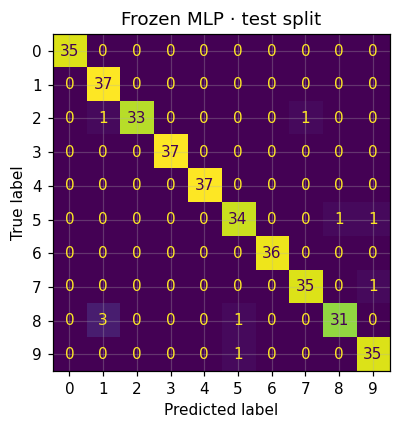

In [172]:
from sklearn.metrics import ConfusionMatrixDisplay

if final_results is not None:
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        final_results["targets"],
        final_results["predictions"],
        labels=list(range(10)),
        colorbar=False,
        ax=ax,
    )
    ax.set_title("Frozen MLP · test split")
    fig.tight_layout()
    plt.show()

**Look at an individual success and failure.** You can inspect the actual output to diagnose more fine-grained failure modes. It is usually helpful when you want to find problems that the evaluation metrics can possibly hide.

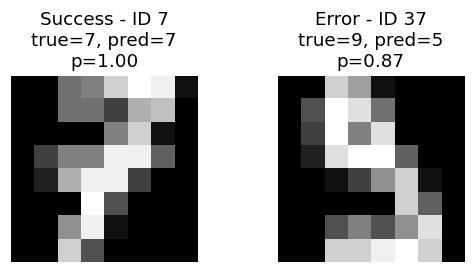

In [173]:
if final_results is not None:
    correct = (final_results["targets"] == final_results["predictions"])
    examples = []
    for name, mask in [("Success", correct), ("Error", ~correct)]:
        positions = np.flatnonzero(mask) # returns indices of non-zero elements in flattened way
        if len(positions):
            examples.append((name, int(positions[0]))) # one example per case
        else:
            print("No", name.lower(), "in this evaluation.")

    fig, axes = plt.subplots(1, len(examples), figsize=(5, 2.5), squeeze=False)
    for ax, (name, position) in zip(axes[0], examples):
        image_id = final_results["ids"][position]
        prediction = final_results["predictions"][position]
        confidence = final_results["probabilities"][position, prediction]
        ax.imshow(raw_features[image_id].reshape(8, 8), cmap="gray", vmin=0, vmax=1)
        ax.set_title(
            f"{name} - ID {image_id}\ntrue={labels[image_id]}, pred={prediction}\np={confidence:.2f}"
        )
        ax.axis("off")
    fig.tight_layout()
    plt.show()

## Recap and questions
We built a classifier from inspected data, established baselines, configured reproducible GPU training, measured validation behavior, and introduced inference, checkpoint and final evaluation.

References: [PyTorch basics](https://docs.pytorch.org/tutorials/beginner/basics/quickstart_tutorial.html), [CUDA semantics](https://docs.pytorch.org/docs/stable/notes/cuda.html), [scikit-learn digits](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html).

---

# Part B. CIFAR-10 — Tasks 1–6

The following sections implement the CIFAR-10 assignment. Each step states its purpose, the choice made, and the expected interpretation, following the explanation-before-code structure of Part A.

**Experimental protocol.** The official 50,000 CIFAR-10 training images are split into 45,000 for optimization and 5,000 for validation. The official 10,000-image test split is reserved for the final model comparison and subsequent descriptive prediction/adversarial analyses. Class labels remain unchanged by augmentation or evaluation corruption. Models use images normalized with statistics estimated from training images only.

## Task 1. Study and prepare the data
### B1. Environment and libraries
**Import the analysis and training libraries:** We use PyTorch for neural networks, torchvision for CIFAR-10, pandas for measured results, and Matplotlib for inspection. Keeping all imports together makes the notebook easier to rerun in Colab.

In [174]:
import copy
import gzip
import io
import json
import math
import os
import platform
import random
import subprocess
import sys
import time
from dataclasses import asdict, dataclass, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torchvision
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from torch import nn
from torchvision.datasets import CIFAR10

try:
    from IPython.display import display
except ImportError:  # running as a plain script
    display = print

IN_COLAB = "google.colab" in sys.modules
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

print("Python:", platform.python_version(), "| PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("Running in Colab:", IN_COLAB)

Python: 3.13.16 | PyTorch: 2.14.1+cu130 | torchvision: 0.29.1+cu130
Running in Colab: True


**Choose and inspect the compute device:** CUDA is preferred when available, with MPS or CPU as fallbacks. The synchronization helper makes measured epoch times account for queued GPU operations.

In [175]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    DEVICE_NAME = torch.cuda.get_device_name(0)
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    try:
        chip = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip()
    except Exception:
        chip = platform.machine()
    DEVICE_NAME = f"{chip} (MPS)"
else:
    device = torch.device("cpu")
    DEVICE_NAME = f"CPU ({platform.machine()})"

USE_AMP = device.type == "cuda"


def sync():
    """Wait for queued GPU work so wall-clock timings are honest."""
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


def autocast():
    return torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP)


print("Device:", device, "|", DEVICE_NAME, "| AMP:", USE_AMP)

Device: cuda | Tesla T4 | AMP: True


**Define the compute budget:** The `local` profile trains for eight epochs on the full training/validation partitions, while the `smoke` profile is a smaller correctness check. We retain the selected profile across experiments to avoid accidentally changing the budget.

In [176]:
PROFILES = {
    "smoke": dict(epochs=2, train_limit=2000, val_limit=1000, test_limit=1000, attack_n=64, pgd_steps=3, seed_repeats=1, finetune_epochs=1),
    "local": dict(epochs=8, train_limit=None, val_limit=None, test_limit=None, attack_n=500, pgd_steps=10, seed_repeats=1, finetune_epochs=1),
    "full": dict(epochs=15, train_limit=None, val_limit=None, test_limit=None, attack_n=1000, pgd_steps=10, seed_repeats=2, finetune_epochs=2),
}
# PROFILE = os.environ.get("LAB_PROFILE") or {"cuda": "full", "mps": "local", "cpu": "smoke"}[device.type]
PROFILE = "local"
P = PROFILES[PROFILE]

FORCE_RETRAIN = True      # True = ignore stored runs and train everything again
RUN_CHALLENGES = True     # optional extensions at the end
USE_DRIVE = True          # Colab only: keep artifacts in Google Drive across sessions

print("Profile:", PROFILE, P)

Profile: local {'epochs': 8, 'train_limit': None, 'val_limit': None, 'test_limit': None, 'attack_n': 500, 'pgd_steps': 10, 'seed_repeats': 1, 'finetune_epochs': 1}


**Keep experiment artifacts:** Checkpoints and plots are stored under the selected profile. When running in Colab with Google Drive, saved checkpoints survive a runtime restart, but the in-memory model variables do not.

In [177]:
if IN_COLAB and USE_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")
    ARTIFACT_ROOT = Path("/content/drive/MyDrive/kth-sml-lab1")
else:
    ARTIFACT_ROOT = Path("artifacts")
DATA_DIR = Path("/content/data") if IN_COLAB else Path("data")

ART = ARTIFACT_ROOT / PROFILE
RUN_DIR, CKPT_DIR, FIG_DIR, CACHE_DIR = (ART / d for d in ("runs", "checkpoints", "figures", "cache"))
for d in (RUN_DIR, CKPT_DIR, FIG_DIR, CACHE_DIR, DATA_DIR):
    d.mkdir(parents=True, exist_ok=True)


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Artifacts:", ART.resolve())
print("Data:", DATA_DIR.resolve())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Artifacts: /content/drive/MyDrive/kth-sml-lab1/local
Data: /content/data


**Optionally start from an empty artifact folder:** Set `CLEAR_ARTIFACTS = True` to delete the stored checkpoints, figures, runs and caches of the current profile before training, so nothing from an earlier run is reused or left behind. It only touches the profile folder shown above (for example `MyDrive/kth-sml-lab1/local`), never the downloaded dataset.

In [178]:
import shutil

CLEAR_ARTIFACTS = True    # True = delete this profile's checkpoints, figures, runs and caches

if CLEAR_ARTIFACTS:
    for d in (RUN_DIR, CKPT_DIR, FIG_DIR, CACHE_DIR):
        shutil.rmtree(d, ignore_errors=True)
        d.mkdir(parents=True, exist_ok=True)
    print("Cleared:", ART.resolve())
else:
    print("Keeping stored artifacts in:", ART.resolve())

Cleared: /content/drive/MyDrive/kth-sml-lab1/local


**Control randomness:** `SPLIT_SEED` fixes the stratified partition, and `BASE_SEED` controls initialization and other training randomness. Deterministic settings improve repeatability but do not guarantee exact equality across devices or software versions.

In [179]:
SPLIT_SEED = 2223
BASE_SEED = 42
CORRUPTION_SEED = 7
ATTACK_SEED = 123

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if device.type == "mps":
        torch.mps.manual_seed(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


set_seed(BASE_SEED)

### B2. Inspect CIFAR-10
**Load and examine the image tensors:** Each example is a 32 × 32 RGB image labelled as one of ten classes. The 50,000 training images and 10,000 test images are provided separately, and the test partition is not used to fit model parameters.

In [180]:
train_source = CIFAR10(DATA_DIR, train=True, download=True)
test_source = CIFAR10(DATA_DIR, train=False, download=True)
CLASSES = train_source.classes
NUM_CLASSES = len(CLASSES)

X_trainval = torch.from_numpy(train_source.data).permute(0, 3, 1, 2).contiguous()  # uint8 [50000, 3, 32, 32]
y_trainval = torch.tensor(train_source.targets, dtype=torch.long)
X_test_all = torch.from_numpy(test_source.data).permute(0, 3, 1, 2).contiguous()   # uint8 [10000, 3, 32, 32]
y_test_all = torch.tensor(test_source.targets, dtype=torch.long)

print("Provided training images:", tuple(X_trainval.shape), X_trainval.dtype)
print("Provided test images:    ", tuple(X_test_all.shape), X_test_all.dtype)
print("Pixel range:", int(X_trainval.min()), "to", int(X_trainval.max()))
print("Classes:", CLASSES)

assert X_trainval.shape == (50000, 3, 32, 32) and X_test_all.shape == (10000, 3, 32, 32)
assert set(y_trainval.unique().tolist()) == set(range(10))

Provided training images: (50000, 3, 32, 32) torch.uint8
Provided test images:     (10000, 3, 32, 32) torch.uint8
Pixel range: 0 to 255
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


**Confirm the selected accelerator:** Check the active runtime before starting long convolutional training, because a CPU runtime can take much longer than CUDA.

In [181]:
print("Device:", device)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

Device: cuda
CUDA available: True
GPU: Tesla T4


**Check the label distribution:** Class counts show whether overall accuracy might conceal class imbalance. CIFAR-10 is designed with equally represented classes.

In [182]:
class_counts = pd.DataFrame(
    {
        "provided train": np.bincount(y_trainval.numpy(), minlength=10),
        "provided test": np.bincount(y_test_all.numpy(), minlength=10),
    },
    index=CLASSES,
)
display(class_counts)

,provided train,provided test
airplane,5000,1000
automobile,5000,1000
bird,5000,1000
cat,5000,1000
deer,5000,1000
dog,5000,1000
frog,5000,1000
horse,5000,1000
ship,5000,1000
truck,5000,1000


**Visualize representative images:** Small RGB images can be difficult to interpret: background, viewpoint, and object scale all influence classification.

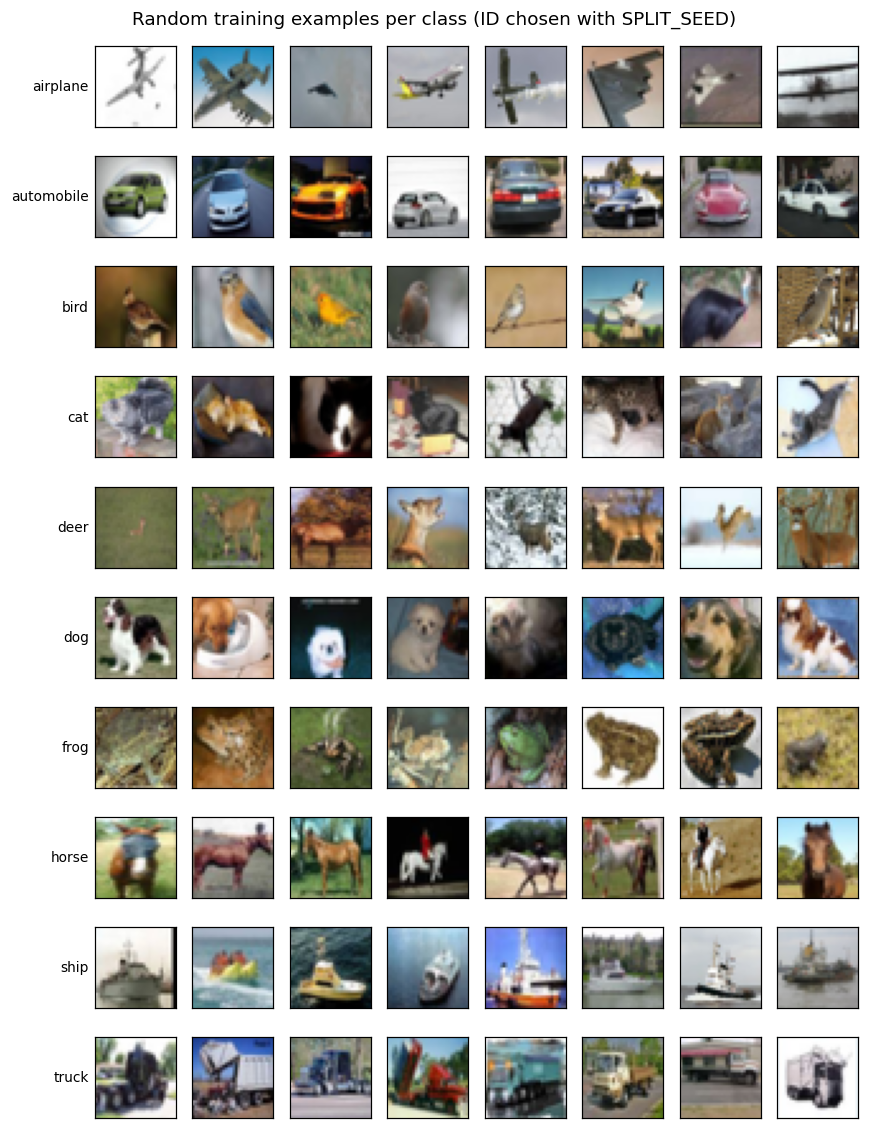

In [183]:
fig, axes = plt.subplots(NUM_CLASSES, 8, figsize=(8, 10.5))
rng = np.random.default_rng(SPLIT_SEED)
for c in range(NUM_CLASSES):
    picks = rng.choice(np.flatnonzero(y_trainval.numpy() == c), size=8, replace=False)
    for j, idx in enumerate(picks):
        ax = axes[c, j]
        ax.imshow(X_trainval[idx].permute(1, 2, 0).numpy())
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if j == 0:
            ax.set_ylabel(CLASSES[c], rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("Random training examples per class (ID chosen with SPLIT_SEED)")
fig.tight_layout()
savefig(fig, "t1_examples")
plt.show()

**Study pixel statistics:** Image intensity and class-level variation help us decide how to scale inputs and diagnose misleading visual cues.

In [184]:
x01 = X_trainval.float() / 255.0
per_image = pd.DataFrame(
    {
        "class": [CLASSES[i] for i in y_trainval.tolist()],
        "brightness": x01.mean(dim=(1, 2, 3)).numpy(),
        "contrast (pixel std)": x01.std(dim=(1, 2, 3)).numpy(),
        "R": x01[:, 0].mean(dim=(1, 2)).numpy(),
        "G": x01[:, 1].mean(dim=(1, 2)).numpy(),
        "B": x01[:, 2].mean(dim=(1, 2)).numpy(),
    }
)
display(per_image.groupby("class").mean().round(3))
del x01

,brightness,contrast (pixel std),R,G,B
class,,,,,
airplane,0.558,0.204,0.526,0.560,0.589
automobile,0.458,0.237,0.471,0.455,0.447
bird,0.468,0.182,0.489,0.491,0.424
cat,0.456,0.217,0.495,0.456,0.416
deer,0.438,0.179,0.472,0.465,0.378
dog,0.460,0.217,0.500,0.465,0.417
frog,0.418,0.187,0.470,0.438,0.345
horse,0.466,0.221,0.502,0.480,0.417
ship,0.523,0.216,0.490,0.525,0.555


### B3. Split and preprocess the data
**Create stratified training and validation partitions:** We split the official training set into 45,000 training and 5,000 validation examples using a fixed seed. The 10,000-image official test set is left separate.

In [185]:
all_ids = np.arange(len(y_trainval))
train_ids, val_ids = train_test_split(
    all_ids, test_size=5000, stratify=y_trainval.numpy(), random_state=SPLIT_SEED
)
test_ids = np.arange(len(y_test_all))


def stratified_limit(ids, labels, limit):
    """Smaller stratified subset for the smoke profile (no-op when limit is None)."""
    if limit is None or limit >= len(ids):
        return ids
    keep, _ = train_test_split(ids, train_size=limit, stratify=labels[ids], random_state=SPLIT_SEED)
    return keep


train_ids = np.sort(stratified_limit(train_ids, y_trainval.numpy(), P["train_limit"]))
val_ids = np.sort(stratified_limit(val_ids, y_trainval.numpy(), P["val_limit"]))
test_ids = np.sort(stratified_limit(test_ids, y_test_all.numpy(), P["test_limit"]))

# A fixed subset of the training split, evaluated without augmentation or dropout, gives a
# deterministic training accuracy of the selected checkpoint (the running accuracy logged during an
# epoch is measured with augmentation/dropout switched on and with changing weights).
train_eval_ids = np.sort(np.random.default_rng(SPLIT_SEED).choice(train_ids, size=min(5000, len(train_ids)), replace=False))

assert not set(train_ids) & set(val_ids)
split_counts = pd.DataFrame(
    {
        "train": np.bincount(y_trainval.numpy()[train_ids], minlength=10),
        "validation": np.bincount(y_trainval.numpy()[val_ids], minlength=10),
        "test": np.bincount(y_test_all.numpy()[test_ids], minlength=10),
    },
    index=CLASSES,
)
split_counts.loc["total"] = split_counts.sum()
display(split_counts)

,train,validation,test
airplane,4500,500,1000
automobile,4500,500,1000
bird,4500,500,1000
cat,4500,500,1000
deer,4500,500,1000
dog,4500,500,1000
frog,4500,500,1000
horse,4500,500,1000
ship,4500,500,1000
truck,4500,500,1000


**Estimate RGB normalization using only training images:** We calculate the mean and standard deviation per channel on the training partition. Validation and test images use those same values, because computing normalization statistics from the test set would leak information.

In [186]:
def channel_stats(images_uint8, chunk=5000):
    total = torch.zeros(3, dtype=torch.float64)
    total_sq = torch.zeros(3, dtype=torch.float64)
    n = 0
    for start in range(0, len(images_uint8), chunk):
        x = images_uint8[start:start + chunk].to(torch.float64) / 255.0
        total += x.sum(dim=(0, 2, 3))
        total_sq += (x ** 2).sum(dim=(0, 2, 3))
        n += x.shape[0] * x.shape[2] * x.shape[3]
    mean = total / n
    std = (total_sq / n - mean ** 2).sqrt()
    return mean.float(), std.float()


CIFAR_MEAN, CIFAR_STD = channel_stats(X_trainval[train_ids])
print("Training-split mean (R, G, B):", CIFAR_MEAN.numpy().round(4))
print("Training-split std  (R, G, B):", CIFAR_STD.numpy().round(4))

Training-split mean (R, G, B): [0.4913 0.4822 0.4464]
Training-split std  (R, G, B): [0.247  0.2434 0.2615]


**Prepare reusable split and batch helpers:** The images are stored as unsigned bytes to save memory. A batch is converted to floats in `[0, 1]` before normalization, and IDs remain available to trace predictions back to examples.

In [187]:
class TensorData:
    """A split held on the device: uint8 images, labels and the original sample IDs."""

    def __init__(self, images_uint8, labels, ids, name):
        self.x = images_uint8.to(device)
        self.y = labels.to(device)
        self.ids = torch.as_tensor(np.asarray(ids))
        self.name = name

    def __len__(self):
        return len(self.ids)


def iterate(data, batch_size, generator=None):
    """Yield (uint8 images, labels, ids). Shuffled when a generator is given."""
    n = len(data)
    order = torch.randperm(n, generator=generator) if generator is not None else torch.arange(n)
    for start in range(0, n, batch_size):
        idx = order[start:start + batch_size]
        idx_dev = idx.to(device)
        yield data.x[idx_dev], data.y[idx_dev], data.ids[idx]


def to_float(x_uint8):
    return x_uint8.float().div_(255.0)


SPLITS = {
    "train": TensorData(X_trainval[train_ids], y_trainval[train_ids], train_ids, "train"),
    "train_eval": TensorData(X_trainval[train_eval_ids], y_trainval[train_eval_ids], train_eval_ids, "train_eval"),
    "val": TensorData(X_trainval[val_ids], y_trainval[val_ids], val_ids, "val"),
    "test": TensorData(X_test_all[test_ids], y_test_all[test_ids], test_ids, "test"),
}
for k, v in SPLITS.items():
    print(f"{k:>10}: {len(v):>6} images on {v.x.device}")

     train:  45000 images on cuda:0
train_eval:   5000 images on cuda:0
       val:   5000 images on cuda:0
      test:  10000 images on cuda:0


### B4. Study augmentation
**Define appropriate CIFAR-10 transformations:** Standard augmentation uses reflective padding, random cropping, and horizontal flipping. Strong augmentation additionally samples modest rotation, shear, and Gaussian noise. The same augmentation helpers will be reused for Task 4, but augmentation is not applied to the initial Task 2 baselines.

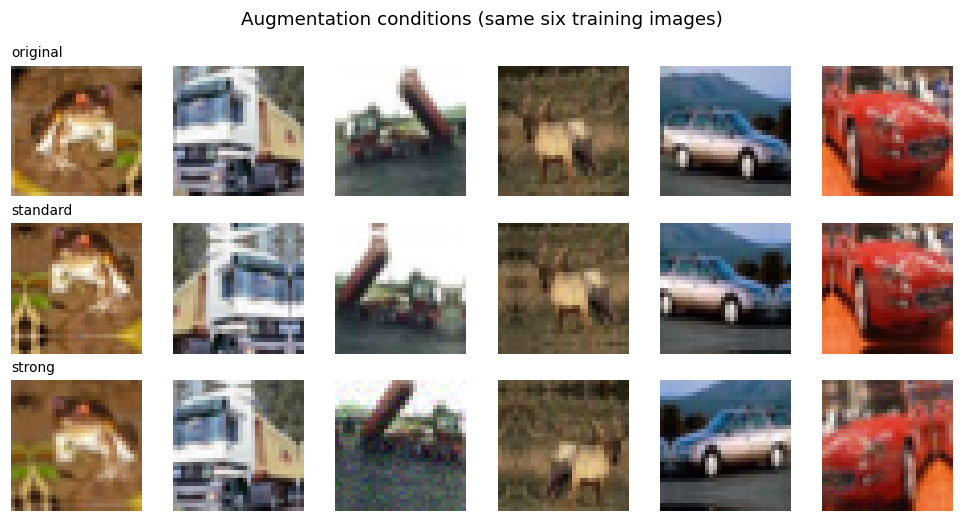

In [188]:
def affine_batch(x, angle_deg, shear_deg=None, scale=None, padding_mode="reflection"):
    """Rotate / shear / scale each image of a [B, 3, H, W] batch around its centre (bilinear)."""
    B = x.shape[0]
    angle = torch.deg2rad(angle_deg.float())
    shear = torch.deg2rad(shear_deg.float()) if shear_deg is not None else torch.zeros(B)
    scale = scale.float() if scale is not None else torch.ones(B)
    cos, sin = torch.cos(angle), torch.sin(angle)
    rot = torch.stack([torch.stack([cos, -sin], -1), torch.stack([sin, cos], -1)], -2)          # [B, 2, 2]
    shr = torch.stack([torch.stack([torch.ones(B), torch.tan(shear)], -1),
                       torch.stack([torch.zeros(B), torch.ones(B)], -1)], -2)
    A = (rot @ shr) / scale[:, None, None]       # maps output coordinates to input coordinates
    theta = torch.cat([A, torch.zeros(B, 2, 1)], dim=2).to(x.device, x.dtype)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode=padding_mode, align_corners=False)


def random_crop_flip(x, gen, pad=4):
    B, C, H, W = x.shape
    padded = F.pad(x, (pad, pad, pad, pad), mode="reflect")
    dy = torch.randint(0, 2 * pad + 1, (B,), generator=gen).to(x.device)
    dx = torch.randint(0, 2 * pad + 1, (B,), generator=gen).to(x.device)
    rows = dy[:, None] + torch.arange(H, device=x.device)[None, :]
    cols = dx[:, None] + torch.arange(W, device=x.device)[None, :]
    out = padded[
        torch.arange(B, device=x.device)[:, None, None, None],
        torch.arange(C, device=x.device)[None, :, None, None],
        rows[:, None, :, None],
        cols[:, None, None, :],
    ]
    flip = (torch.rand(B, generator=gen) < 0.5).to(x.device)
    return torch.where(flip[:, None, None, None], out.flip(3), out)


def augment(x, kind, gen):
    """x: float batch in [0, 1] on the device. gen: CPU generator owned by the run."""
    if kind == "none":
        return x
    x = random_crop_flip(x, gen)
    if kind == "strong":
        B = x.shape[0]
        apply = (torch.rand(B, generator=gen) < 0.5).float()
        angle = (torch.rand(B, generator=gen) * 2 - 1) * 15 * apply
        shear = (torch.rand(B, generator=gen) * 2 - 1) * 10 * apply
        x = affine_batch(x, angle, shear)
        sigma = torch.rand(B, generator=gen) * 0.06 * (torch.rand(B, generator=gen) < 0.5).float()
        noise = torch.randn(x.shape, generator=gen) * sigma[:, None, None, None]
        x = (x + noise.to(x.device)).clamp_(0, 1)
    elif kind != "standard":
        raise ValueError(kind)
    return x


demo_gen = torch.Generator().manual_seed(0)
demo = to_float(SPLITS["train"].x[:6])
rows = {"original": demo, "standard": augment(demo, "standard", demo_gen), "strong": augment(demo, "strong", demo_gen)}
fig, axes = plt.subplots(3, 6, figsize=(9, 4.8))
for r, (title, batch) in enumerate(rows.items()):
    for j in range(6):
        axes[r, j].imshow(batch[j].permute(1, 2, 0).cpu().numpy())
        axes[r, j].axis("off")
    axes[r, 0].set_title(title, loc="left", fontsize=9)
fig.suptitle("Augmentation conditions (same six training images)")
fig.tight_layout()
savefig(fig, "t1_augmentations")
plt.show()

## Task 2. Implement and compare AlexNet and ResNet-18
### B5. Implement the CIFAR-10 architectures
**Adapt AlexNet to 32 × 32 RGB images:** We replace the original large-image input stem with 3 × 3 convolutions and use three 2 × 2 pooling operations. The final 256 × 4 × 4 feature tensor flattens to 4,096 values, followed by the 1,024 → 512 → 10 classification head. These choices are CIFAR-10 adaptations, not an exact reproduction of the original AlexNet.

In [189]:
class AlexNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 192, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(192, 384, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(384, 256, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(4096, 1024),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(512, 10),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

**Verify the AlexNet forward interface:** A batch of two RGB images must produce two rows of ten unnormalized class scores (logits). This shape check catches head-dimension mistakes before training.

In [190]:
model = AlexNet().to(device)

# Create 2 dummy CIFAR-10 images
x = torch.randn(2, 3, 32, 32).to(device)

# Test forward propagation
with torch.no_grad():
    output = model(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([2, 3, 32, 32])
Output shape: torch.Size([2, 10])


**Configure the classification loss and optimizer:** Cross-entropy consumes logits and integer class labels. SGD uses learning rate 0.01, momentum 0.9, and weight decay 0.0005 as the baseline optimization configuration.

In [191]:
# Loss function for 10-class classification
criterion = nn.CrossEntropyLoss()

# Optimizer for updating weights
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01,
    momentum=0.9,
    weight_decay=0.0005
)

### B6. Train and validate AlexNet
**Record both training and validation behaviour after each epoch:** Training updates weights, while validation disables dropout and gradient updates. A history row stores loss and accuracy for both partitions, and a checkpoint stores the learned weights. This corrected implementation keeps validation inside the epoch loop rather than in a detached cell.

In [192]:
BATCH_SIZE = 64
EPOCHS = P["epochs"]

# RGB statistics from Task 1
mean = CIFAR_MEAN.to(device).view(1, 3, 1, 1)
std = CIFAR_STD.to(device).view(1, 3, 1, 1)

gen = torch.Generator().manual_seed(BASE_SEED)
alexnet_history = []

for epoch in range(EPOCHS):
    # Validation below switches to eval mode, so switch back every epoch
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels, ids in iterate(
        SPLITS["train"], BATCH_SIZE, generator=gen
    ):
        # Prepare images
        images = to_float(images)
        images = (images - mean) / std

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item() * len(labels)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += len(labels)

    train_loss = total_loss / total
    train_accuracy = 100 * correct / total

    # Validation is separate from training, but happens after every epoch.
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for val_images, val_labels, _ in iterate(SPLITS["val"], BATCH_SIZE):
            val_images = (to_float(val_images) - mean) / std
            val_outputs = model(val_images)
            val_loss = criterion(val_outputs, val_labels)
            val_loss_sum += val_loss.item() * len(val_labels)
            val_correct += (val_outputs.argmax(dim=1) == val_labels).sum().item()
            val_total += len(val_labels)

    val_accuracy = 100 * val_correct / val_total
    alexnet_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss_sum / val_total,
        "val_accuracy": val_accuracy
    })

    # Save latest training state after each completed epoch.
    torch.save({
        "epoch": epoch + 1,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "history": alexnet_history,
        "generator_state": gen.get_state()
    }, CKPT_DIR / "alexnet_history_last.pt")

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Loss: {total_loss / total:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | Val Accuracy: {val_accuracy:.2f}%"
    )

Epoch 1/8 | Loss: 1.9982 | Train Accuracy: 24.29% | Val Accuracy: 41.52%
Epoch 2/8 | Loss: 1.4668 | Train Accuracy: 45.27% | Val Accuracy: 54.28%
Epoch 3/8 | Loss: 1.1911 | Train Accuracy: 56.80% | Val Accuracy: 61.14%
Epoch 4/8 | Loss: 0.9746 | Train Accuracy: 65.45% | Val Accuracy: 69.66%
Epoch 5/8 | Loss: 0.8248 | Train Accuracy: 71.12% | Val Accuracy: 73.00%
Epoch 6/8 | Loss: 0.7021 | Train Accuracy: 75.70% | Val Accuracy: 76.30%
Epoch 7/8 | Loss: 0.6083 | Train Accuracy: 79.08% | Val Accuracy: 77.72%
Epoch 8/8 | Loss: 0.5244 | Train Accuracy: 81.93% | Val Accuracy: 78.04%


**Save the trained AlexNet checkpoint:** The weight-only file is compatible with the later reconstruction of the same architecture. The epoch checkpoint also retains optimization and history information.

In [193]:
alexnet_history = pd.DataFrame(alexnet_history)
model.eval()
torch.save(
    model.state_dict(),
    CKPT_DIR / "alexnet_8epochs.pt"
)

print("AlexNet model saved successfully!")

AlexNet model saved successfully!


**Implement the ResNet-18 residual stages:** Basic blocks apply two 3 × 3 convolutions and add a shortcut. Identity shortcuts preserve the signal when dimensions match, and a 1 × 1 projection aligns channels and spatial resolution when they change. A CIFAR-sized initial convolution replaces the original large-image stem, and global average pooling feeds a 512 → 10 classifier.

In [194]:
class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels, 3,
            stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels, 3,
            padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU(inplace=True)

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels, 1,
                    stride=stride, bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out = self.relu(out + identity)
        return out


class ResNet18(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.initial = nn.Sequential(
            nn.Conv2d(3, 64, 3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

        self.stage1 = nn.Sequential(
            BasicBlock(64, 64),
            BasicBlock(64, 64)
        )

        self.stage2 = nn.Sequential(
            BasicBlock(64, 128, stride=2),
            BasicBlock(128, 128)
        )

        self.stage3 = nn.Sequential(
            BasicBlock(128, 256, stride=2),
            BasicBlock(256, 256)
        )

        self.stage4 = nn.Sequential(
            BasicBlock(256, 512, stride=2),
            BasicBlock(512, 512)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.initial(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)

        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)

**Check input/output dimensions and trainable parameters:** For 32 × 32 inputs, ResNet stages produce 64 × 32 × 32, 128 × 16 × 16, 256 × 8 × 8, and 512 × 4 × 4 feature maps. AlexNet's pooled last feature map is 256 × 4 × 4. A trainable-parameter count counts all learned weights and biases, not neurons.

In [195]:
def count_parameters(model):
    return sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )


for name, ModelClass in [
    ("AlexNet", AlexNet),
    ("ResNet18", ResNet18)
]:
    check_model = ModelClass().to(device)
    check_model.eval()

    with torch.no_grad():
        dummy = torch.zeros(2, 3, 32, 32, device=device)
        output = check_model(dummy)

    print(
        name,
        "Output:", tuple(output.shape),
        "Parameters:", count_parameters(check_model)
    )

    assert output.shape == (2, 10)

    del check_model

AlexNet Output: (2, 10) Parameters: 6976842
ResNet18 Output: (2, 10) Parameters: 11173962


**List each layer's output size and parameter count:** The totals above hide where the parameters are. A forward hook records the output shape of each layer for one 32 × 32 image. For AlexNet we list every convolution, pooling and linear layer, and for ResNet-18 we list the stem, the four stages, the pooling and the final linear layer.

In [196]:
def layer_table(model, layers):
    model.eval()
    rows = []
    handles = []

    for name, module in layers:
        def hook(module, inputs, output, name=name):
            rows.append({
                "Layer": name,
                "Output shape": tuple(output.shape[1:]),
                "Parameters": sum(p.numel() for p in module.parameters()),
            })
        handles.append(module.register_forward_hook(hook))

    with torch.no_grad():
        model(torch.zeros(1, 3, 32, 32, device=device))

    for handle in handles:
        handle.remove()

    return pd.DataFrame(rows)


# AlexNet: name the layers conv1, pool1, ..., fc1, ...
check_alexnet = AlexNet().to(device)
alexnet_layers = []
counts = {}
for module in list(check_alexnet.features) + list(check_alexnet.classifier):
    kind = {nn.Conv2d: "conv", nn.MaxPool2d: "pool", nn.Linear: "fc"}.get(type(module))
    if kind:
        counts[kind] = counts.get(kind, 0) + 1
        alexnet_layers.append((f"{kind}{counts[kind]}", module))

alexnet_layer_df = layer_table(check_alexnet, alexnet_layers)
display(alexnet_layer_df)
print("AlexNet total:", alexnet_layer_df["Parameters"].sum())
print("  convolutions:", count_parameters(check_alexnet.features))
print("  classifier:  ", count_parameters(check_alexnet.classifier))

# ResNet-18: one row per stage
check_resnet = ResNet18().to(device)
resnet_layers = [
    ("stem", check_resnet.initial),
    ("stage1", check_resnet.stage1),
    ("stage2", check_resnet.stage2),
    ("stage3", check_resnet.stage3),
    ("stage4", check_resnet.stage4),
    ("avgpool", check_resnet.pool),
    ("fc", check_resnet.fc),
]

resnet_layer_df = layer_table(check_resnet, resnet_layers)
display(resnet_layer_df)
print("ResNet-18 total:", resnet_layer_df["Parameters"].sum())

del check_alexnet, check_resnet

,Layer,Output shape,Parameters
0,conv1,"(64, 32, 32)",1792
1,pool1,"(64, 16, 16)",0
2,conv2,"(192, 16, 16)",110784
3,pool2,"(192, 8, 8)",0
4,conv3,"(384, 8, 8)",663936
5,conv4,"(256, 8, 8)",884992
6,conv5,"(256, 8, 8)",590080
7,pool3,"(256, 4, 4)",0
8,fc1,"(1024,)",4195328
9,fc2,"(512,)",524800


AlexNet total: 6976842
  convolutions: 2251584
  classifier:   4725258


,Layer,Output shape,Parameters
0,stem,"(64, 32, 32)",1856
1,stage1,"(64, 32, 32)",147968
2,stage2,"(128, 16, 16)",525568
3,stage3,"(256, 8, 8)",2099712
4,stage4,"(512, 4, 4)",8393728
5,avgpool,"(512, 1, 1)",0
6,fc,"(10,)",5130


ResNet-18 total: 11173962


**Where the parameters are:** The table shows where the parameter counts come from. In AlexNet the first fully connected layer alone has 4,195,328 weights, 60% of the model, and the whole classifier has 4,725,258 against 2,251,584 in the five convolutions. Its size is set by the flattened 256 × 4 × 4 = 4,096 features times the 1,024 hidden units. That is why changing the classifier width in Task 3 changes the parameter count so much. ResNet-18 has no large linear layer (5,130 weights in `fc`), and three quarters of its parameters (8,393,728) are in the last stage, where 512-channel 3 × 3 convolutions work on 4 × 4 maps. ResNet-18 keeps the full 32 × 32 resolution through the first stage, while AlexNet halves it after the first convolution. This is one reason ResNet-18 is about five times slower per epoch even though it has only 1.6 times the parameters.

### B7. Reusable training and checkpoint selection
**Use one training helper for controlled experiments:** Every epoch records training loss, training accuracy, validation loss, validation accuracy, duration, and peak allocated GPU memory when supported. Checkpoints save the optimizer and data-shuffle generator state. The best checkpoint is selected by validation accuracy, while the last checkpoint permits epoch-level resumption. Validation uses unaugmented images.

In [197]:

import copy
import time
import pandas as pd
import torch
from torch import nn

BATCH_SIZE = 64
EPOCHS = P["epochs"]

mean = CIFAR_MEAN.to(device).view(1, 3, 1, 1)
std = CIFAR_STD.to(device).view(1, 3, 1, 1)


def prepare_batch(images):
    images = to_float(images)
    return (images - mean) / std


def run_epoch(model, dataset, criterion, optimizer=None, gen=None,augmentation="none"):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels, ids in iterate(
        dataset,
        BATCH_SIZE,
        generator=gen if training else None
    ):
        # images = prepare_batch(images)
        images = to_float(images)

        if training and augmentation != "none":
            images = augment(images, augmentation, gen)

        images = (images - mean) / std

        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return {
        "loss": total_loss / total,
        "accuracy": 100 * correct / total
    }


def reset_peak_memory():
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    elif device.type == "mps":
        if hasattr(torch.mps, "reset_peak_memory_stats"):
            torch.mps.reset_peak_memory_stats()


def get_peak_memory_mb():
    if device.type == "cuda":
        return torch.cuda.max_memory_allocated(device) / (1024 ** 2)

    elif device.type == "mps":
        if hasattr(torch.mps, "max_memory_allocated"):
            return torch.mps.max_memory_allocated() / (1024 ** 2)
        return None

    return None


def train_model(name, model, epochs,weight_decay=0.0005,augmentation="none"):
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=0.01,
        momentum=0.9,
        weight_decay=weight_decay
    )

    gen = torch.Generator().manual_seed(BASE_SEED)

    best_path = CKPT_DIR / f"{name}_best.pt"
    last_path = CKPT_DIR / f"{name}_last.pt"

    history = []
    best_accuracy = -1.0
    start_epoch = 0

    # ---------------------------------
    # Automatically resume training
    # ---------------------------------
    if last_path.exists() and not FORCE_RETRAIN:
        checkpoint = torch.load(
            last_path,
            map_location=device,
            weights_only=True
        )

        if checkpoint.get("profile") != PROFILE:
            raise ValueError("Checkpoint profile does not match.")

        model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])

        history = checkpoint["history"]
        start_epoch = checkpoint["epoch"]

        if history:
            best_accuracy = max(
                row["val_accuracy"] for row in history
            )

        if "generator_state" in checkpoint:
            gen.set_state(
             checkpoint["generator_state"].cpu().byte()
            )

        print(f"{name}: Resuming from epoch {start_epoch + 1}")

    else:
        print(f"{name}: Starting new training")

    # ---------------------------------
    # Train remaining epochs
    # ---------------------------------
    for epoch in range(start_epoch, epochs):

        sync()
        reset_peak_memory()
        start = time.perf_counter()

        train_metrics = run_epoch(
            model,
            SPLITS["train"],
            criterion,
            optimizer=optimizer,
            gen=gen,
            augmentation=augmentation
        )

        val_metrics = run_epoch(
            model,
            SPLITS["val"],
            criterion
        )

        sync()
        duration = time.perf_counter() - start
        peak_memory = get_peak_memory_mb()

        row = {
            "epoch": epoch + 1,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "seconds": duration,
            "peak_memory_mb": peak_memory
        }

        history.append(row)

        checkpoint = {
            "epoch": epoch + 1,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "history": history,
            "profile": PROFILE,
            "generator_state": gen.get_state()
        }

        # Save latest checkpoint
        torch.save(checkpoint, last_path)

        # Save best validation checkpoint
        if val_metrics["accuracy"] > best_accuracy:
            best_accuracy = val_metrics["accuracy"]
            torch.save(checkpoint, best_path)

        memory_text = (
            f"{peak_memory:.1f} MB"
            if peak_memory is not None
            else "N/A"
        )

        print(
            f"{name} | Epoch {epoch + 1}/{epochs} | "
            f"Train: {train_metrics['accuracy']:.2f}% | "
            f"Val: {val_metrics['accuracy']:.2f}% | "
            f"Time: {duration:.1f}s | "
            f"Peak GPU Memory: {memory_text}"
        )

    # ---------------------------------
    # Load best model for evaluation
    # ---------------------------------
    if best_path.exists():
        best_checkpoint = torch.load(
            best_path,
            map_location=device,
            weights_only=True
        )

        model.load_state_dict(
            best_checkpoint["model_state"]
        )

        print(
            f"{name}: Loaded best checkpoint "
            f"(epoch {best_checkpoint['epoch']})"
        )

    return model, pd.DataFrame(history)


**Comparability note:** Resuming an epoch checkpoint restores model weights, optimizer state, and the shuffling generator. Exact bitwise continuation may also require restoring Python, NumPy, CPU, and CUDA random states. The saved GPU-memory peak can include other live models, so it is not always an isolated model footprint.

**Train or reload ResNet-18:** AlexNet is reconstructed from its saved weights rather than trained a second time. ResNet training uses the same eight-epoch baseline configuration. A saved ResNet checkpoint is restored automatically when available.

In [198]:
# 1. Load previously trained AlexNet
alexnet = AlexNet().to(device)

alexnet.load_state_dict(
    torch.load(
        CKPT_DIR / "alexnet_8epochs.pt",
        map_location=device,
        weights_only=True
    )
)

alexnet.eval()
print("AlexNet loaded successfully!")


# 2. Train ResNet-18
set_seed(BASE_SEED)

resnet, resnet_history = train_model(
    "resnet18",
    ResNet18(),
    EPOCHS
)

print("ResNet-18 training completed!")

AlexNet loaded successfully!
resnet18: Starting new training
resnet18 | Epoch 1/8 | Train: 51.96% | Val: 56.12% | Time: 46.6s | Peak GPU Memory: 2210.5 MB
resnet18 | Epoch 2/8 | Train: 72.68% | Val: 72.10% | Time: 46.4s | Peak GPU Memory: 2208.5 MB
resnet18 | Epoch 3/8 | Train: 80.15% | Val: 76.38% | Time: 46.5s | Peak GPU Memory: 2208.2 MB
resnet18 | Epoch 4/8 | Train: 85.13% | Val: 76.12% | Time: 46.7s | Peak GPU Memory: 2208.2 MB
resnet18 | Epoch 5/8 | Train: 88.30% | Val: 75.20% | Time: 46.6s | Peak GPU Memory: 2208.2 MB
resnet18 | Epoch 6/8 | Train: 90.66% | Val: 79.34% | Time: 46.4s | Peak GPU Memory: 2208.2 MB
resnet18 | Epoch 7/8 | Train: 93.62% | Val: 79.12% | Time: 46.4s | Peak GPU Memory: 2208.2 MB
resnet18 | Epoch 8/8 | Train: 95.29% | Val: 82.64% | Time: 46.5s | Peak GPU Memory: 2208.2 MB
resnet18: Loaded best checkpoint (epoch 8)
ResNet-18 training completed!


### B8. Compare baseline performance
**Build the parameter, validation-accuracy, and training-budget table:** We use measured values from the training histories instead of entering fixed accuracy numbers. The total recorded duration for ResNet can include CPU epochs if execution moved from CPU to GPU mid-run, and should not be treated as GPU-only time.

In [199]:
comparison = pd.DataFrame([
    {
        "Model": "AlexNet",
        "Parameters": count_parameters(alexnet),
        "Best Val Accuracy (%)": alexnet_history["val_accuracy"].max(),
        "Training Time (s)": float("nan"),  # Manual loop did not record duration
        "Trained Samples": len(SPLITS["train"]) * len(alexnet_history),
    },
    {
        "Model": "ResNet18",
        "Parameters": count_parameters(resnet),
        "Best Val Accuracy (%)": resnet_history["val_accuracy"].max(),
        "Training Time (s)": resnet_history["seconds"].sum(),
        "Trained Samples": len(SPLITS["train"]) * len(resnet_history),
    },
])
display(comparison)

,Model,Parameters,Best Val Accuracy (%),Training Time (s),Trained Samples
0,AlexNet,6976842,78.04,NaN,360000
1,ResNet18,11173962,82.64,372.1071,360000


**Inspect the recorded histories:** Both model histories must have epoch-indexed training and validation accuracy to draw comparable learning curves. If a historical run lacks a metric, it must be reported missing rather than fabricated.

In [200]:
# Inspect available per-epoch metrics before plotting.
print("AlexNet columns:", alexnet_history.columns.tolist())
print("ResNet-18 columns:", resnet_history.columns.tolist())
display(alexnet_history.tail())
display(resnet_history.tail())

AlexNet columns: ['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy']
ResNet-18 columns: ['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'seconds', 'peak_memory_mb']


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
3,4,0.9746,65.4467,0.8874,69.66
4,5,0.8248,71.1222,0.7738,73.00
5,6,0.7021,75.7022,0.6935,76.30
6,7,0.6083,79.0822,0.6464,77.72
7,8,0.5244,81.9267,0.6544,78.04


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,seconds,peak_memory_mb
3,4,0.4286,85.1333,0.7221,76.12,46.7022,2208.2134
4,5,0.3313,88.3022,0.8024,75.20,46.5974,2208.2134
5,6,0.2623,90.6556,0.6792,79.34,46.4247,2208.2134
6,7,0.1799,93.6200,0.7033,79.12,46.3986,2208.2134
7,8,0.1343,95.2933,0.5841,82.64,46.4849,2208.2134


**Plot train and validation accuracy:** Training accuracy is measured while optimization runs and dropout is active. Validation accuracy is evaluated with frozen weights after the epoch, so small gaps or a higher validation accuracy do not automatically indicate a bug.

AlexNet columns: ['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy']
ResNet columns: ['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'seconds', 'peak_memory_mb']


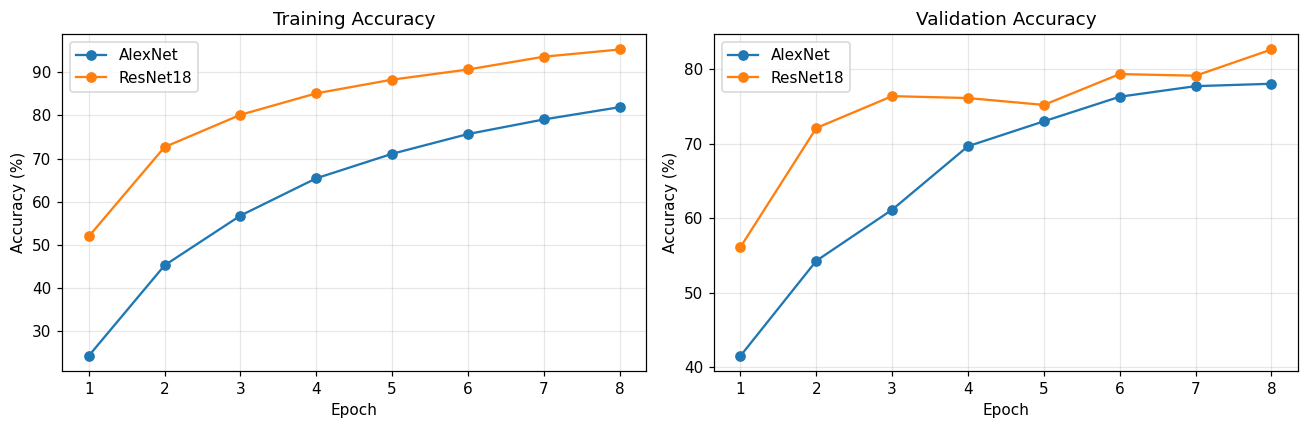

In [201]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert histories to DataFrames if needed
alexnet_history = pd.DataFrame(alexnet_history)
resnet_history = pd.DataFrame(resnet_history)

print("AlexNet columns:", alexnet_history.columns.tolist())
print("ResNet columns:", resnet_history.columns.tolist())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Training accuracy
for name, history in [
    ("AlexNet", alexnet_history),
    ("ResNet18", resnet_history)
]:
    axes[0].plot(
        history["epoch"],
        history["train_accuracy"],
        marker="o",
        label=name
    )

# Validation accuracy (only if recorded)
for name, history in [
    ("AlexNet", alexnet_history),
    ("ResNet18", resnet_history)
]:
    if "val_accuracy" in history.columns and history["val_accuracy"].notna().any():
        axes[1].plot(
            history["epoch"],
            history["val_accuracy"],
            marker="o",
            label=name
        )

axes[0].set_title("Training Accuracy")
axes[1].set_title("Validation Accuracy")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy (%)")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
savefig(fig, "t2_accuracy_comparison")
plt.show()

**Evaluate the selected models on the reserved official test set:** We run evaluation without gradient updates. These results describe the frozen baseline models, and they are not used to choose the Task 3 hyperparameters.

In [202]:
criterion = nn.CrossEntropyLoss()

for name, trained_model in [
    ("AlexNet", alexnet),
    ("ResNet18", resnet)
]:
    metrics = run_epoch(
        trained_model,
        SPLITS["test"],
        criterion
    )

    print(
        f"{name} | "
        f"Test Accuracy: {metrics['accuracy']:.2f}% | "
        f"Test Loss: {metrics['loss']:.4f}"
    )

AlexNet | Test Accuracy: 77.95% | Test Loss: 0.6767
ResNet18 | Test Accuracy: 81.71% | Test Loss: 0.6316


**Look at what the convolutions learned:** The first-layer filters of both trained models are shown as small RGB patches (each 3 × 3 filter is rescaled to the full colour range). We then pass one test image through both networks and show the eight most active channels after an early layer and after a deep layer. Early channels should still look like the image (edges, colour regions), while deep channels at 8 × 8 resolution respond to larger parts of the object.

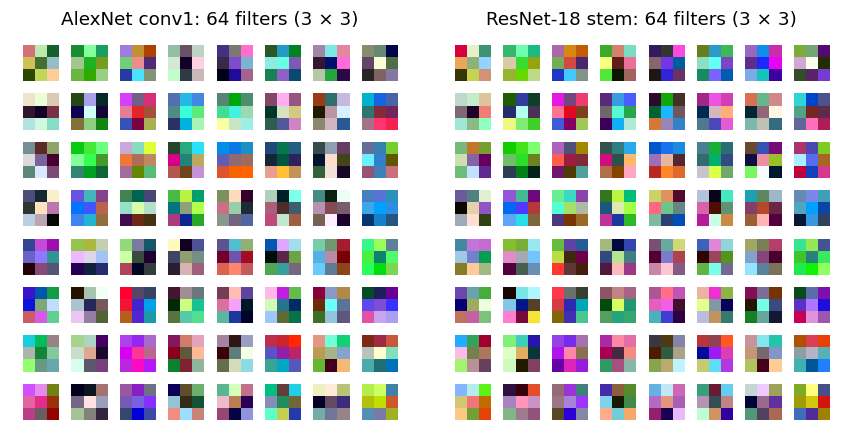

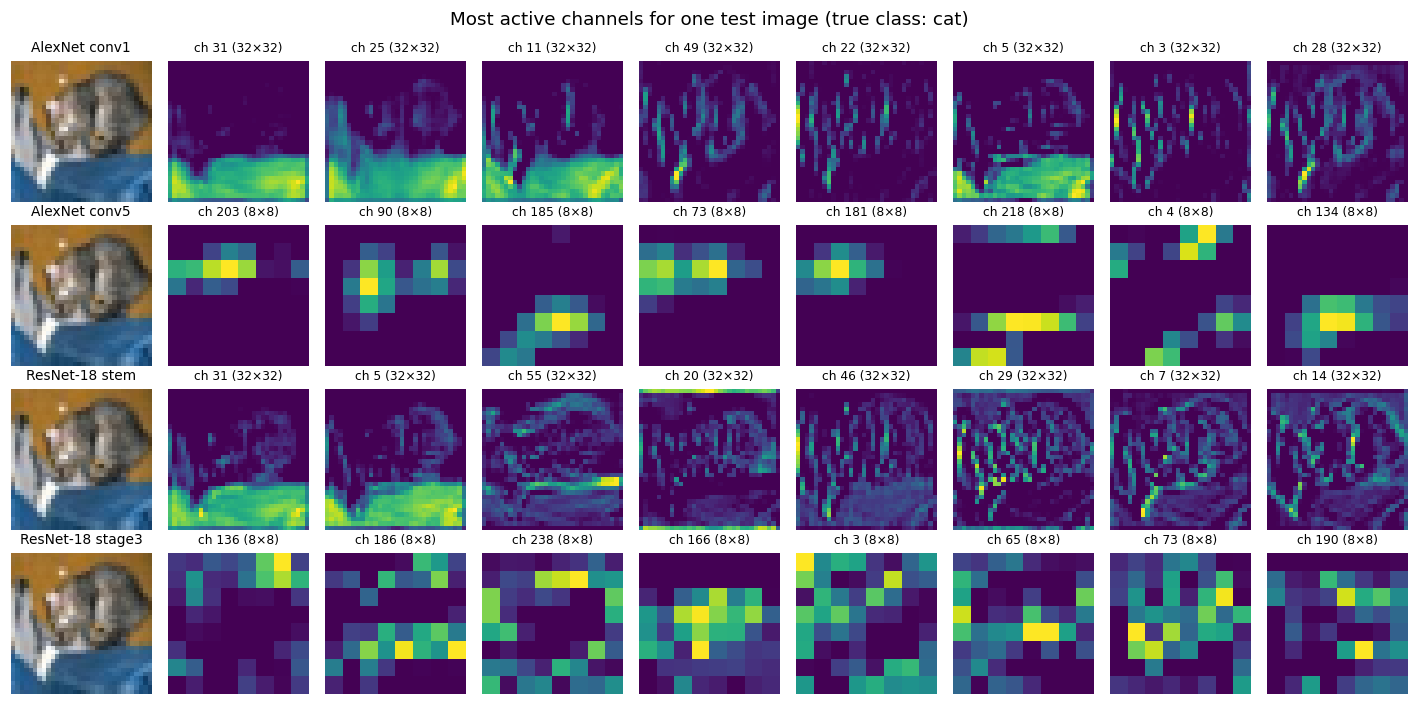

In [203]:
from torchvision.utils import make_grid


def filter_grid(weight):
    w = weight.detach().cpu()
    low = w.amin(dim=(1, 2, 3), keepdim=True)
    high = w.amax(dim=(1, 2, 3), keepdim=True)
    w = (w - low) / (high - low + 1e-8)
    return make_grid(w, nrow=8, padding=1, pad_value=1).permute(1, 2, 0)


fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, (name, weight) in zip(axes, [
    ("AlexNet conv1", alexnet.features[0].weight),
    ("ResNet-18 stem", resnet.initial[0].weight),
]):
    ax.imshow(filter_grid(weight), interpolation="nearest")
    ax.set_title(f"{name}: 64 filters (3 × 3)")
    ax.axis("off")

plt.tight_layout()
savefig(fig, "t2_first_layer_filters")
plt.show()


def capture(model, module, image):
    saved = {}
    handle = module.register_forward_hook(lambda m, i, o: saved.update(out=o.detach()))
    model.eval()
    with torch.no_grad():
        model(image)
    handle.remove()
    return saved["out"][0].cpu()


image_index = 0
image = to_float(SPLITS["test"].x[image_index:image_index + 1])
image_norm = (image - mean) / std
true_label = CLASSES[SPLITS["test"].y[image_index].item()]

rows = [
    ("AlexNet conv1", alexnet, alexnet.features[1]),
    ("AlexNet conv5", alexnet, alexnet.features[11]),
    ("ResNet-18 stem", resnet, resnet.initial),
    ("ResNet-18 stage3", resnet, resnet.stage3),
]

fig, axes = plt.subplots(len(rows), 9, figsize=(13, 6.5))
for r, (name, model, module) in enumerate(rows):
    maps = capture(model, module, image_norm)
    top = maps.mean(dim=(1, 2)).topk(8).indices

    axes[r, 0].imshow(image[0].cpu().permute(1, 2, 0))
    axes[r, 0].set_title(name, fontsize=9)
    axes[r, 0].axis("off")

    for j, channel in enumerate(top.tolist()):
        axes[r, j + 1].imshow(maps[channel], cmap="viridis")
        axes[r, j + 1].set_title(
            f"ch {channel} ({maps.shape[1]}×{maps.shape[2]})", fontsize=8
        )
        axes[r, j + 1].axis("off")

fig.suptitle(f"Most active channels for one test image (true class: {true_label})")
plt.tight_layout()
savefig(fig, "t2_feature_maps")
plt.show()

**What the filters and feature maps show:** With 3 × 3 kernels the first-layer filters are too small to look like the clean Gabor-like edges known from ImageNet models with 11 × 11 kernels. Most are colour-contrast patterns: one colour on one side and its opposite on the other, or a single dominant colour. In the feature maps of the cat image, the early channels of both networks still show the outline of the cat, the edge of the blanket and the background, so they work as edge and colour-region detectors. After AlexNet's fifth convolution and ResNet-18's third stage the maps are 8 × 8, and each active channel lights up for a few regions rather than for edges. ResNet-18's stage-3 activations are spread over more of the image than AlexNet's conv5, which responds to one or two small regions. This is one image and the top eight channels only, so it illustrates the hierarchy and does not measure it.

**Interpretation of the adaptations:** In AlexNet, stacked convolutions discover localized patterns and pooling reduces spatial dimensions, and its fully connected layers use the flattened 4,096-feature representation. ResNet uses convolutional residual blocks and identity/projection shortcuts to support gradient flow through deeper networks. Both output ten logits, and softmax is only needed for probability interpretation, not for `CrossEntropyLoss`. The shared data preparation and optimizer help make the model comparison controlled.

## Task 3. Investigate capacity and regularization
### B9. Vary classifier width
**Create a controlled AlexNet variant:** The five convolutional layers remain unchanged, while two fully connected widths and the dropout probability are parameters. Separately named model classes keep the Task 2 reference architecture distinct from the experimental variants.

In [204]:
class AlexNet3(nn.Module):
    def __init__(self, fc1=1024, fc2=512, dropout=0.5):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 192, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(192, 384, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(384, 256, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(4096, fc1),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(fc1, fc2),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(fc2, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

**Count trainable parameters:** Width changes affect the number of connections and therefore the model size, memory use, and training cost.

In [205]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

**Compare the small, baseline, and large configurations:** The classifier heads are 256 → 128, 1,024 → 512, and 2,048 → 1,024 respectively, all with the same convolutions and ten-class output.

In [206]:
small = AlexNet3(fc1=256, fc2=128)
baseline = AlexNet3(fc1=1024, fc2=512)
large = AlexNet3(fc1=2048, fc2=1024)

print("Small:", count_parameters(small))
print("Baseline:", count_parameters(baseline))
print("Large:", count_parameters(large))

Small: 3334602
Baseline: 6976842
Large: 12750666


**Train the small-capacity configuration:** Keep the data split, learning rate, optimizer, eight-epoch budget, dropout 0.5, and weight decay 0.0005 fixed, so only classifier width changes.

In [207]:
set_seed(BASE_SEED)

small_model, small_history = train_model(
    "t3_alexnet_small",
    AlexNet3(fc1=256, fc2=128, dropout=0.5),
    EPOCHS
)

t3_alexnet_small: Starting new training
t3_alexnet_small | Epoch 1/8 | Train: 22.01% | Val: 37.82% | Time: 9.1s | Peak GPU Memory: 1974.1 MB
t3_alexnet_small | Epoch 2/8 | Train: 40.33% | Val: 50.46% | Time: 9.1s | Peak GPU Memory: 1971.0 MB
t3_alexnet_small | Epoch 3/8 | Train: 51.99% | Val: 60.56% | Time: 9.2s | Peak GPU Memory: 1971.0 MB
t3_alexnet_small | Epoch 4/8 | Train: 60.48% | Val: 64.04% | Time: 9.1s | Peak GPU Memory: 1971.0 MB
t3_alexnet_small | Epoch 5/8 | Train: 66.24% | Val: 69.06% | Time: 9.1s | Peak GPU Memory: 1971.0 MB
t3_alexnet_small | Epoch 6/8 | Train: 70.76% | Val: 72.54% | Time: 9.0s | Peak GPU Memory: 1971.0 MB
t3_alexnet_small | Epoch 7/8 | Train: 74.44% | Val: 73.24% | Time: 9.0s | Peak GPU Memory: 1971.0 MB
t3_alexnet_small | Epoch 8/8 | Train: 77.20% | Val: 76.72% | Time: 9.0s | Peak GPU Memory: 1971.0 MB
t3_alexnet_small: Loaded best checkpoint (epoch 8)


**Train the baseline-capacity configuration:** This uses the original AlexNet classifier width and serves as the shared reference for the capacity, weight-decay, and dropout experiments.

In [208]:
set_seed(BASE_SEED)

baseline_model, baseline_history = train_model(
    "t3_alexnet_baseline",
    AlexNet3(fc1=1024, fc2=512, dropout=0.5),
    EPOCHS
)

t3_alexnet_baseline: Starting new training
t3_alexnet_baseline | Epoch 1/8 | Train: 24.24% | Val: 42.04% | Time: 10.1s | Peak GPU Memory: 2041.1 MB
t3_alexnet_baseline | Epoch 2/8 | Train: 45.28% | Val: 54.12% | Time: 10.0s | Peak GPU Memory: 2040.1 MB
t3_alexnet_baseline | Epoch 3/8 | Train: 57.55% | Val: 61.48% | Time: 9.9s | Peak GPU Memory: 2041.4 MB
t3_alexnet_baseline | Epoch 4/8 | Train: 65.70% | Val: 68.60% | Time: 10.0s | Peak GPU Memory: 2041.4 MB
t3_alexnet_baseline | Epoch 5/8 | Train: 71.36% | Val: 73.18% | Time: 10.0s | Peak GPU Memory: 2041.4 MB
t3_alexnet_baseline | Epoch 6/8 | Train: 75.80% | Val: 76.22% | Time: 9.9s | Peak GPU Memory: 2041.4 MB
t3_alexnet_baseline | Epoch 7/8 | Train: 79.24% | Val: 77.74% | Time: 9.9s | Peak GPU Memory: 2041.4 MB
t3_alexnet_baseline | Epoch 8/8 | Train: 82.22% | Val: 78.56% | Time: 9.9s | Peak GPU Memory: 2041.4 MB
t3_alexnet_baseline: Loaded best checkpoint (epoch 8)


**Train the larger-capacity configuration:** Adding width increases trainable connections, but the effect on generalization must be judged on validation results rather than parameter count alone.

In [82]:
set_seed(BASE_SEED)

large_model, large_history = train_model(
    "t3_alexnet_large",
    AlexNet3(fc1=2048, fc2=1024, dropout=0.5),
    EPOCHS
)

t3_alexnet_large: Starting new training
t3_alexnet_large | Epoch 1/8 | Train: 25.79% | Val: 44.14% | Time: 11.2s | Peak GPU Memory: 801.2 MB
t3_alexnet_large | Epoch 2/8 | Train: 47.41% | Val: 55.34% | Time: 11.4s | Peak GPU Memory: 799.1 MB
t3_alexnet_large | Epoch 3/8 | Train: 59.05% | Val: 63.08% | Time: 11.2s | Peak GPU Memory: 799.1 MB
t3_alexnet_large | Epoch 4/8 | Train: 68.04% | Val: 69.64% | Time: 11.2s | Peak GPU Memory: 799.1 MB
t3_alexnet_large | Epoch 5/8 | Train: 73.04% | Val: 73.84% | Time: 11.2s | Peak GPU Memory: 799.1 MB
t3_alexnet_large | Epoch 6/8 | Train: 77.17% | Val: 78.24% | Time: 11.2s | Peak GPU Memory: 799.1 MB
t3_alexnet_large | Epoch 7/8 | Train: 80.51% | Val: 77.94% | Time: 11.2s | Peak GPU Memory: 799.1 MB
t3_alexnet_large | Epoch 8/8 | Train: 83.42% | Val: 79.06% | Time: 11.2s | Peak GPU Memory: 799.1 MB
t3_alexnet_large: Loaded best checkpoint (epoch 8)


**Compare capacity through accuracy curves:** The relative training and validation trajectories show whether additional capacity improves fitting or produces a widening gap.

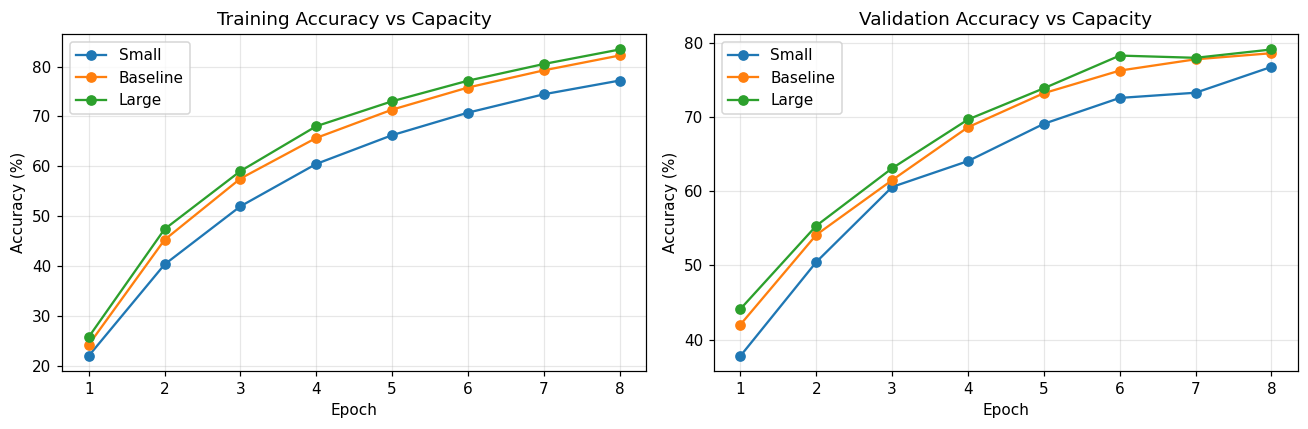

In [83]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

histories = {
    "Small": small_history,
    "Baseline": baseline_history,
    "Large": large_history
}

for name, history in histories.items():
    axes[0].plot(
        history["epoch"],
        history["train_accuracy"],
        marker="o",
        label=name
    )

    axes[1].plot(
        history["epoch"],
        history["val_accuracy"],
        marker="o",
        label=name
    )

axes[0].set_title("Training Accuracy vs Capacity")
axes[1].set_title("Validation Accuracy vs Capacity")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy (%)")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
savefig(fig, "t3_capacity_accuracy")
plt.show()

**Compare capacity through loss curves:** Cross-entropy is sensitive to prediction confidence and can reveal overfitting even when accuracy changes little.

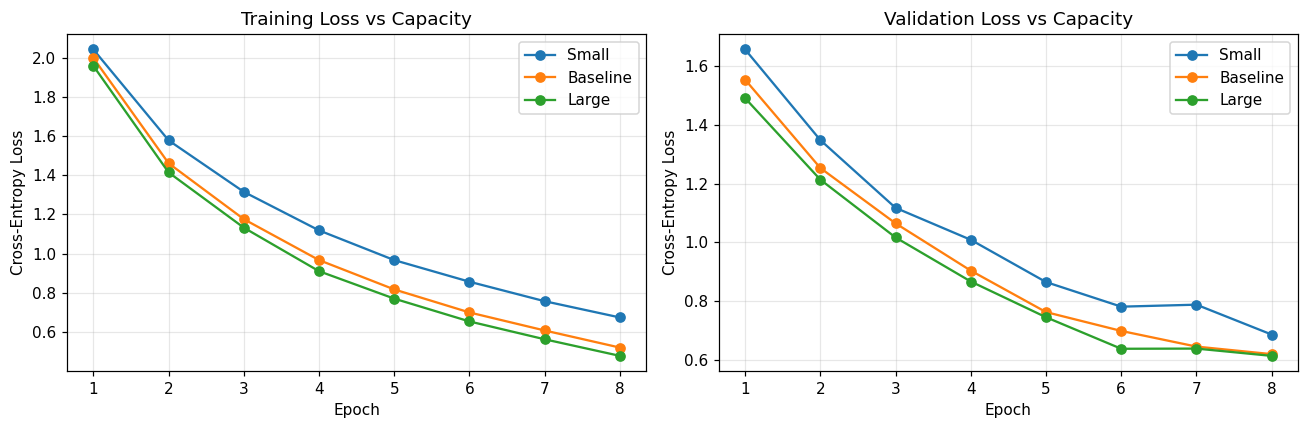

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, history in histories.items():
    axes[0].plot(
        history["epoch"],
        history["train_loss"],
        marker="o",
        label=name
    )

    axes[1].plot(
        history["epoch"],
        history["val_loss"],
        marker="o",
        label=name
    )

axes[0].set_title("Training Loss vs Capacity")
axes[1].set_title("Validation Loss vs Capacity")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-Entropy Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
savefig(fig, "t3_capacity_loss")
plt.show()

### B10. Vary L2-style weight decay
**Remove weight decay:** With PyTorch SGD, `weight_decay` implements the usual L2 penalty in the weight update. The baseline architecture and dropout stay fixed.

In [85]:
set_seed(BASE_SEED)

no_l2_model, no_l2_history = train_model(
    "t3_alexnet_no_l2",
    AlexNet3(fc1=1024, fc2=512, dropout=0.5),
    EPOCHS,
    weight_decay=0.0
)

t3_alexnet_no_l2: Starting new training
t3_alexnet_no_l2 | Epoch 1/8 | Train: 24.29% | Val: 42.32% | Time: 9.6s | Peak GPU Memory: 833.0 MB
t3_alexnet_no_l2 | Epoch 2/8 | Train: 45.92% | Val: 54.80% | Time: 9.6s | Peak GPU Memory: 832.1 MB
t3_alexnet_no_l2 | Epoch 3/8 | Train: 58.46% | Val: 63.16% | Time: 9.7s | Peak GPU Memory: 832.3 MB
t3_alexnet_no_l2 | Epoch 4/8 | Train: 66.88% | Val: 70.08% | Time: 9.7s | Peak GPU Memory: 832.5 MB
t3_alexnet_no_l2 | Epoch 5/8 | Train: 72.70% | Val: 74.68% | Time: 9.6s | Peak GPU Memory: 832.3 MB
t3_alexnet_no_l2 | Epoch 6/8 | Train: 77.02% | Val: 75.34% | Time: 9.6s | Peak GPU Memory: 832.5 MB
t3_alexnet_no_l2 | Epoch 7/8 | Train: 80.72% | Val: 78.44% | Time: 9.6s | Peak GPU Memory: 832.3 MB
t3_alexnet_no_l2 | Epoch 8/8 | Train: 83.92% | Val: 79.94% | Time: 9.6s | Peak GPU Memory: 832.5 MB
t3_alexnet_no_l2: Loaded best checkpoint (epoch 8)


**Apply stronger weight decay:** Weight decay 0.005 is compared with 0 and the shared 0.0005 baseline to test whether strong regularization hinders fitting within eight epochs.

In [ ]:
set_seed(BASE_SEED)

strong_l2_model, strong_l2_history = train_model(
    "t3_alexnet_strong_l2",
    AlexNet3(fc1=1024, fc2=512, dropout=0.5),
    EPOCHS,
    weight_decay=0.005
)

t3_alexnet_strong_l2: Starting new training
t3_alexnet_strong_l2 | Epoch 1/8 | Train: 20.70% | Val: 37.40% | Time: 9.8s | Peak GPU Memory: 817.3 MB
t3_alexnet_strong_l2 | Epoch 2/8 | Train: 39.47% | Val: 44.40% | Time: 9.8s | Peak GPU Memory: 816.9 MB
t3_alexnet_strong_l2 | Epoch 3/8 | Train: 48.19% | Val: 53.90% | Time: 9.8s | Peak GPU Memory: 816.8 MB
t3_alexnet_strong_l2 | Epoch 4/8 | Train: 55.17% | Val: 58.84% | Time: 9.8s | Peak GPU Memory: 816.8 MB
t3_alexnet_strong_l2 | Epoch 5/8 | Train: 59.24% | Val: 60.48% | Time: 9.9s | Peak GPU Memory: 816.8 MB
t3_alexnet_strong_l2 | Epoch 6/8 | Train: 62.70% | Val: 65.16% | Time: 9.9s | Peak GPU Memory: 816.8 MB
t3_alexnet_strong_l2 | Epoch 7/8 | Train: 65.54% | Val: 64.44% | Time: 10.1s | Peak GPU Memory: 816.8 MB
t3_alexnet_strong_l2 | Epoch 8/8 | Train: 67.64% | Val: 69.28% | Time: 9.9s | Peak GPU Memory: 816.8 MB
t3_alexnet_strong_l2: Loaded best checkpoint (epoch 8)


**Plot the L2 comparison:** A controlled comparison places train/validation accuracy and loss on the same axes. Strong regularization can reduce both training and validation performance rather than improve generalization.

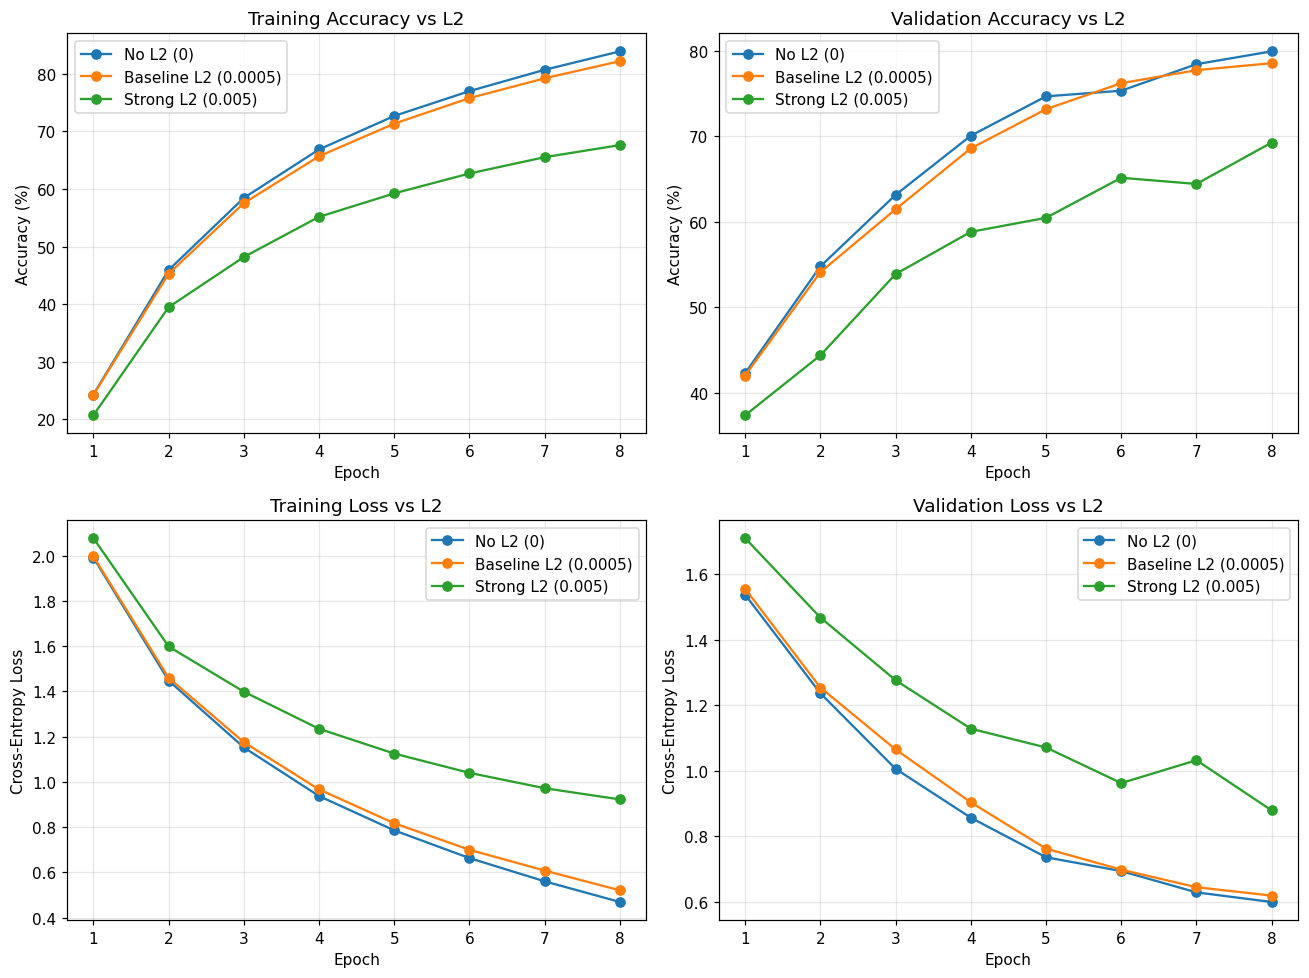

In [ ]:
l2_histories = {
    "No L2 (0)": no_l2_history,
    "Baseline L2 (0.0005)": baseline_history,
    "Strong L2 (0.005)": strong_l2_history
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for name, history in l2_histories.items():
    axes[0, 0].plot(history["epoch"], history["train_accuracy"], marker="o", label=name)
    axes[0, 1].plot(history["epoch"], history["val_accuracy"], marker="o", label=name)
    axes[1, 0].plot(history["epoch"], history["train_loss"], marker="o", label=name)
    axes[1, 1].plot(history["epoch"], history["val_loss"], marker="o", label=name)

axes[0, 0].set_title("Training Accuracy vs L2")
axes[0, 1].set_title("Validation Accuracy vs L2")
axes[1, 0].set_title("Training Loss vs L2")
axes[1, 1].set_title("Validation Loss vs L2")

for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy (%)" if "Accuracy" in ax.get_title() else "Cross-Entropy Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
savefig(fig, "t3_l2_comparison")
plt.show()

### B11. Vary dropout
**Train without dropout:** Dropout sets randomly selected hidden activations to zero only during training. The convolutional stack, classifier width, and weight decay remain fixed.

In [ ]:
set_seed(BASE_SEED)

no_dropout_model, no_dropout_history = train_model(
    "t3_alexnet_dropout_0",
    AlexNet3(fc1=1024, fc2=512, dropout=0.0),
    EPOCHS,
    weight_decay=0.0005
)

t3_alexnet_dropout_0: Starting new training
t3_alexnet_dropout_0 | Epoch 1/8 | Train: 27.38% | Val: 44.10% | Time: 9.9s | Peak GPU Memory: 873.0 MB
t3_alexnet_dropout_0 | Epoch 2/8 | Train: 49.68% | Val: 53.84% | Time: 9.8s | Peak GPU Memory: 871.8 MB
t3_alexnet_dropout_0 | Epoch 3/8 | Train: 61.22% | Val: 65.02% | Time: 9.9s | Peak GPU Memory: 872.3 MB
t3_alexnet_dropout_0 | Epoch 4/8 | Train: 70.10% | Val: 69.62% | Time: 9.8s | Peak GPU Memory: 871.8 MB
t3_alexnet_dropout_0 | Epoch 5/8 | Train: 74.90% | Val: 74.98% | Time: 9.9s | Peak GPU Memory: 872.3 MB
t3_alexnet_dropout_0 | Epoch 6/8 | Train: 79.01% | Val: 77.34% | Time: 9.9s | Peak GPU Memory: 871.8 MB
t3_alexnet_dropout_0 | Epoch 7/8 | Train: 82.52% | Val: 78.64% | Time: 9.8s | Peak GPU Memory: 872.3 MB
t3_alexnet_dropout_0 | Epoch 8/8 | Train: 85.37% | Val: 77.64% | Time: 9.9s | Peak GPU Memory: 871.8 MB
t3_alexnet_dropout_0: Loaded best checkpoint (epoch 7)


**Train with dropout probability 0.3:** We compare no dropout, 0.3, and the already-trained 0.5 baseline under the same compute budget.

In [89]:
set_seed(BASE_SEED)

dropout_03_model, dropout_03_history = train_model(
    "t3_alexnet_dropout_03",
    AlexNet3(fc1=1024, fc2=512, dropout=0.3),
    EPOCHS,
    weight_decay=0.0005
)

t3_alexnet_dropout_03: Starting new training
t3_alexnet_dropout_03 | Epoch 1/8 | Train: 26.05% | Val: 44.12% | Time: 9.9s | Peak GPU Memory: 992.5 MB
t3_alexnet_dropout_03 | Epoch 2/8 | Train: 47.89% | Val: 53.48% | Time: 10.0s | Peak GPU Memory: 993.8 MB
t3_alexnet_dropout_03 | Epoch 3/8 | Train: 59.47% | Val: 62.90% | Time: 10.0s | Peak GPU Memory: 993.1 MB
t3_alexnet_dropout_03 | Epoch 4/8 | Train: 67.85% | Val: 68.82% | Time: 10.0s | Peak GPU Memory: 993.1 MB
t3_alexnet_dropout_03 | Epoch 5/8 | Train: 73.27% | Val: 74.18% | Time: 10.0s | Peak GPU Memory: 993.1 MB
t3_alexnet_dropout_03 | Epoch 6/8 | Train: 77.16% | Val: 75.84% | Time: 9.9s | Peak GPU Memory: 993.1 MB
t3_alexnet_dropout_03 | Epoch 7/8 | Train: 80.55% | Val: 78.46% | Time: 10.0s | Peak GPU Memory: 993.1 MB
t3_alexnet_dropout_03 | Epoch 8/8 | Train: 83.53% | Val: 78.22% | Time: 10.1s | Peak GPU Memory: 993.1 MB
t3_alexnet_dropout_03: Loaded best checkpoint (epoch 7)


**Plot the dropout comparison:** More dropout can lower training accuracy because optimization sees a noisier network. The key question is whether validation metrics improve or become more stable.

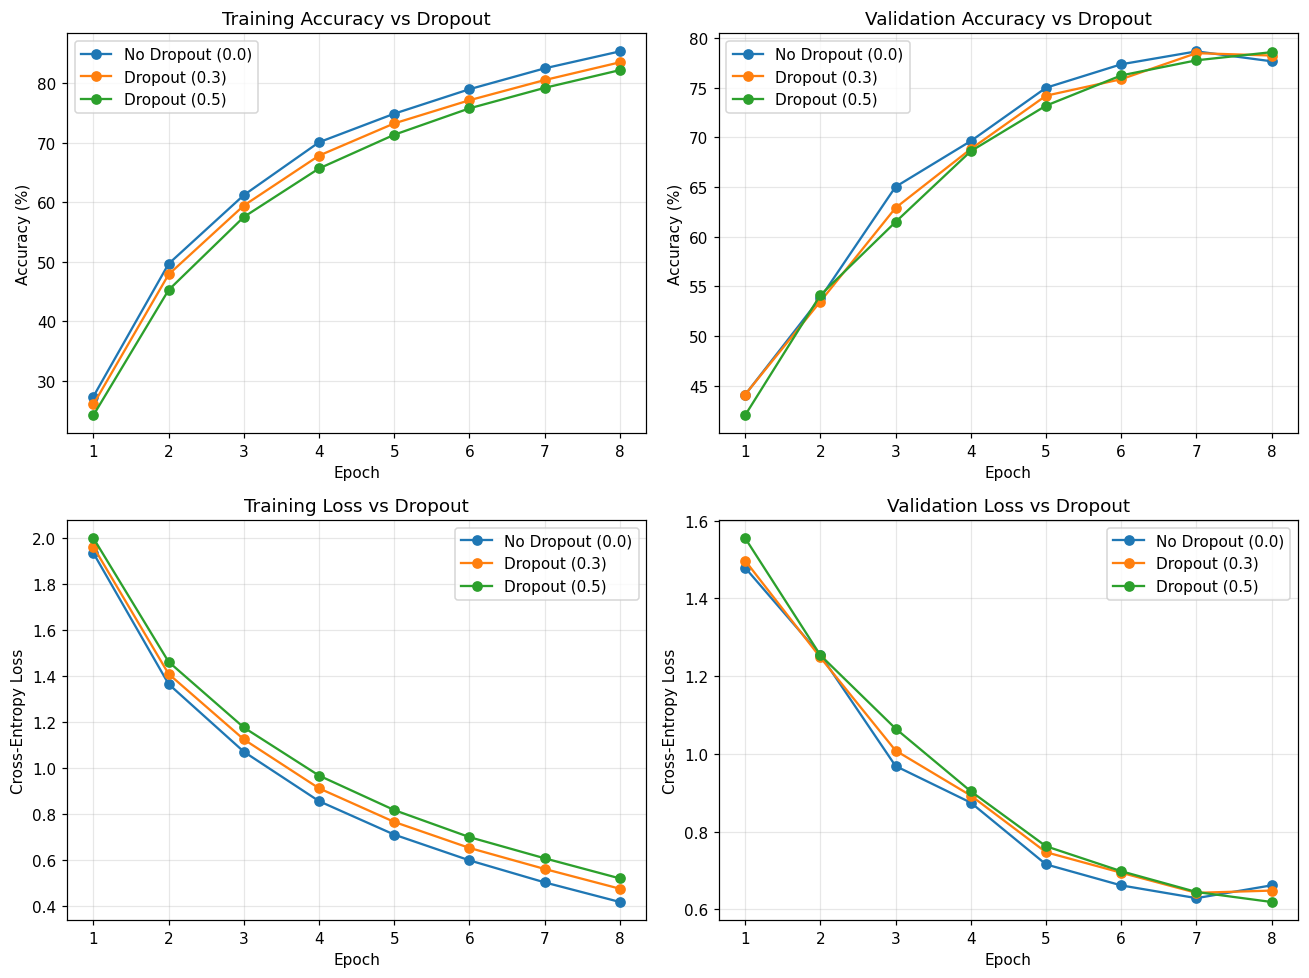

In [ ]:
dropout_histories = {
    "No Dropout (0.0)": no_dropout_history,
    "Dropout (0.3)": dropout_03_history,
    "Dropout (0.5)": baseline_history
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for name, history in dropout_histories.items():
    axes[0, 0].plot(history["epoch"], history["train_accuracy"], marker="o", label=name)
    axes[0, 1].plot(history["epoch"], history["val_accuracy"], marker="o", label=name)
    axes[1, 0].plot(history["epoch"], history["train_loss"], marker="o", label=name)
    axes[1, 1].plot(history["epoch"], history["val_loss"], marker="o", label=name)

axes[0, 0].set_title("Training Accuracy vs Dropout")
axes[0, 1].set_title("Validation Accuracy vs Dropout")
axes[1, 0].set_title("Training Loss vs Dropout")
axes[1, 1].set_title("Validation Loss vs Dropout")

for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy (%)" if "Accuracy" in ax.get_title() else "Cross-Entropy Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
savefig(fig, "t3_dropout_comparison")
plt.show()

**Summarize controlled configurations:** Use the best validation epoch for selection, the final training accuracy as a diagnostic, parameter counts for capacity, and the logged total training seconds for cost. The shared baseline need not be repeated as a separate training run.

In [ ]:
experiments = [
    ("Capacity", "Small", small_model, small_history),
    ("Capacity", "Baseline", baseline_model, baseline_history),
    ("Capacity", "Large", large_model, large_history),
    ("L2", "No L2", no_l2_model, no_l2_history),
    ("L2", "Strong L2", strong_l2_model, strong_l2_history),
    ("Dropout", "No Dropout", no_dropout_model, no_dropout_history),
    ("Dropout", "Dropout 0.3", dropout_03_model, dropout_03_history),
]

summary = []

for group, name, model, history in experiments:
    best_idx = history["val_accuracy"].idxmax()

    summary.append({
        "Experiment": group,
        "Configuration": name,
        "Parameters": count_parameters(model),
        "Best Val Accuracy (%)": history.loc[best_idx, "val_accuracy"],
        "Best Epoch": int(history.loc[best_idx, "epoch"]),
        "Final Train Accuracy (%)": history["train_accuracy"].iloc[-1],
        "Training Time (s)": history["seconds"].sum(),
    })

summary_df = pd.DataFrame(summary)
display(summary_df)

,Experiment,Configuration,Parameters,Best Val Accuracy (%),Best Epoch,Final Train Accuracy (%),Training Time (s)
0,Capacity,Small,3334602,76.72,8,77.1956,72.4190
1,Capacity,Baseline,6976842,78.56,8,82.2200,78.9318
2,Capacity,Large,12750666,79.06,8,83.4200,88.8313
3,L2,No L2,6976842,79.94,8,83.9200,75.2025
4,L2,Strong L2,6976842,69.28,8,67.6378,79.0105
5,Dropout,No Dropout,6976842,78.64,7,85.3689,78.9271
6,Dropout,Dropout 0.3,6976842,78.46,7,83.5333,79.3755


### B11a. Interpret the recorded capacity and regularization results

The source experiments used eight epochs and one principal seed. The capacity comparison measured **3,334,602** parameters / **76.72%** best validation accuracy / **72.60 s** training for the small model, **6,976,842** / **78.56%** / **79.64 s** for the baseline and **12,750,666** / **79.06%** / **89.90 s** for the large model. More width helps, but less and less: +1.84 points from small to baseline, only +0.50 from baseline to large, for 1.83 times the parameters and 12.9% more training time. All three still reach their best validation accuracy in the last epoch, so none of them is clearly overfitting yet, although the small model fits the training data least (77.20%), which points to some underfitting.

For weight decay with the baseline width and dropout 0.5, removing weight decay (`0`) reached **79.94%** best validation accuracy, the shared baseline (`0.0005`) reached **78.56%**, and strong decay (`0.005`) reached **69.28%**. Strong decay keeps training accuracy at 67.64%, so it causes underfitting within this budget. The +1.38 points without weight decay is about the size of the seed-to-seed spread measured in Task 6 (about 1.2 points), so it is not a reliable improvement.

For dropout, **0.0**, **0.3**, and **0.5** produced best validation accuracies of **78.64%**, **78.46%**, and **78.56%**. Without dropout, training accuracy reached **85.37%** while validation accuracy fell from 78.64% to 77.64% in the last epoch, the first sign of overfitting in this study. The train–validation gap at the last epoch shrinks from **7.73** points (no dropout) to **5.31** (0.3) and **3.66** (0.5). Dropout changes how the model learns more than how good it ends up after eight epochs.

**Controlled variables:** Across each comparison, the training split, preprocessing, batch size, optimizer, learning rate, momentum, seed and eight-epoch budget were held fixed. Capacity experiments changed only classifier width, L2 experiments only weight decay and dropout experiments only the dropout probability. Weight decay and dropout do not change the parameter count or the training time, so the small time differences are run-to-run noise. (The training times here are from the Task 6 cost table of this run, while the summary table above shows the previous run's times, which differ by about 1%.)

## Task 4. Evaluate robustness
### B12. Train with standard augmentation
**Train a comparable augmented AlexNet:** Standard random crop and horizontal flip are applied before normalization to the training batches only. The non-augmented Task 3 baseline serves as the reference.

In [ ]:
set_seed(BASE_SEED)

augmented_model, augmented_history = train_model(
    "t4_alexnet_augmented",
    AlexNet3(fc1=1024, fc2=512, dropout=0.5),
    EPOCHS,
    weight_decay=0.0005,
    augmentation="standard"
)

t4_alexnet_augmented: Starting new training
t4_alexnet_augmented | Epoch 1/8 | Train: 21.82% | Val: 38.50% | Time: 10.1s | Peak GPU Memory: 979.4 MB
t4_alexnet_augmented | Epoch 2/8 | Train: 40.58% | Val: 49.48% | Time: 10.1s | Peak GPU Memory: 978.2 MB
t4_alexnet_augmented | Epoch 3/8 | Train: 50.63% | Val: 56.36% | Time: 10.1s | Peak GPU Memory: 978.2 MB
t4_alexnet_augmented | Epoch 4/8 | Train: 58.43% | Val: 62.82% | Time: 10.2s | Peak GPU Memory: 978.2 MB
t4_alexnet_augmented | Epoch 5/8 | Train: 64.29% | Val: 67.58% | Time: 10.1s | Peak GPU Memory: 978.2 MB
t4_alexnet_augmented | Epoch 6/8 | Train: 68.04% | Val: 71.16% | Time: 10.1s | Peak GPU Memory: 978.2 MB
t4_alexnet_augmented | Epoch 7/8 | Train: 71.68% | Val: 75.76% | Time: 10.2s | Peak GPU Memory: 978.2 MB
t4_alexnet_augmented | Epoch 8/8 | Train: 74.41% | Val: 77.56% | Time: 10.1s | Peak GPU Memory: 978.2 MB
t4_alexnet_augmented: Loaded best checkpoint (epoch 8)


**Create a reproducible corrupted validation evaluation set:** Keep the same 5,000 validation IDs and class labels, then make a clean version, a fixed 15° rotation, and additive Gaussian noise with standard deviation 0.06. These are evaluation interventions, not additional training examples.

In [ ]:
# Fixed evaluation images
eval_images = to_float(SPLITS["val"].x)
eval_labels = SPLITS["val"].y

# Reproducible noise
noise_gen = torch.Generator().manual_seed(42)

# Clean
clean_images = eval_images.clone()

# Rotation: 15 degrees
n = len(eval_images)
angles = torch.full((n,), 15.0)
shears = torch.zeros(n)

rotated_images = affine_batch(
    eval_images.clone(), angles, shears
)

# Gaussian noise: sigma = 0.06
noise = torch.randn(
    eval_images.shape,
    generator=noise_gen
).to(eval_images.device) * 0.06

noisy_images = (eval_images + noise).clamp(0, 1)

corrupted_sets = {
    "Clean": clean_images,
    "Rotation 15°": rotated_images,
    "Gaussian Noise": noisy_images
}

print("Evaluation images:", len(eval_labels))
print("Conditions:", list(corrupted_sets.keys()))

Evaluation images: 5000
Conditions: ['Clean', 'Rotation 15°', 'Gaussian Noise']


**Measure clean and corrupted accuracy:** Both models see exactly the same clean, rotated, and noisy images. Normalize each transformed image once and record loss, accuracy, and evaluation time.

In [94]:
import time

def evaluate_robustness(model, images, labels, batch_size=64):
    model.eval()
    criterion = nn.CrossEntropyLoss()

    total_loss = 0.0
    correct = 0
    total = 0

    sync()
    start = time.perf_counter()

    with torch.no_grad():
        for i in range(0, len(images), batch_size):
            x = images[i:i + batch_size].to(device)
            y = labels[i:i + batch_size].to(device)

            # Normalize using training statistics
            x = (x - mean) / std

            outputs = model(x)
            loss = criterion(outputs, y)

            total_loss += loss.item() * len(y)
            correct += (outputs.argmax(dim=1) == y).sum().item()
            total += len(y)

    sync()

    return {
        "accuracy": 100 * correct / total,
        "loss": total_loss / total,
        "seconds": time.perf_counter() - start
    }


# Evaluate both models
results = []

models = {
    "Original AlexNet": baseline_model,
    "Augmented AlexNet": augmented_model
}

for model_name, model in models.items():
    for corruption_name, images in corrupted_sets.items():

        metrics = evaluate_robustness(
            model,
            images,
            eval_labels
        )

        results.append({
            "Model": model_name,
            "Condition": corruption_name,
            "Accuracy (%)": metrics["accuracy"],
            "Loss": metrics["loss"],
            "Time (s)": metrics["seconds"]
        })

robustness_df = pd.DataFrame(results)

display(robustness_df)

,Model,Condition,Accuracy (%),Loss,Time (s)
0,Original AlexNet,Clean,78.56,0.6189,0.3284
1,Original AlexNet,Rotation 15°,70.32,0.8910,0.3273
2,Original AlexNet,Gaussian Noise,66.38,1.0702,0.3291
3,Augmented AlexNet,Clean,77.56,0.6531,0.3348
4,Augmented AlexNet,Rotation 15°,68.44,0.9143,0.3345
5,Augmented AlexNet,Gaussian Noise,65.06,1.0123,0.3293


**Train with stronger augmentation:** The stronger condition includes crop, flip, randomly applied rotation and shear, and noise during training. Its purpose is to test whether matching corruption types in training helps generalization.

In [ ]:
set_seed(BASE_SEED)

strong_aug_model, strong_aug_history = train_model(
    "t4_alexnet_strong_aug",
    AlexNet3(fc1=1024, fc2=512, dropout=0.5),
    EPOCHS,
    weight_decay=0.0005,
    augmentation="strong"
)

t4_alexnet_strong_aug: Starting new training
t4_alexnet_strong_aug | Epoch 1/8 | Train: 21.38% | Val: 38.80% | Time: 11.5s | Peak GPU Memory: 1325.6 MB
t4_alexnet_strong_aug | Epoch 2/8 | Train: 38.59% | Val: 46.88% | Time: 11.4s | Peak GPU Memory: 1324.5 MB
t4_alexnet_strong_aug | Epoch 3/8 | Train: 48.08% | Val: 55.54% | Time: 11.5s | Peak GPU Memory: 1324.9 MB
t4_alexnet_strong_aug | Epoch 4/8 | Train: 54.95% | Val: 61.06% | Time: 11.8s | Peak GPU Memory: 1324.9 MB
t4_alexnet_strong_aug | Epoch 5/8 | Train: 60.29% | Val: 66.98% | Time: 11.7s | Peak GPU Memory: 1324.9 MB
t4_alexnet_strong_aug | Epoch 6/8 | Train: 64.36% | Val: 70.22% | Time: 11.9s | Peak GPU Memory: 1324.9 MB
t4_alexnet_strong_aug | Epoch 7/8 | Train: 67.42% | Val: 71.66% | Time: 12.3s | Peak GPU Memory: 1324.9 MB
t4_alexnet_strong_aug | Epoch 8/8 | Train: 70.36% | Val: 76.40% | Time: 11.8s | Peak GPU Memory: 1324.9 MB
t4_alexnet_strong_aug: Loaded best checkpoint (epoch 8)


**Evaluate the strongly augmented model on the same images:** Compare this third model with the no-augmentation and standard-augmentation conditions without regenerating the noise or rotation.

In [96]:
strong_results = []

for corruption_name, images in corrupted_sets.items():
    metrics = evaluate_robustness(
        strong_aug_model,
        images,
        eval_labels
    )

    strong_results.append({
        "Model": "Strong Augmented AlexNet",
        "Condition": corruption_name,
        "Accuracy (%)": metrics["accuracy"],
        "Loss": metrics["loss"],
        "Time (s)": metrics["seconds"]
    })

robustness_df = pd.concat(
    [robustness_df, pd.DataFrame(strong_results)],
    ignore_index=True
)

display(robustness_df)

,Model,Condition,Accuracy (%),Loss,Time (s)
0,Original AlexNet,Clean,78.56,0.6189,0.3284
1,Original AlexNet,Rotation 15°,70.32,0.8910,0.3273
2,Original AlexNet,Gaussian Noise,66.38,1.0702,0.3291
3,Augmented AlexNet,Clean,77.56,0.6531,0.3348
4,Augmented AlexNet,Rotation 15°,68.44,0.9143,0.3345
5,Augmented AlexNet,Gaussian Noise,65.06,1.0123,0.3293
6,Strong Augmented AlexNet,Clean,76.40,0.6996,0.3269
7,Strong Augmented AlexNet,Rotation 15°,71.86,0.8175,0.3305
8,Strong Augmented AlexNet,Gaussian Noise,73.74,0.7737,0.3317


**Visualize robustness across conditions:** Grouping accuracies by evaluation corruption shows the tradeoff between clean-image performance and robustness to the tested transformations.

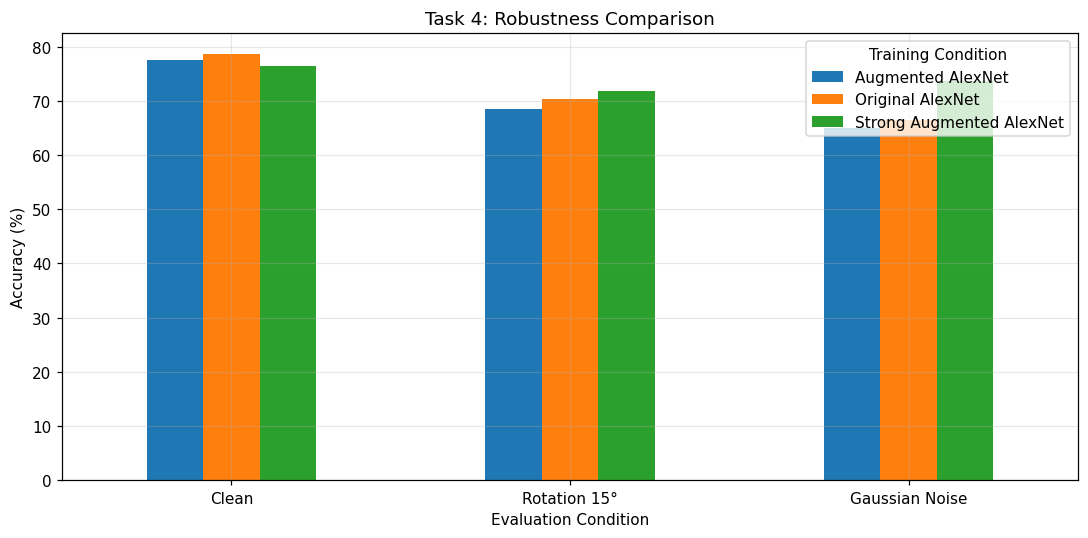

In [97]:
import matplotlib.pyplot as plt

accuracy_table = robustness_df.pivot(
    index="Condition",
    columns="Model",
    values="Accuracy (%)"
)

accuracy_table = accuracy_table.loc[
    ["Clean", "Rotation 15°", "Gaussian Noise"]
]

ax = accuracy_table.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Task 4: Robustness Comparison")
ax.set_xlabel("Evaluation Condition")
ax.set_ylabel("Accuracy (%)")
ax.legend(title="Training Condition")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
savefig(plt.gcf(), "t4_robustness_comparison")
plt.show()

### B13. Analyse corruption-induced errors
**Count new classification mistakes:** A new error is a validation example that the model predicts correctly when clean but incorrectly after corruption. This is not the same as the overall accuracy drop, because some initially wrong predictions may also become correct.

In [209]:
def get_predictions(model, images, batch_size=64):
    model.eval()
    predictions = []

    with torch.no_grad():
        for i in range(0, len(images), batch_size):
            x = images[i:i + batch_size].to(device)
            x = (x - mean) / std

            outputs = model(x)
            predictions.append(outputs.argmax(dim=1).cpu())

    return torch.cat(predictions)


# Compare errors for the original and strongly augmented models
error_results = []

for model_name, model in [
    ("Original", baseline_model),
    ("Strong Augmentation", strong_aug_model)
]:
    clean_preds = get_predictions(model, corrupted_sets["Clean"])

    for condition in ["Rotation 15°", "Gaussian Noise"]:
        corrupted_preds = get_predictions(
            model,
            corrupted_sets[condition]
        )

        labels = eval_labels.cpu()

        # Correct on clean image, wrong on corrupted image
        new_errors = (
            (clean_preds == labels) &
            (corrupted_preds != labels)
        ).sum().item()

        error_results.append({
            "Model": model_name,
            "Corruption": condition,
            "New Errors": new_errors,
            "New Error Rate (%)": 100 * new_errors / len(labels)
        })

error_df = pd.DataFrame(error_results)
display(error_df)

,Model,Corruption,New Errors,New Error Rate (%)
0,Original,Rotation 15°,647,12.94
1,Original,Gaussian Noise,732,14.64
2,Strong Augmentation,Rotation 15°,443,8.86
3,Strong Augmentation,Gaussian Noise,252,5.04


**Inspect errors introduced by Gaussian noise:** Compare the same original and corrupted images, using their true and predicted class labels. Visually similar classes may be confused, but unrelated-class predictions can also occur under noise.

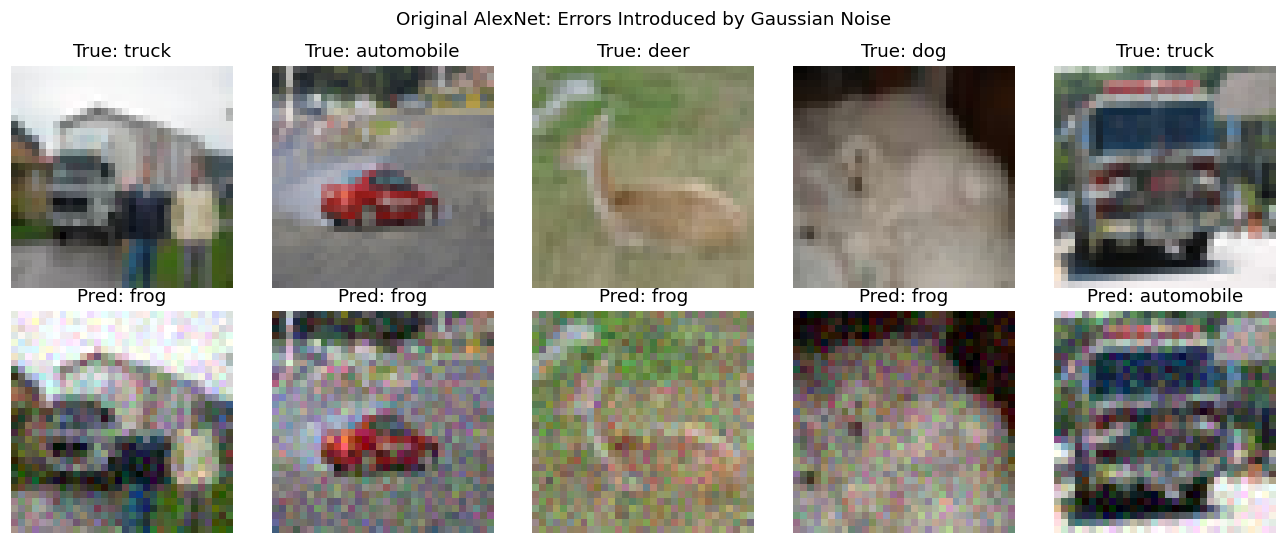

In [210]:
import matplotlib.pyplot as plt

condition = "Gaussian Noise"

clean_preds = get_predictions(baseline_model, corrupted_sets["Clean"])
corrupt_preds = get_predictions(baseline_model, corrupted_sets[condition])

labels = eval_labels.cpu()

# Images correct when clean but wrong after corruption
error_indices = torch.where(
    (clean_preds == labels) & (corrupt_preds != labels)
)[0][:5]

fig, axes = plt.subplots(2, len(error_indices), figsize=(12, 5))

for j, idx in enumerate(error_indices.tolist()):
    axes[0, j].imshow(corrupted_sets["Clean"][idx].cpu().permute(1, 2, 0))
    axes[0, j].set_title(f"True: {CLASSES[labels[idx].item()]}")
    axes[0, j].axis("off")

    axes[1, j].imshow(corrupted_sets[condition][idx].cpu().permute(1, 2, 0))
    axes[1, j].set_title(
        f"Pred: {CLASSES[corrupt_preds[idx].item()]}"
    )
    axes[1, j].axis("off")

fig.suptitle("Original AlexNet: Errors Introduced by Gaussian Noise")
plt.tight_layout()
savefig(fig, "t4_noise_error_examples")
plt.show()

**Inspect errors introduced by rotation:** The same comparison for the 15° rotation shows whether rotation causes the same kind of mistakes as noise.

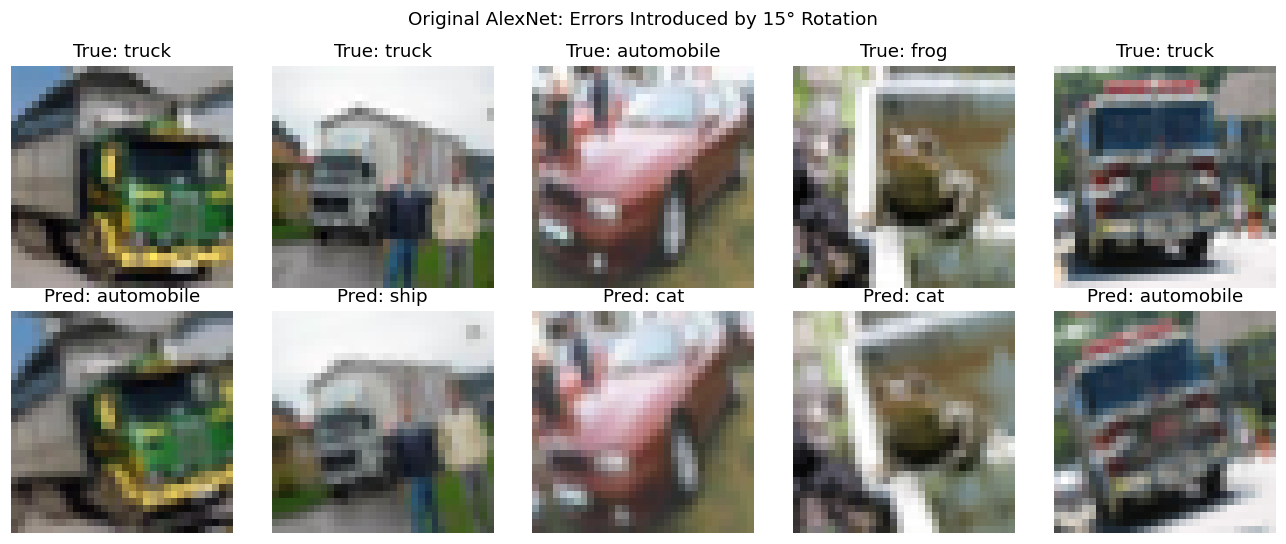

In [211]:
condition = "Rotation 15°"

clean_preds = get_predictions(baseline_model, corrupted_sets["Clean"])
corrupt_preds = get_predictions(baseline_model, corrupted_sets[condition])

labels = eval_labels.cpu()

# Images correct when clean but wrong after corruption
error_indices = torch.where(
    (clean_preds == labels) & (corrupt_preds != labels)
)[0][:5]

fig, axes = plt.subplots(2, len(error_indices), figsize=(12, 5))

for j, idx in enumerate(error_indices.tolist()):
    axes[0, j].imshow(corrupted_sets["Clean"][idx].cpu().permute(1, 2, 0))
    axes[0, j].set_title(f"True: {CLASSES[labels[idx].item()]}")
    axes[0, j].axis("off")

    axes[1, j].imshow(corrupted_sets[condition][idx].cpu().permute(1, 2, 0))
    axes[1, j].set_title(
        f"Pred: {CLASSES[corrupt_preds[idx].item()]}"
    )
    axes[1, j].axis("off")

fig.suptitle("Original AlexNet: Errors Introduced by 15° Rotation")
plt.tight_layout()
savefig(fig, "t4_rotation_error_examples")
plt.show()

**Count where the new errors go:** Five examples can mislead, so we count all new errors: which class the corrupted images are assigned to, and the most frequent true → predicted pairs.

In [212]:
error_type_results = []
labels = eval_labels.cpu()

for model_name, model in [
    ("Original", baseline_model),
    ("Strong Augmentation", strong_aug_model)
]:
    clean_preds = get_predictions(model, corrupted_sets["Clean"])

    for condition in ["Rotation 15°", "Gaussian Noise"]:
        corrupt_preds = get_predictions(model, corrupted_sets[condition])
        new = (clean_preds == labels) & (corrupt_preds != labels)
        if new.sum() == 0:
            continue

        predicted = pd.Series([CLASSES[p] for p in corrupt_preds[new].tolist()]).value_counts()
        pairs = pd.Series([
            f"{CLASSES[t]} → {CLASSES[p]}"
            for t, p in zip(labels[new].tolist(), corrupt_preds[new].tolist())
        ]).value_counts().head(3)

        error_type_results.append({
            "Model": model_name,
            "Corruption": condition,
            "New Errors": int(new.sum()),
            "Most Common Prediction": predicted.index[0],
            "Share (%)": 100 * predicted.iloc[0] / new.sum().item(),
            "Top Pairs": ", ".join(f"{k} ({v})" for k, v in pairs.items()),
        })

error_type_df = pd.DataFrame(error_type_results)
display(error_type_df)

,Model,Corruption,New Errors,Most Common Prediction,Share (%),Top Pairs
0,Original,Rotation 15°,647,cat,22.8748,"truck → automobile (48), horse → dog (39), dee..."
1,Original,Gaussian Noise,732,frog,47.6776,"cat → frog (86), airplane → deer (81), bird → ..."
2,Strong Augmentation,Rotation 15°,443,dog,19.1874,"truck → automobile (36), frog → cat (30), cat ..."
3,Strong Augmentation,Gaussian Noise,252,truck,21.0317,"dog → cat (24), bird → deer (24), airplane → s..."


**Increase the strength of each corruption:** One fixed strength cannot show whether stronger transformations make the label ambiguous. We evaluate the three AlexNet training conditions and ResNet-18 on the same 5,000 validation images with rotations from 0° to 30° and noise standard deviations from 0 to 0.12. Nothing is retrained. The noise uses the same seed as before, so 15° and σ = 0.06 reproduce the numbers above.

Strength,0.0,5.0,10.0,15.0,20.0,30.0
Model,,,,,,
No augmentation,78.56,75.66,73.48,70.32,63.90,50.62
ResNet-18,82.64,79.40,76.74,71.86,64.48,47.92
Standard augmentation,77.56,73.90,71.88,68.44,64.02,50.52
Strong augmentation,76.40,74.82,73.96,71.86,68.40,58.58


Strength,0.00,0.03,0.06,0.09,0.12
Model,,,,,
No augmentation,78.56,75.92,66.38,51.24,38.12
ResNet-18,82.64,77.76,62.98,46.06,33.20
Standard augmentation,77.56,74.62,65.06,52.36,40.22
Strong augmentation,76.40,75.82,73.74,68.42,59.94


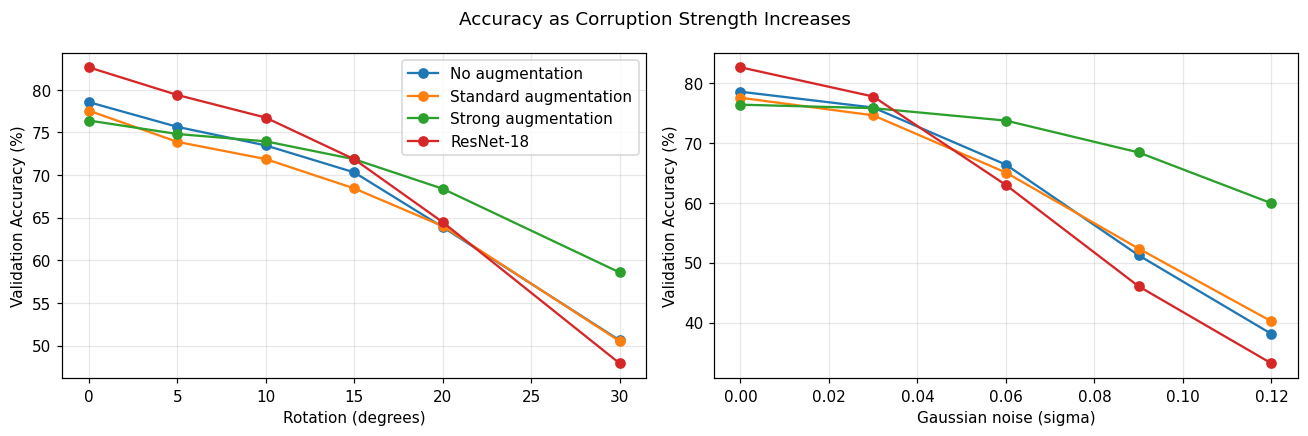

In [213]:
angles_to_test = [0, 5, 10, 15, 20, 30]
sigmas_to_test = [0.0, 0.03, 0.06, 0.09, 0.12]

severity_models = {
    "No augmentation": baseline_model,
    "Standard augmentation": augmented_model,
    "Strong augmentation": strong_aug_model,
    "ResNet-18": resnet,
}

severity_results = []

for angle in angles_to_test:
    if angle == 0:
        images = eval_images
    else:
        images = affine_batch(eval_images.clone(), torch.full((n,), float(angle)), torch.zeros(n))

    for model_name, model in severity_models.items():
        severity_results.append({
            "Model": model_name,
            "Corruption": "Rotation (degrees)",
            "Strength": angle,
            "Accuracy (%)": evaluate_robustness(model, images, eval_labels)["accuracy"],
        })

for sigma in sigmas_to_test:
    noise_gen = torch.Generator().manual_seed(42)
    noise = torch.randn(eval_images.shape, generator=noise_gen).to(eval_images.device) * sigma
    images = (eval_images + noise).clamp(0, 1)

    for model_name, model in severity_models.items():
        severity_results.append({
            "Model": model_name,
            "Corruption": "Gaussian noise (sigma)",
            "Strength": sigma,
            "Accuracy (%)": evaluate_robustness(model, images, eval_labels)["accuracy"],
        })

severity_df = pd.DataFrame(severity_results)

for corruption in severity_df["Corruption"].unique():
    display(
        severity_df[severity_df["Corruption"] == corruption]
        .pivot(index="Model", columns="Strength", values="Accuracy (%)")
        .round(2)
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, corruption in zip(axes, severity_df["Corruption"].unique()):
    part = severity_df[severity_df["Corruption"] == corruption]
    for model_name in severity_models:
        rows = part[part["Model"] == model_name]
        ax.plot(rows["Strength"], rows["Accuracy (%)"], marker="o", label=model_name)
    ax.set_xlabel(corruption)
    ax.set_ylabel("Validation Accuracy (%)")
    ax.grid(alpha=0.3)
axes[0].legend()
fig.suptitle("Accuracy as Corruption Strength Increases")
plt.tight_layout()
savefig(fig, "t4_severity")
plt.show()

**Look at the strongest settings:** The same three validation images at increasing strength help judge whether a person could still name the class.

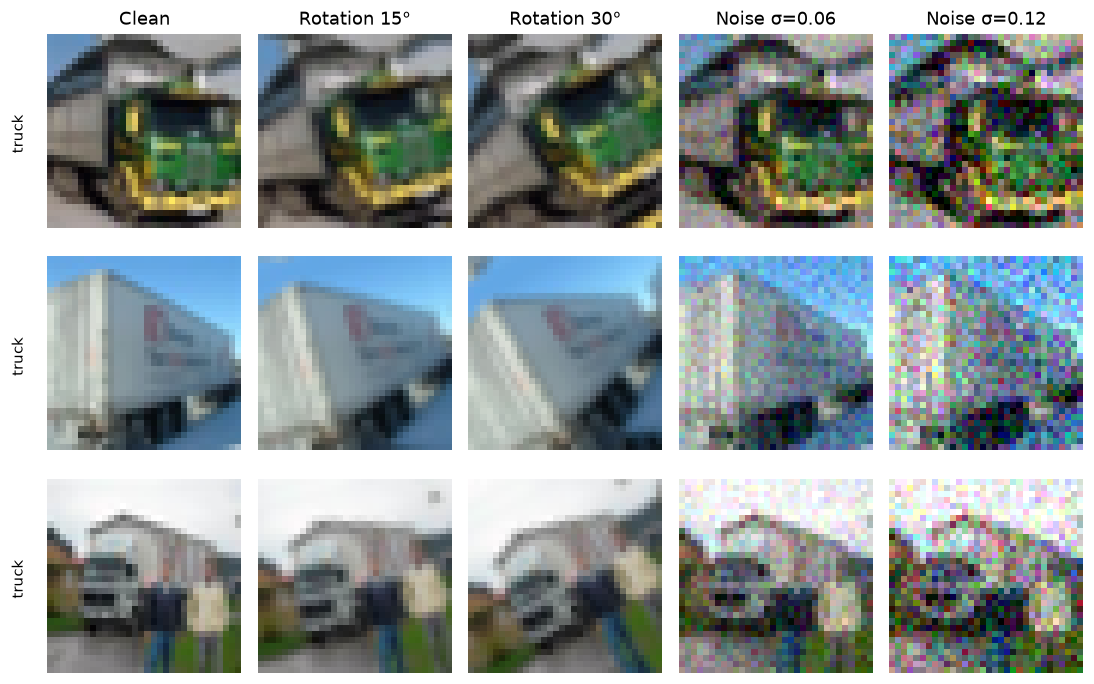

In [ ]:
example_ids = [0, 1, 2]
settings = [
    ("Clean", eval_images[example_ids]),
    ("Rotation 15°", affine_batch(eval_images[example_ids].clone(), torch.full((3,), 15.0), torch.zeros(3))),
    ("Rotation 30°", affine_batch(eval_images[example_ids].clone(), torch.full((3,), 30.0), torch.zeros(3))),
]
for sigma in [0.06, 0.12]:
    noise_gen = torch.Generator().manual_seed(42)
    noise = torch.randn(eval_images[example_ids].shape, generator=noise_gen).to(eval_images.device) * sigma
    settings.append((f"Noise σ={sigma}", (eval_images[example_ids] + noise).clamp(0, 1)))

fig, axes = plt.subplots(len(example_ids), len(settings), figsize=(10, 6.5))
for j, (title, images) in enumerate(settings):
    for i in range(len(example_ids)):
        axes[i, j].imshow(images[i].cpu().permute(1, 2, 0))
        axes[i, j].axis("off")
        if i == 0:
            axes[i, j].set_title(title)

for i, idx in enumerate(example_ids):
    axes[i, 0].text(-4, 16, CLASSES[eval_labels[idx].item()], rotation=90, va="center", ha="right")

plt.tight_layout()
savefig(fig, "t4_severity_examples")
plt.show()

### B13a. Interpret the recorded robustness results

Using the same 5,000 validation images and fixed transformations, clean/rotation/noise accuracies were **78.56% / 70.32% / 66.38%** without augmentation, **77.56% / 68.44% / 65.06%** with standard crop/flip augmentation, and **76.40% / 71.86% / 73.74%** with strong augmentation.

The strong-augmentation model lost **2.16 percentage points** on clean data but gained **1.54 points** on rotation and **7.36 points** on Gaussian noise relative to the unaugmented model. Newly introduced errors from clean to corrupted images fell from **647 to 443** for rotation and **732 to 252** for noise. This supports increased robustness to the particular transformations tested, not a blanket robustness guarantee.

**Which errors appear:** Noise and rotation cause different mistakes. Under noise the unaugmented model sends almost half of its 732 new errors (47.7%) to *frog*, with cat → frog (86) and airplane → deer (81) as the largest pairs. The examples show why: the added speckle looks like the textured green and brown background of frog and deer photos. Under rotation the errors stay closer to the true class: truck → automobile (48) and horse → dog (39) are the largest pairs and no class takes more than 22.9% of them. The rotation examples show trucks called automobile or ship and a frog called cat, all with the object still visible but tilted. Strong augmentation removes the frog sink: its 252 noise errors are spread out (the most common prediction, truck, takes 21.0%) and the largest pairs are dog → cat and bird → deer (24 each), which are mix-ups between similar-looking animals rather than a drift to one class.

**Stronger corruptions:** The severity sweep shows that one strength hides a lot. ResNet-18 is the most accurate model up to 10° and σ = 0.03, ties with strong augmentation at 15° (71.86%), and then falls fastest: at 30° it has 47.92%, the lowest of the four, and at σ = 0.12 it has 33.20%, also the lowest. Strong augmentation loses the least: 58.58% at 30° and 59.94% at σ = 0.12, against 50.62% and 38.12% for the unaugmented model. Standard crop/flip augmentation tracks the unaugmented model at every strength, so its lack of effect in the main comparison is not a matter of the chosen strength. In the example images a person can still name the class at 30° (the reflection padding adds mirrored corners) and mostly at σ = 0.12, although the background is swamped. The steep drops are therefore failures of the models more than labels becoming ambiguous, at least within the tested range. Rotations near 90° or noise strong enough to hide the object would be a different case, which we did not test.

**Cost and limitations:** Extra augmentation introduces preprocessing cost and can slow convergence within a short training budget. The recorded robustness evaluation timings depend on warm-up, execution device, and synchronization. Comparisons were conducted on the same validation IDs, and test-set results were reserved for Task 5.

## Task 5. Analyse predictions and adversarial examples
### B14. Classification reports and confusion matrices
**Evaluate the frozen Task 2 models:** Precision, recall, F1, and class-level confusion on the official 10,000-image test set reveal failures hidden by overall accuracy. The diagonal of a confusion matrix contains correct predictions, and off-diagonal counts indicate class confusions.


AlexNet Classification Report:
              precision    recall  f1-score   support

    airplane      0.873     0.725     0.792      1000
  automobile      0.867     0.914     0.890      1000
        bird      0.750     0.674     0.710      1000
         cat      0.523     0.726     0.608      1000
        deer      0.675     0.863     0.757      1000
         dog      0.768     0.624     0.689      1000
        frog      0.808     0.865     0.836      1000
       horse      0.897     0.761     0.824      1000
        ship      0.889     0.872     0.880      1000
       truck      0.918     0.771     0.838      1000

    accuracy                          0.779     10000
   macro avg      0.797     0.779     0.782     10000
weighted avg      0.797     0.779     0.782     10000


ResNet18 Classification Report:
              precision    recall  f1-score   support

    airplane      0.850     0.834     0.842      1000
  automobile      0.896     0.922     0.909      1000
        bird 

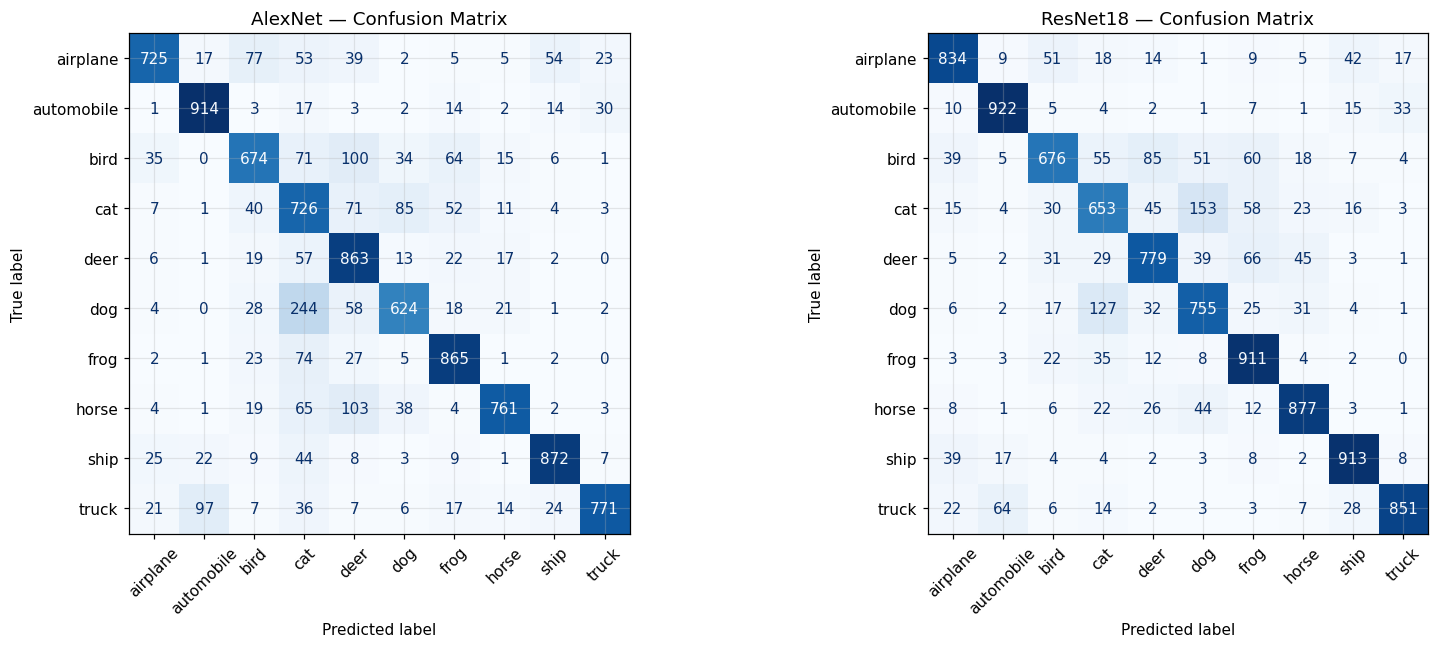

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Use the official CIFAR-10 test set
test_images = to_float(SPLITS["test"].x)
test_labels = SPLITS["test"].y.cpu().numpy()

models = {
    "AlexNet": alexnet,
    "ResNet18": resnet
}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, (name, model) in zip(axes, models.items()):

    # Reuse the prediction function from Task 4
    predictions = get_predictions(
        model, test_images
    ).numpy()

    # Calculate confusion matrix
    cm = confusion_matrix(test_labels, predictions)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASSES
    ).plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(f"{name} — Confusion Matrix")
    ax.tick_params(axis="x", labelrotation=45)

    print(f"\n{name} Classification Report:")
    print(classification_report(
        test_labels,
        predictions,
        target_names=CLASSES,
        digits=3
    ))

plt.tight_layout()
savefig(fig, "t5_confusion_matrices")
plt.show()

**Inspect predictions with probabilities:** Softmax is applied to the ten logits at evaluation time to obtain class probabilities. The largest probability is a confidence indicator, not a guarantee of correctness.

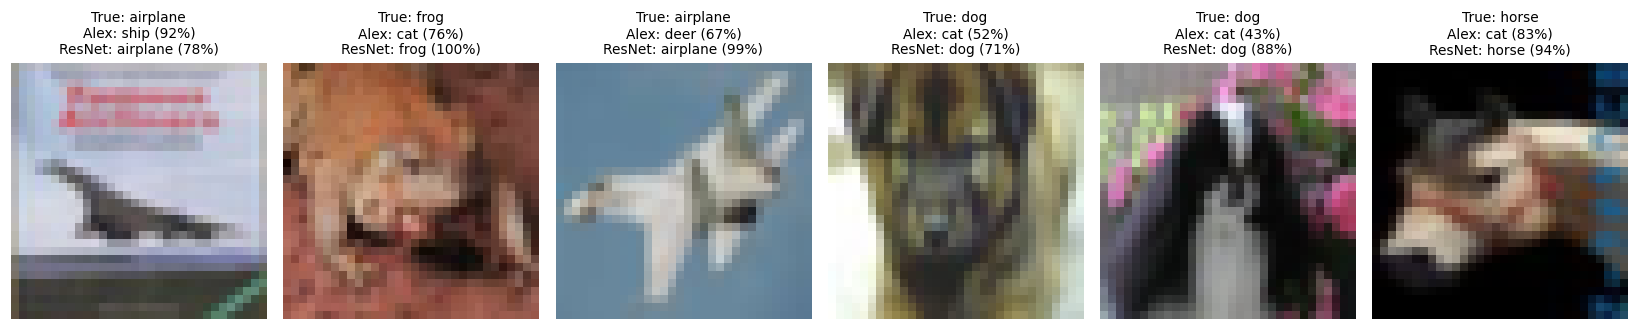

In [ ]:
import torch
import matplotlib.pyplot as plt

def predict_with_confidence(model, images, batch_size=64):
    model.eval()
    all_predictions = []
    all_confidences = []

    with torch.no_grad():
        for i in range(0, len(images), batch_size):
            x = images[i:i + batch_size].to(device)
            x = (x - mean) / std

            probabilities = torch.softmax(model(x), dim=1)
            confidence, prediction = probabilities.max(dim=1)

            all_predictions.append(prediction.cpu())
            all_confidences.append(confidence.cpu())

    return torch.cat(all_predictions), torch.cat(all_confidences)


test_images = to_float(SPLITS["test"].x)
test_labels = SPLITS["test"].y.cpu()

alex_preds, alex_conf = predict_with_confidence(alexnet, test_images)
res_preds, res_conf = predict_with_confidence(resnet, test_images)

# Cases where AlexNet is wrong, but ResNet is correct
indices = torch.where(
    (alex_preds != test_labels) &
    (res_preds == test_labels)
)[0][:6]

fig, axes = plt.subplots(1, len(indices), figsize=(15, 3))

for ax, idx in zip(axes, indices.tolist()):
    ax.imshow(test_images[idx].cpu().permute(1, 2, 0))
    ax.set_title(
        f"True: {CLASSES[test_labels[idx].item()]}\n"
        f"Alex: {CLASSES[alex_preds[idx].item()]} ({alex_conf[idx]:.0%})\n"
        f"ResNet: {CLASSES[res_preds[idx].item()]} ({res_conf[idx]:.0%})",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
savefig(fig, "t5_prediction_examples")
plt.show()

**Show representative successes and failures for both architectures:** We compare cases where both succeed, both fail, and where only one model succeeds, so we do not selectively display only one model's mistakes.

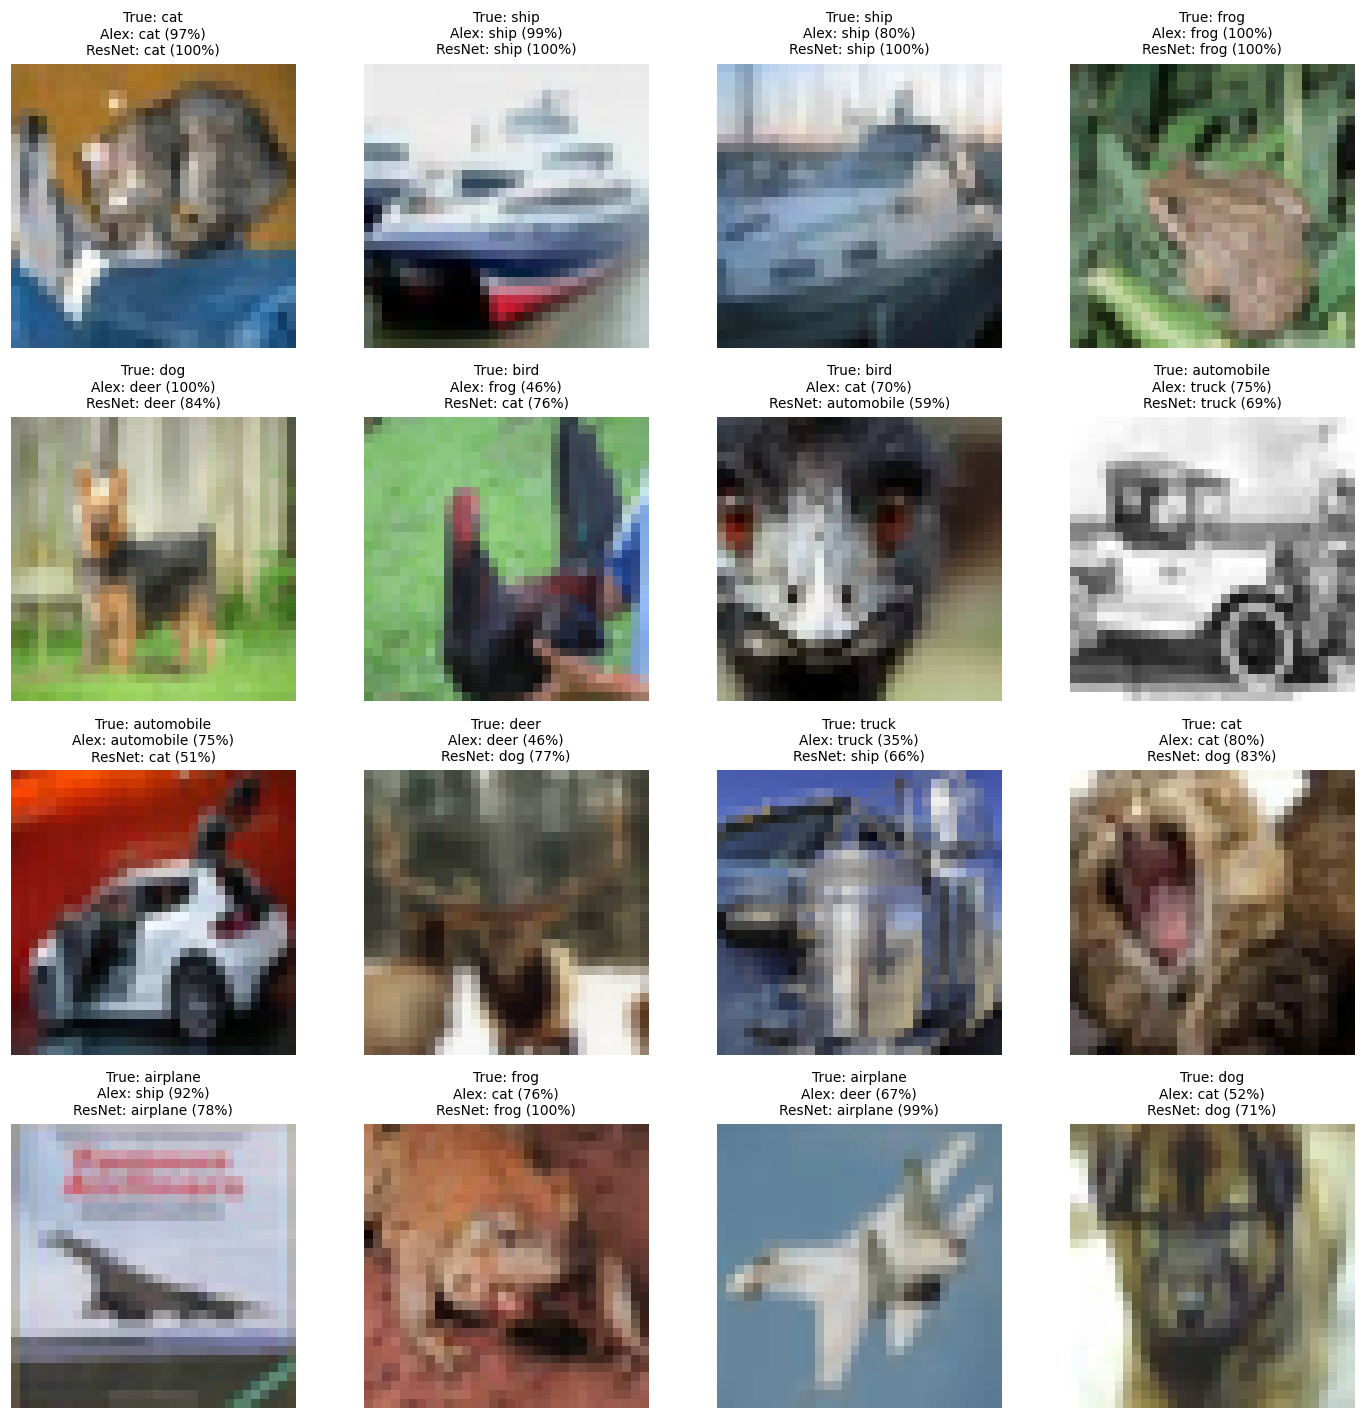

In [ ]:
import matplotlib.pyplot as plt

categories = {
    "Both correct": (alex_preds == test_labels) & (res_preds == test_labels),
    "Both incorrect": (alex_preds != test_labels) & (res_preds != test_labels),
    "Only AlexNet correct": (alex_preds == test_labels) & (res_preds != test_labels),
    "Only ResNet18 correct": (alex_preds != test_labels) & (res_preds == test_labels)
}

fig, axes = plt.subplots(4, 4, figsize=(13, 13))

for row, (category, mask) in enumerate(categories.items()):
    indices = torch.where(mask)[0][:4]

    for col, idx in enumerate(indices.tolist()):
        ax = axes[row, col]

        ax.imshow(test_images[idx].cpu().permute(1, 2, 0))

        ax.set_title(
            f"True: {CLASSES[test_labels[idx].item()]}\n"
            f"Alex: {CLASSES[alex_preds[idx].item()]} ({alex_conf[idx]:.0%})\n"
            f"ResNet: {CLASSES[res_preds[idx].item()]} ({res_conf[idx]:.0%})",
            fontsize=9
        )
        ax.axis("off")

    axes[row, 0].set_ylabel(category, fontsize=11)

plt.tight_layout()
savefig(fig, "t5_prediction_categories")
plt.show()

### B15. Generate FGSM adversarial examples
**Define a single-step white-box attack:** FGSM adds `epsilon × sign(gradient of cross-entropy with respect to input pixels)` to increase the loss while leaving model weights unchanged. The attacked pixels are clipped to `[0, 1]`, enforcing a maximum change of epsilon per input component.

In [ ]:

def fgsm_attack(model, images, labels, epsilon):
    model.eval()

    # Images must be in [0, 1]
    x = images.clone().detach().to(device)
    y = labels.to(device)

    # Enable gradients for the input images
    x.requires_grad_(True)

    # Normalize before passing through the model
    normalized = (x - mean) / std

    outputs = model(normalized)
    loss = nn.functional.cross_entropy(outputs, y)

    # Gradient of loss with respect to input pixels
    gradient = torch.autograd.grad(loss, x)[0]

    # Generate adversarial images
    adversarial = x + epsilon * gradient.sign()

    # Keep valid pixel values
    adversarial = adversarial.clamp(0, 1).detach()

    return adversarial


**Verify the attack constraint on a small batch:** Before the larger experiment, confirm that the attacked images keep their dimensions and valid pixel range and that the maximum componentwise perturbation does not exceed epsilon.

In [ ]:

# Take 8 official test images
x = to_float(SPLITS["test"].x[:8])
y = SPLITS["test"].y[:8]

# Generate adversarial examples against AlexNet
x_adv = fgsm_attack(
    alexnet,
    x,
    y,
    epsilon=0.03
)

print("Original shape:", x.shape)
print("Adversarial shape:", x_adv.shape)
print("Pixel range:", x_adv.min().item(), x_adv.max().item())
print("Maximum pixel change:", (x_adv - x).abs().max().item())


Original shape: torch.Size([8, 3, 32, 32])
Adversarial shape: torch.Size([8, 3, 32, 32])
Pixel range: 0.0 1.0
Maximum pixel change: 0.030000001192092896


**Measure accuracy across attack strengths:** Both models are evaluated on the same subset of test IDs with epsilon 0, 0.01, 0.03, and 0.05. The perturbation is optimized separately for each model using that model's gradients, so this is a white-box, model-specific comparison—not a single identical perturbed dataset.

In [218]:

# FGSM evaluation settings
epsilons = [0.0, 0.01, 0.03, 0.05]
attack_n = P["attack_n"]

# Use the same test images for both models
attack_images = to_float(SPLITS["test"].x[:attack_n])
attack_labels = SPLITS["test"].y[:attack_n]

fgsm_results = []

for model_name, model in [
    ("AlexNet", alexnet),
    ("ResNet18", resnet)
]:
    model.eval()

    for epsilon in epsilons:
        correct = 0
        total = 0

        for i in range(0, attack_n, BATCH_SIZE):
            x = attack_images[i:i + BATCH_SIZE]
            y = attack_labels[i:i + BATCH_SIZE]

            # FGSM creates adversarial images for this model
            x_adv = fgsm_attack(model, x, y, epsilon)

            # Evaluate the attacked images
            with torch.no_grad():
                outputs = model((x_adv - mean) / std)
                predictions = outputs.argmax(dim=1)

            correct += (predictions == y).sum().item()
            total += len(y)

        accuracy = 100 * correct / total

        fgsm_results.append({
            "Model": model_name,
            "Epsilon": epsilon,
            "Accuracy (%)": accuracy
        })

fgsm_df = pd.DataFrame(fgsm_results)

display(fgsm_df)


,Model,Epsilon,Accuracy (%)
0,AlexNet,0.00,78.8
1,AlexNet,0.01,34.6
2,AlexNet,0.03,4.6
3,AlexNet,0.05,0.8
4,ResNet18,0.00,82.4
5,ResNet18,0.01,16.0
6,ResNet18,0.03,3.2
7,ResNet18,0.05,1.6


**Display adversarial examples:** The same initially correctly classified images are shown at several epsilon values with true label, prediction, and confidence. This visual test distinguishes deliberate gradient-based perturbation from the random corruption in Task 4.

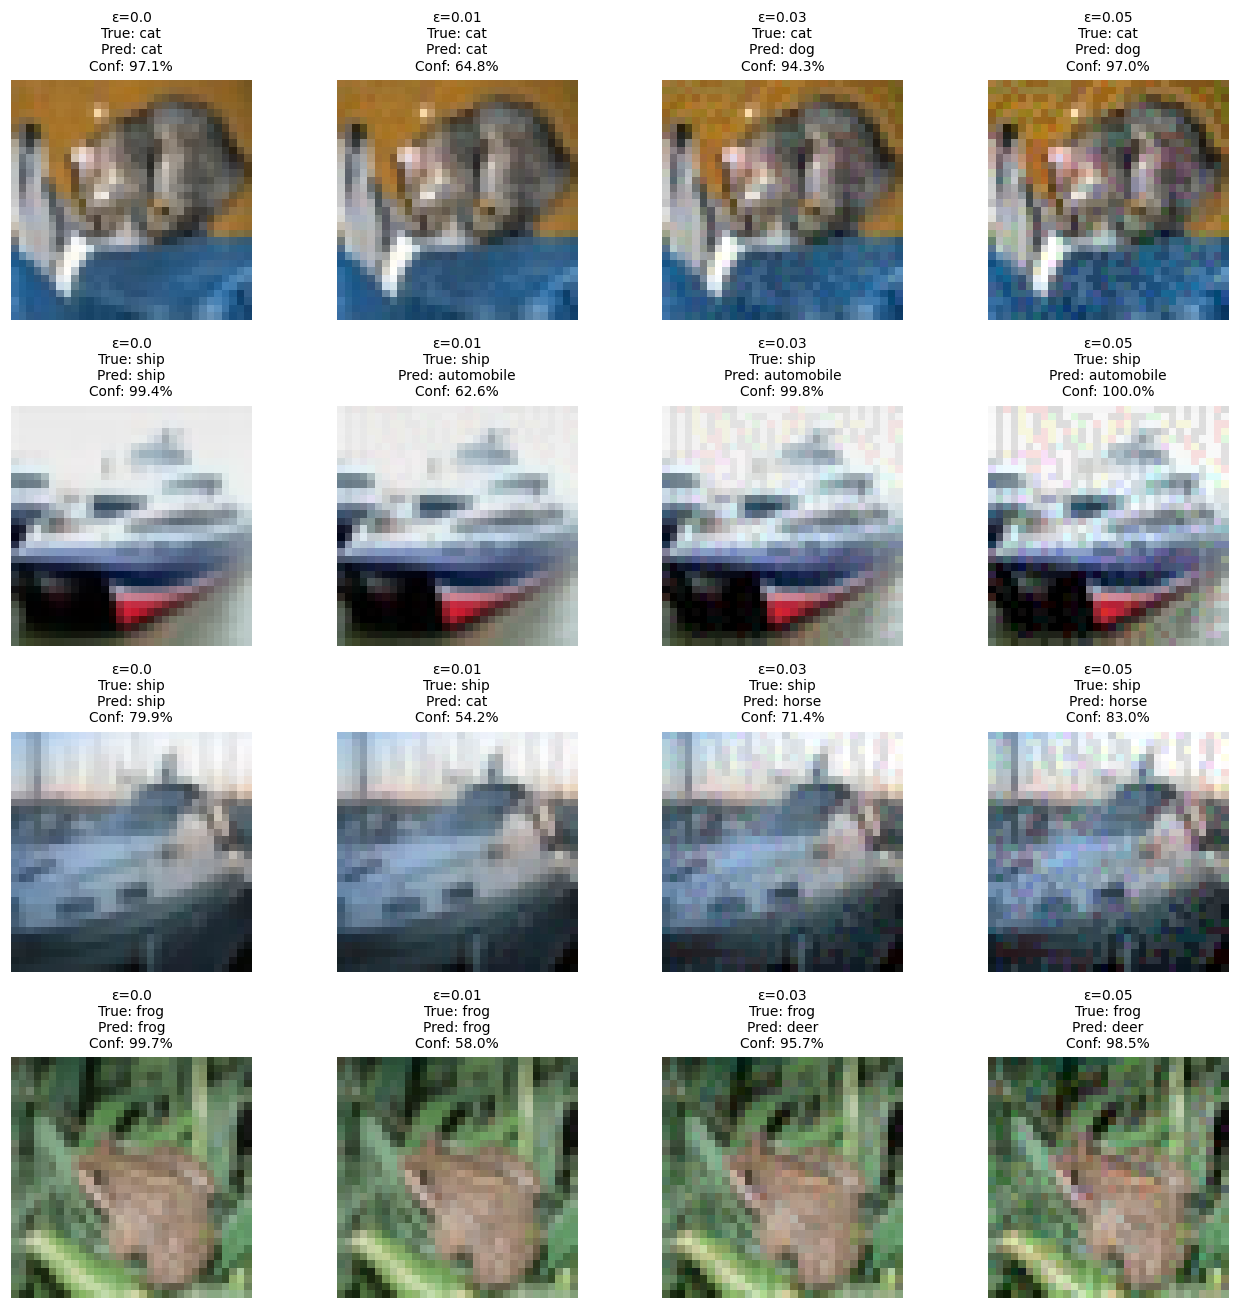

In [219]:

import matplotlib.pyplot as plt

epsilons = [0.0, 0.01, 0.03, 0.05]

# Select 4 test images that AlexNet classifies correctly
test_x = to_float(SPLITS["test"].x[:100])
test_y = SPLITS["test"].y[:100]

alexnet.eval()

with torch.no_grad():
    outputs = alexnet((test_x - mean) / std)
    predictions = outputs.argmax(dim=1)

correct_indices = torch.where(predictions == test_y)[0][:4]

fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for row, idx in enumerate(correct_indices.tolist()):
    x = test_x[idx:idx+1]
    y = test_y[idx:idx+1]

    for col, epsilon in enumerate(epsilons):

        # Generate FGSM adversarial image
        x_adv = fgsm_attack(alexnet, x, y, epsilon)

        # Predict the modified image
        with torch.no_grad():
            probabilities = torch.softmax(
                alexnet((x_adv - mean) / std), dim=1
            )

            confidence, prediction = probabilities.max(dim=1)

        axes[row, col].imshow(
            x_adv[0].detach().cpu().permute(1, 2, 0).numpy()
        )

        axes[row, col].set_title(
            f"ε={epsilon}\n"
            f"True: {CLASSES[y.item()]}\n"
            f"Pred: {CLASSES[prediction.item()]}\n"
            f"Conf: {confidence.item():.1%}",
            fontsize=9
        )
        axes[row, col].axis("off")

plt.tight_layout()
savefig(fig, "t5_fgsm_examples")
plt.show()


### B15a. Interpret the recorded prediction and attack results

On the official 10,000-image test set, AlexNet achieved **77.95%** accuracy (macro F1 **0.782**) and ResNet-18 achieved **81.71%** (macro F1 **0.816**). Cat is the hardest class for both models (F1 **0.608** and **0.666**). AlexNet uses cat as a catch-all for animals: it predicts cat for 1,387 test images while only 1,000 are cats, so its cat precision is just **0.523**, and its largest single confusion is **244** dogs labelled cat. ResNet-18's cat/dog confusion runs in both directions (**153** cats called dog, **127** dogs called cat), and its dog recall is **75.5%** against **62.4%** for AlexNet. Truck → automobile is the main vehicle confusion for both (**97** and **64** images). The examples also show that high softmax confidence can accompany an incorrect prediction.

In the FGSM evaluation on the first **500 test images**, AlexNet accuracy at epsilon **0 / 0.01 / 0.03 / 0.05** was **78.8% / 34.6% / 4.6% / 0.8%**, and ResNet-18 achieved **82.4% / 16.0% / 3.2% / 1.6%**. ResNet-18 starts higher but falls faster at small epsilon. At epsilon 0.01 the attack does not always succeed: two of the four displayed images (the cat and the frog) keep their label. From epsilon 0.03 all four are misclassified, often with high confidence (cat → dog at 94.3%, ship → automobile at 99.8%). These are white-box, model-specific attacks, so they show susceptibility to this one-step attack, not to every adversary. The clean accuracy on the 500-image subset need not match full-test accuracy.

**Random corruption versus adversarial perturbation:** Gaussian noise is sampled independently of the model, whereas FGSM follows the gradient direction that increases the classification loss. An epsilon of 0.03 limits each pixel's change to at most 0.03 on the `[0, 1]` scale, less than 8 intensity levels out of 255. The Task 4 noise (standard deviation 0.06) changes pixels more on average, yet the AlexNet baseline still classified 66.38% of noisy images correctly, while FGSM at epsilon 0.03 leaves both models below 5%. Both attacks keep the model weights fixed.

**Remaining limitations:** The comparisons use a short training budget, and the attack uses 500 images and a single step. Task 6 repeats the two reference models over three seeds, and a stronger multi-step attack such as PGD would test whether the FGSM ranking holds.

## Task 6. Benchmark and discuss the tradeoffs
### B16. Collect the training cost of every configuration
**Gather the measured training cost in one table:** Every configuration from Tasks 2–4 was trained under the same compute budget: eight epochs, batch size 64, SGD with learning rate 0.01 and momentum 0.9, on the same 45,000 training images. The logged histories can therefore be compared directly. The recorded seconds include the validation pass after each epoch. The Task 3 baseline is used as the AlexNet reference because it has the same architecture as the Task 2 AlexNet and was timed by `train_model`.

In [220]:
configs = [
    ("AlexNet small", "AlexNet small", small_model, small_history),
    ("AlexNet baseline", "AlexNet", baseline_model, baseline_history),
    ("AlexNet large", "AlexNet large", large_model, large_history),
    ("AlexNet no L2", "AlexNet", no_l2_model, no_l2_history),
    ("AlexNet strong L2", "AlexNet", strong_l2_model, strong_l2_history),
    ("AlexNet no dropout", "AlexNet", no_dropout_model, no_dropout_history),
    ("AlexNet dropout 0.3", "AlexNet", dropout_03_model, dropout_03_history),
    ("AlexNet standard aug", "AlexNet", augmented_model, augmented_history),
    ("AlexNet strong aug", "AlexNet", strong_aug_model, strong_aug_history),
    ("ResNet-18", "ResNet-18", resnet, resnet_history),
]

cost_results = []

for name, architecture, model, history in configs:
    best_idx = history["val_accuracy"].idxmax()

    cost_results.append({
        "Configuration": name,
        "Architecture": architecture,
        "Parameters": count_parameters(model),
        "Best Val Accuracy (%)": history.loc[best_idx, "val_accuracy"],
        "Best Epoch": int(history.loc[best_idx, "epoch"]),
        "Training Time (s)": history["seconds"].sum(),
        "Time per Epoch (s)": history["seconds"].mean(),
        "Peak GPU Memory (MB)": history["peak_memory_mb"].max(),
    })

cost_df = pd.DataFrame(cost_results)
display(cost_df)

,Configuration,Architecture,Parameters,Best Val Accuracy (%),Best Epoch,Training Time (s),Time per Epoch (s),Peak GPU Memory (MB)
0,AlexNet small,AlexNet small,3334602,76.72,8,72.6048,9.0756,1974.0601
1,AlexNet baseline,AlexNet,6976842,78.56,8,79.6443,9.9555,2041.4043
2,AlexNet large,AlexNet large,12750666,79.06,8,89.8965,11.2371,801.2480
3,AlexNet no L2,AlexNet,6976842,79.94,8,76.9550,9.6194,832.9854
4,AlexNet strong L2,AlexNet,6976842,69.28,8,79.9078,9.9885,886.9980
5,AlexNet no dropout,AlexNet,6976842,78.64,7,79.5962,9.9495,938.3857
6,AlexNet dropout 0.3,AlexNet,6976842,78.46,7,79.9057,9.9882,993.8359
7,AlexNet standard aug,AlexNet,6976842,77.56,8,82.1773,10.2722,1046.5986
8,AlexNet strong aug,AlexNet,6976842,76.40,8,93.1597,11.6450,1392.9863
9,ResNet-18,ResNet-18,11173962,82.64,8,372.1071,46.5134,2210.4634


### B17. Measure inference performance
**Time the forward pass on its own:** Training time says little about the cost of using a model, so inference is timed separately: latency for a single image (batch size 1) and throughput for a large batch (256 images). A few warm-up passes are not timed, and the device is synchronized before the clock is read. Dropout, weight decay and augmentation do not change the network, so only the four distinct architectures are timed. Model size is the size of the saved weights only, because the training checkpoints also store the optimizer state and are larger.

In [230]:
def inference_benchmark(model, batch_size, repeats=50, dtype=torch.float32):
    model.eval()
    x = torch.rand(batch_size, 3, 32, 32, device=device)
    x = ((x - mean) / std).to(dtype)

    with torch.no_grad():
        # Warm-up so one-off kernel setup is not timed
        for _ in range(5):
            model(x)

        sync()
        start = time.perf_counter()
        for _ in range(repeats):
            model(x)
        sync()

    return (time.perf_counter() - start) / repeats


def weights_size_mb(model):
    buffer = io.BytesIO()
    torch.save(model.state_dict(), buffer)
    return buffer.getbuffer().nbytes / 1e6


inference_results = []

for architecture, model in [
    ("AlexNet small", small_model),
    ("AlexNet", baseline_model),
    ("AlexNet large", large_model),
    ("ResNet-18", resnet)
]:
    latency = inference_benchmark(model, batch_size=1, repeats=200)
    batch_time = inference_benchmark(model, batch_size=256)

    inference_results.append({
        "Architecture": architecture,
        "Latency (ms, bs 1)": 1000 * latency,
        "Throughput (img/s, bs 256)": 256 / batch_time,
        "Weights (MB)": weights_size_mb(model),
    })

inference_df = pd.DataFrame(inference_results)
display(inference_df)

,Architecture,"Latency (ms, bs 1)","Throughput (img/s, bs 256)",Weights (MB)
0,AlexNet small,0.7543,16105.6023,13.3442
1,AlexNet,0.7248,15535.3104,27.9132
2,AlexNet large,0.6892,14444.3504,51.0085
3,ResNet-18,2.5726,2348.9829,44.7747


### B18. Measure accuracy and robustness for every configuration
**Evaluate all configurations with the same functions and images:** Task 4 compared only the AlexNet augmentation conditions, and Task 5 attacked only the two Task 2 models. For a fair comparison, every configuration is evaluated here on the official test set, on the clean, rotated and noisy validation images from Task 4, and under FGSM with epsilon 0.03 on the same test images as Task 5. These numbers are reported, not used to select a configuration.

In [231]:
criterion = nn.CrossEntropyLoss()
fgsm_epsilon = 0.03

quality_results = []

for name, architecture, model, history in configs:
    row = {
        "Configuration": name,
        "Test Accuracy (%)": run_epoch(model, SPLITS["test"], criterion)["accuracy"],
    }

    # Same clean / rotated / noisy validation images as Task 4
    for condition, images in corrupted_sets.items():
        metrics = evaluate_robustness(model, images, eval_labels)
        row[f"{condition} (%)"] = metrics["accuracy"]

    # FGSM on the same test images as Task 5
    correct = 0
    for i in range(0, len(attack_images), BATCH_SIZE):
        x = attack_images[i:i + BATCH_SIZE]
        y = attack_labels[i:i + BATCH_SIZE]
        x_adv = fgsm_attack(model, x, y, fgsm_epsilon)

        with torch.no_grad():
            predictions = model((x_adv - mean) / std).argmax(dim=1)
        correct += (predictions == y).sum().item()

    row["FGSM ε=0.03 (%)"] = 100 * correct / len(attack_labels)
    quality_results.append(row)

quality_df = pd.DataFrame(quality_results)
display(quality_df)

,Configuration,Test Accuracy (%),Clean (%),Rotation 15° (%),Gaussian Noise (%),FGSM ε=0.03 (%)
0,AlexNet small,76.69,76.72,64.48,67.10,4.8
1,AlexNet baseline,78.71,78.56,70.32,66.38,6.8
2,AlexNet large,78.68,79.06,68.64,67.30,5.6
3,AlexNet no L2,79.67,79.94,69.82,70.68,6.0
4,AlexNet strong L2,68.69,69.28,58.94,63.30,6.2
5,AlexNet no dropout,76.97,78.64,66.64,70.08,5.2
6,AlexNet dropout 0.3,77.02,78.46,65.66,69.90,6.4
7,AlexNet standard aug,77.45,77.56,68.44,65.06,5.6
8,AlexNet strong aug,76.18,76.40,71.86,73.74,9.6
9,ResNet-18,81.71,82.64,71.86,62.98,3.2


### B19. Relate accuracy and robustness to cost
**Join the measurements into one tradeoff table:** Each configuration gets its training cost, the inference cost of its architecture, and its accuracy and robustness. The last three columns compare each configuration with the AlexNet baseline, so a change can be read as "X times the training time for Y percentage points of accuracy".

In [232]:
tradeoff_df = cost_df.merge(inference_df, on="Architecture")
tradeoff_df = tradeoff_df.merge(quality_df, on="Configuration")

reference = tradeoff_df.set_index("Configuration").loc["AlexNet baseline"]

tradeoff_df["Δ Test Acc (pp)"] = tradeoff_df["Test Accuracy (%)"] - reference["Test Accuracy (%)"]
tradeoff_df["Δ Noise Acc (pp)"] = tradeoff_df["Gaussian Noise (%)"] - reference["Gaussian Noise (%)"]
tradeoff_df["Training Time vs Baseline"] = tradeoff_df["Training Time (s)"] / reference["Training Time (s)"]

columns = [
    "Configuration",
    "Parameters",
    "Training Time (s)",
    "Latency (ms, bs 1)",
    "Throughput (img/s, bs 256)",
    "Test Accuracy (%)",
    "Rotation 15° (%)",
    "Gaussian Noise (%)",
    "FGSM ε=0.03 (%)",
    "Δ Test Acc (pp)",
    "Δ Noise Acc (pp)",
    "Training Time vs Baseline",
]
display(tradeoff_df[columns].round(2))

,Configuration,Parameters,Training Time (s),"Latency (ms, bs 1)","Throughput (img/s, bs 256)",Test Accuracy (%),Rotation 15° (%),Gaussian Noise (%),FGSM ε=0.03 (%),Δ Test Acc (pp),Δ Noise Acc (pp),Training Time vs Baseline
0,AlexNet small,3334602,72.60,0.75,16105.60,76.69,64.48,67.10,4.8,-2.02,0.72,0.91
1,AlexNet baseline,6976842,79.64,0.72,15535.31,78.71,70.32,66.38,6.8,0.00,0.00,1.00
2,AlexNet large,12750666,89.90,0.69,14444.35,78.68,68.64,67.30,5.6,-0.03,0.92,1.13
3,AlexNet no L2,6976842,76.96,0.72,15535.31,79.67,69.82,70.68,6.0,0.96,4.30,0.97
4,AlexNet strong L2,6976842,79.91,0.72,15535.31,68.69,58.94,63.30,6.2,-10.02,-3.08,1.00
5,AlexNet no dropout,6976842,79.60,0.72,15535.31,76.97,66.64,70.08,5.2,-1.74,3.70,1.00
6,AlexNet dropout 0.3,6976842,79.91,0.72,15535.31,77.02,65.66,69.90,6.4,-1.69,3.52,1.00
7,AlexNet standard aug,6976842,82.18,0.72,15535.31,77.45,68.44,65.06,5.6,-1.26,-1.32,1.03
8,AlexNet strong aug,6976842,93.16,0.72,15535.31,76.18,71.86,73.74,9.6,-2.53,7.36,1.17
9,ResNet-18,11173962,372.11,2.57,2348.98,81.71,71.86,62.98,3.2,3.00,-3.40,4.67


**Plot accuracy and robustness against cost:** In the left and right panels, points further up and to the left give more accuracy for less training time. In the middle panel, up and to the right is better, because higher throughput means cheaper inference. AlexNet variants that share an architecture have the same throughput, so they lie on one vertical line in the middle panel.

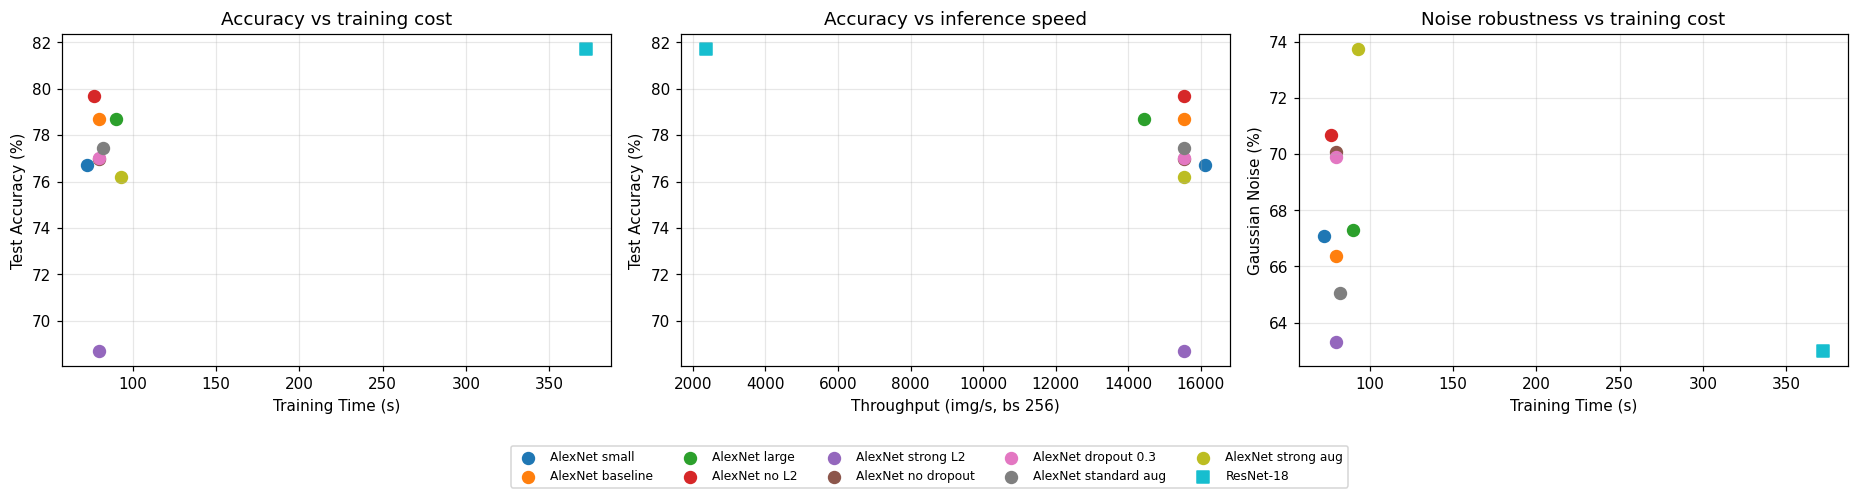

In [233]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

panels = [
    ("Training Time (s)", "Test Accuracy (%)", "Accuracy vs training cost"),
    ("Throughput (img/s, bs 256)", "Test Accuracy (%)", "Accuracy vs inference speed"),
    ("Training Time (s)", "Gaussian Noise (%)", "Noise robustness vs training cost"),
]

colors = plt.cm.tab10.colors

for ax, (x_col, y_col, title) in zip(axes, panels):
    for i, row in tradeoff_df.iterrows():
        ax.scatter(
            row[x_col],
            row[y_col],
            s=60,
            color=colors[i % 10],
            marker="s" if row["Architecture"] == "ResNet-18" else "o",
            label=row["Configuration"]
        )

    ax.set_title(title)
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.grid(True, alpha=0.3)

# One shared legend; AlexNet variants with the same architecture overlap in the middle panel
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, fontsize=8)

plt.tight_layout(rect=(0, 0.12, 1, 1))
savefig(fig, "t6_tradeoffs")
plt.show()

### B20. Sensitivity to training duration, random seed and hardware
**Check whether the ranking depends on training duration:** All runs stopped after eight epochs, and most of them reached their best validation accuracy in the last epoch, so they were still improving. We compare the validation ranking halfway through the budget with the ranking at the end. If the order changes between these two points, it could change again with a longer budget.

In [234]:
half = EPOCHS // 2

duration_results = []

for name, architecture, model, history in configs:
    duration_results.append({
        "Configuration": name,
        f"Val Acc @ epoch {half} (%)": history.loc[history["epoch"] == half, "val_accuracy"].item(),
        f"Val Acc @ epoch {EPOCHS} (%)": history.loc[history["epoch"] == EPOCHS, "val_accuracy"].item(),
        "Best Epoch": int(history.loc[history["val_accuracy"].idxmax(), "epoch"]),
    })

duration_df = pd.DataFrame(duration_results)
duration_df[f"Rank @ epoch {half}"] = duration_df[f"Val Acc @ epoch {half} (%)"].rank(ascending=False, method="min").astype(int)
duration_df[f"Rank @ epoch {EPOCHS}"] = duration_df[f"Val Acc @ epoch {EPOCHS} (%)"].rank(ascending=False, method="min").astype(int)

display(duration_df.sort_values(f"Rank @ epoch {EPOCHS}"))

,Configuration,Val Acc @ epoch 4 (%),Val Acc @ epoch 8 (%),Best Epoch,Rank @ epoch 4,Rank @ epoch 8
9,ResNet-18,76.12,82.64,8,1,1
3,AlexNet no L2,70.08,79.94,8,2,2
2,AlexNet large,69.64,79.06,8,3,3
1,AlexNet baseline,68.60,78.56,8,6,4
6,AlexNet dropout 0.3,68.82,78.22,7,5,5
5,AlexNet no dropout,69.62,77.64,7,4,6
7,AlexNet standard aug,62.82,77.56,8,8,7
0,AlexNet small,64.04,76.72,8,7,8
8,AlexNet strong aug,61.06,76.40,8,9,9
4,AlexNet strong L2,58.84,69.28,8,10,10


**Repeat the two reference models with more seeds:** Most differences in Task 3 are one or two percentage points and come from a single seed. To measure how much results vary from seed to seed, the AlexNet baseline and ResNet-18 are trained twice more, with seeds 43 and 44, under the same budget. The seed controls weight initialization, dropout and the shuffling order, while the data split stays fixed through `SPLIT_SEED`. `train_model` reads `BASE_SEED` for its shuffling generator, so it is changed for these runs and restored afterwards.

In [235]:
EXTRA_SEEDS = [43, 44]
criterion = nn.CrossEntropyLoss()

seed_results = []

# Seed 42 runs from Tasks 2 and 3
for name, model, history in [
    ("AlexNet baseline", baseline_model, baseline_history),
    ("ResNet-18", resnet, resnet_history)
]:
    seed_results.append({
        "Model": name,
        "Seed": BASE_SEED,
        "Best Val Accuracy (%)": history["val_accuracy"].max(),
        "Test Accuracy (%)": run_epoch(model, SPLITS["test"], criterion)["accuracy"],
        "Training Time (s)": history["seconds"].sum(),
    })

original_seed = BASE_SEED

for seed in EXTRA_SEEDS:
    BASE_SEED = seed  # train_model uses BASE_SEED for its shuffling generator

    set_seed(seed)
    seed_alexnet, seed_alexnet_history = train_model(
        f"t6_alexnet_seed{seed}",
        AlexNet3(fc1=1024, fc2=512, dropout=0.5),
        EPOCHS
    )

    set_seed(seed)
    seed_resnet, seed_resnet_history = train_model(
        f"t6_resnet18_seed{seed}",
        ResNet18(),
        EPOCHS
    )

    for name, model, history in [
        ("AlexNet baseline", seed_alexnet, seed_alexnet_history),
        ("ResNet-18", seed_resnet, seed_resnet_history)
    ]:
        seed_results.append({
            "Model": name,
            "Seed": seed,
            "Best Val Accuracy (%)": history["val_accuracy"].max(),
            "Test Accuracy (%)": run_epoch(model, SPLITS["test"], criterion)["accuracy"],
            "Training Time (s)": history["seconds"].sum(),
        })

BASE_SEED = original_seed
set_seed(BASE_SEED)

seed_df = pd.DataFrame(seed_results)
display(seed_df)

t6_alexnet_seed43: Starting new training
t6_alexnet_seed43 | Epoch 1/8 | Train: 23.79% | Val: 39.76% | Time: 10.0s | Peak GPU Memory: 2153.9 MB
t6_alexnet_seed43 | Epoch 2/8 | Train: 44.98% | Val: 51.86% | Time: 10.1s | Peak GPU Memory: 2153.4 MB
t6_alexnet_seed43 | Epoch 3/8 | Train: 57.10% | Val: 62.94% | Time: 10.3s | Peak GPU Memory: 2153.4 MB
t6_alexnet_seed43 | Epoch 4/8 | Train: 66.04% | Val: 68.06% | Time: 9.9s | Peak GPU Memory: 2153.4 MB
t6_alexnet_seed43 | Epoch 5/8 | Train: 71.19% | Val: 71.86% | Time: 9.8s | Peak GPU Memory: 2153.4 MB
t6_alexnet_seed43 | Epoch 6/8 | Train: 75.53% | Val: 75.78% | Time: 9.9s | Peak GPU Memory: 2153.4 MB
t6_alexnet_seed43 | Epoch 7/8 | Train: 78.68% | Val: 77.30% | Time: 9.9s | Peak GPU Memory: 2153.4 MB
t6_alexnet_seed43 | Epoch 8/8 | Train: 81.73% | Val: 77.96% | Time: 9.9s | Peak GPU Memory: 2153.4 MB
t6_alexnet_seed43: Loaded best checkpoint (epoch 8)
t6_resnet18_seed43: Starting new training
t6_resnet18_seed43 | Epoch 1/8 | Train: 51.99%

,Model,Seed,Best Val Accuracy (%),Test Accuracy (%),Training Time (s)
0,AlexNet baseline,42,78.56,78.71,79.6443
1,ResNet-18,42,82.64,81.71,372.1071
2,AlexNet baseline,43,77.96,77.73,79.7039
3,ResNet-18,43,81.78,80.97,372.6219
4,AlexNet baseline,44,78.06,76.30,79.7586
5,ResNet-18,44,79.90,79.46,372.2027


**Summarize the spread across seeds:** The standard deviation shows how large a difference has to be before it means more than seed-to-seed variation. The second table checks whether ResNet-18 beats AlexNet for every seed, not just on average.

Best Val Accuracy (%)                     Test Accuracy (%)                     Training Time (s)                      
                                  mean   std    min    max              mean   std    min    max              mean   std     min     max
Model                                                                                                                                   
AlexNet baseline                 78.19  0.32  77.96  78.56             77.58  1.21  76.30  78.71             79.70  0.06   79.64   79.76
ResNet-18                        81.44  1.40  79.90  82.64             80.71  1.15  79.46  81.71            372.31  0.27  372.11  372.62

Model,AlexNet baseline,ResNet-18,ResNet-18 − AlexNet (pp)
Seed,,,
42,78.71,81.71,3.00
43,77.73,80.97,3.24
44,76.30,79.46,3.16


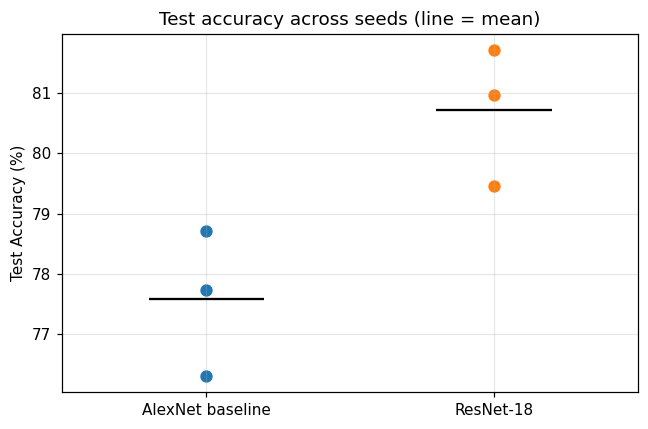

In [236]:
metrics = ["Best Val Accuracy (%)", "Test Accuracy (%)", "Training Time (s)"]
seed_summary = seed_df.groupby("Model")[metrics].agg(["mean", "std", "min", "max"])
display(seed_summary.round(2))

seed_gap = seed_df.pivot(index="Seed", columns="Model", values="Test Accuracy (%)")
seed_gap["ResNet-18 − AlexNet (pp)"] = seed_gap["ResNet-18"] - seed_gap["AlexNet baseline"]
display(seed_gap.round(2))

fig, ax = plt.subplots(figsize=(6, 4))

for i, (name, group) in enumerate(seed_df.groupby("Model")):
    ax.scatter([i] * len(group), group["Test Accuracy (%)"], s=50, label=name)
    ax.hlines(group["Test Accuracy (%)"].mean(), i - 0.2, i + 0.2, color="black")

ax.set_xticks(range(seed_df["Model"].nunique()))
ax.set_xticklabels(sorted(seed_df["Model"].unique()))
ax.set_xlim(-0.5, seed_df["Model"].nunique() - 0.5)
ax.set_ylabel("Test Accuracy (%)")
ax.set_title("Test accuracy across seeds (line = mean)")
ax.grid(True, alpha=0.3)

plt.tight_layout()
savefig(fig, "t6_seed_spread")
plt.show()

**Record the hardware and numeric precision:** Every timing in this task depends on the device. `USE_AMP` is defined in the setup, but the training and evaluation loops never call `autocast()`, so all runs use 32-bit floating point. Another GPU, Apple MPS, a CPU or mixed precision would give different absolute times, and could also change the AlexNet/ResNet ratio, because the two networks load the hardware differently (large dense layers versus many convolutions). The earlier ResNet run that moved from CPU to GPU shows how much a single timing can change.

In [237]:
hardware = pd.DataFrame([{
    "Device": DEVICE_NAME,
    "PyTorch": torch.__version__,
    "Precision": "FP32",
    "Profile": PROFILE,
    "Epochs": EPOCHS,
    "Batch Size": BATCH_SIZE,
}])
display(hardware)

,Device,PyTorch,Precision,Profile,Epochs,Batch Size
0,Tesla T4,2.14.1+cu130,FP32,local,8,64


**Collect the numbers used in the discussion:** The ratios below are read directly from the tables above, so the discussion can quote them without manual arithmetic.

In [238]:
table = tradeoff_df.set_index("Configuration")
alex = table.loc["AlexNet baseline"]
res = table.loc["ResNet-18"]
strong = table.loc["AlexNet strong aug"]
standard = table.loc["AlexNet standard aug"]
large = table.loc["AlexNet large"]

print("ResNet-18 vs AlexNet baseline")
print(f"  test accuracy:   {res['Test Accuracy (%)'] - alex['Test Accuracy (%)']:+.2f} pp")
print(f"  noise accuracy:  {res['Gaussian Noise (%)'] - alex['Gaussian Noise (%)']:+.2f} pp")
print(f"  FGSM accuracy:   {res['FGSM ε=0.03 (%)'] - alex['FGSM ε=0.03 (%)']:+.2f} pp")
print(f"  parameters:      {res['Parameters'] / alex['Parameters']:.2f}x")
print(f"  training time:   {res['Training Time (s)'] / alex['Training Time (s)']:.2f}x")
print(f"  latency (bs 1):  {res['Latency (ms, bs 1)'] / alex['Latency (ms, bs 1)']:.2f}x")
print(f"  throughput:      {res['Throughput (img/s, bs 256)'] / alex['Throughput (img/s, bs 256)']:.2f}x")

for label, row in [("Standard augmentation", standard), ("Strong augmentation", strong)]:
    print(f"\n{label} vs AlexNet baseline")
    print(f"  clean val:       {row['Clean (%)'] - alex['Clean (%)']:+.2f} pp")
    print(f"  rotation:        {row['Rotation 15° (%)'] - alex['Rotation 15° (%)']:+.2f} pp")
    print(f"  noise:           {row['Gaussian Noise (%)'] - alex['Gaussian Noise (%)']:+.2f} pp")
    print(f"  training time:   {row['Training Time (s)'] / alex['Training Time (s)']:.2f}x")

print("\nLarge vs baseline AlexNet")
print(f"  test accuracy:   {large['Test Accuracy (%)'] - alex['Test Accuracy (%)']:+.2f} pp")
print(f"  parameters:      {large['Parameters'] / alex['Parameters']:.2f}x")
print(f"  training time:   {large['Training Time (s)'] / alex['Training Time (s)']:.2f}x")

print("\nSeed spread (std of test accuracy, pp)")
print(seed_df.groupby("Model")["Test Accuracy (%)"].std().round(2).to_string())

ResNet-18 vs AlexNet baseline
  test accuracy:   +3.00 pp
  noise accuracy:  -3.40 pp
  FGSM accuracy:   -3.60 pp
  parameters:      1.60x
  training time:   4.67x
  latency (bs 1):  3.55x
  throughput:      0.15x

Standard augmentation vs AlexNet baseline
  clean val:       -1.00 pp
  rotation:        -1.88 pp
  noise:           -1.32 pp
  training time:   1.03x

Strong augmentation vs AlexNet baseline
  clean val:       -2.16 pp
  rotation:        +1.54 pp
  noise:           +7.36 pp
  training time:   1.17x

Large vs baseline AlexNet
  test accuracy:   -0.03 pp
  parameters:      1.83x
  training time:   1.13x

Seed spread (std of test accuracy, pp)
Model
AlexNet baseline    1.21
ResNet-18           1.15


### B20a. Discussion of the tradeoffs

**Compute budget:** Every configuration was trained for eight epochs with batch size 64 on the full 45,000-image training split, on one Tesla T4 in 32-bit floating point. Under this budget one AlexNet run takes about **80 s** and one ResNet-18 run about **372 s** (about six minutes).

**Which model would we choose?** ResNet-18 reaches **81.71%** test accuracy against **78.71%** for the AlexNet baseline (**+3.00 pp**). Across three seeds the standard deviation of test accuracy is **1.21** pp for AlexNet and **1.15** pp for ResNet-18, and ResNet-18 is ahead for **all 3** seeds (by 3.00, 3.24 and 3.16 pp), so the gap is larger than seed-to-seed variation. In exchange, ResNet-18 has **1.60×** the parameters, **4.67×** the training time, **3.55×** the single-image latency and **6.6×** lower throughput. Under our budget we would choose **ResNet-18** when clean accuracy matters most, because the gain is consistent and one run still takes only about six minutes on a free T4.

The choice changes if inputs are noisy or inference must be cheap. ResNet-18 loses **19.7** points under Gaussian noise, the most of all ten configurations (noise accuracy **62.98%**). AlexNet trained with strong augmentation keeps **73.74%** on noisy images, costs **1.17×** the baseline's training time and nothing extra at inference, at the price of about **5.5** points of clean test accuracy against ResNet-18. Neither model resists FGSM (every configuration is below **10%** at ε = 0.03), so adversarial robustness does not decide between them.

**Which changes improve accuracy or robustness at an acceptable cost?**
- *Strong augmentation:* **−2.16 pp** on clean validation images, **+1.54 pp** under rotation and **+7.36 pp** under noise, for **1.17×** the training time and no extra inference cost. Worth it when corrupted inputs are expected.
- *Standard crop/flip:* **−1.32 pp** under noise and **−1.88 pp** under rotation for **1.03×** the training time. It did not improve robustness to the tested corruptions within eight epochs.
- *Wider classifier:* **−0.03 pp** test accuracy for **1.83×** the parameters and **1.13×** the training time. Not worth the cost at this budget.
- *No weight decay:* **+0.96 pp** test and **+4.30 pp** under noise at no extra cost, but the clean gain is within the seed spread and the noise gain comes from a single run.
- *Strong weight decay (0.005):* **−10.02 pp**. Clearly harmful at this budget.
- *Dropout 0 / 0.3:* about **−1.7 pp** test against dropout 0.5 but **+3.5 to +3.7 pp** under noise, from single runs, so not conclusive.

**Which conclusions are sensitive to training duration, seed or hardware?**
- *Training duration:* **8 of 10** configurations reached their best validation accuracy in the last epoch, so most were still improving. The top three (ResNet-18, no weight decay, large) and the bottom two (strong augmentation, strong weight decay) keep their ranks between epoch 4 and epoch 8, but **4** of the 5 configurations in between change rank. ResNet-18 is also unstable from epoch to epoch: with seed 43 its validation accuracy fell from 81.78% to 77.44% in the last epoch.
- *Random seed:* differences smaller than about **1.5 pp** should not be interpreted. That covers the width, weight decay and dropout comparisons. The robust conclusions are ResNet-18's clean-accuracy lead, the noise gain from strong augmentation and the damage from strong weight decay.
- *Hardware:* all timings come from one Tesla T4 in FP32 (`USE_AMP` is defined but the loops never call `autocast()`). Timings move between sessions on the same GPU type: ResNet-18 took 46.5 s per epoch in every run of this session, while an earlier T4 session measured between 45.7 and 48 s with identical code. The batch-1 latency of the small AlexNet (0.75 ms, higher than the baseline's 0.72 ms and the large model's 0.69 ms) shows that sub-millisecond timings are noisy, and in Challenge 1 the same pruned model measured 2.75 ms and 3.52 ms in two calls. Accuracy depends much less on hardware: the Task 3 and 4 accuracies were identical to two decimals across three T4 sessions, and the Task 5 results across the last two.

**Which further experiment would give the most useful evidence?** Train ResNet-18 with strong augmentation, and repeat it together with the AlexNet baseline, AlexNet with strong augmentation and plain ResNet-18 over at least three seeds with a longer schedule, for example 30 epochs with learning-rate decay. This would show whether strong augmentation fixes ResNet-18's weakness to noise and whether the accuracy and robustness gaps survive longer training, which is exactly what our recommendation depends on. Evaluating the same models with a multi-step attack such as PGD would then test whether the small FGSM differences mean anything.

---

## Challenge 1. Model compression
### C1. Plan: compress the model we would choose
Task 6 recommends ResNet-18 for clean accuracy, but it is also 4–7 times slower than AlexNet. We therefore compress ResNet-18 and compare every version with the uncompressed reference, measured again in the same session with the same functions.

**Accuracy tolerance:** A compressed model is acceptable if its test accuracy is at most **1 percentage point** below the reference.

**Efficiency measures:** We keep three things apart, because a smaller file does not automatically mean faster inference:
- *storage*: size of the saved weights, and the same file after gzip (zeros compress well, so this shows what pruning could save with sparse storage).
- *parameters*: number of non-zero convolution and linear weights.
- *speed*: latency for one image and throughput for batches of 256, with the Task 6 benchmark.

**Methods:**
1. *Half precision (FP16).* Convert weights and inputs to 16-bit floats. No training. This halves the stored size and can use the T4's tensor cores.
2. *Global magnitude pruning.* Set the 50% or 80% smallest-magnitude convolution and linear weights to zero (BatchNorm is left alone), then fine-tune for `P["finetune_epochs"]` epoch(s) with the usual training helper while the pruning masks keep removed weights at zero. Accuracy before fine-tuning is recorded too. The pruned network still runs with dense kernels, so we do not expect it to be faster.
3. *Pruning 50% followed by FP16*, to see whether the two combine.

The time spent on pruning and fine-tuning is recorded as compression compute.

In [ ]:
import torch.nn.utils.prune as prune

COMPRESSION_TOLERANCE = 1.0   # maximum allowed drop in test accuracy (percentage points)
use_half = device.type != "cpu"   # FP16 convolutions are not useful on CPU


def test_accuracy(model, dtype=torch.float32):
    model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels, _ in iterate(SPLITS["test"], 256):
            x = ((to_float(images) - mean) / std).to(dtype)
            correct += (model(x).argmax(dim=1) == labels).sum().item()
    return 100 * correct / len(SPLITS["test"])


def gzip_size_mb(model):
    buffer = io.BytesIO()
    torch.save(model.state_dict(), buffer)
    return len(gzip.compress(buffer.getvalue(), compresslevel=6)) / 1e6


def nonzero_weights(model):
    return sum(
        int((m.weight != 0).sum())
        for m in model.modules()
        if isinstance(m, (nn.Conv2d, nn.Linear))
    )


def compression_row(name, model, dtype=torch.float32, compression_seconds=0.0):
    latency = inference_benchmark(model, batch_size=1, repeats=200, dtype=dtype)
    batch_time = inference_benchmark(model, batch_size=256, dtype=dtype)
    return {
        "Model": name,
        "Test Accuracy (%)": test_accuracy(model, dtype),
        "Non-zero Weights": nonzero_weights(model),
        "File (MB)": weights_size_mb(model),
        "Gzip File (MB)": gzip_size_mb(model),
        "Latency (ms, bs 1)": 1000 * latency,
        "Throughput (img/s, bs 256)": 256 / batch_time,
        "Compression Time (s)": compression_seconds,
    }


compression_results = [compression_row("ResNet-18 FP32 (reference)", resnet)]

if use_half:
    start = time.perf_counter()
    resnet_fp16 = copy.deepcopy(resnet).half()
    convert_seconds = time.perf_counter() - start
    compression_results.append(
        compression_row("FP16", resnet_fp16, torch.float16, convert_seconds)
    )
else:
    print("FP16 skipped: running on CPU")

display(pd.DataFrame(compression_results))

**Prune and fine-tune:** Each pruning level starts from a fresh copy of the trained ResNet-18. `prune.global_unstructured` ranks all convolution and linear weights together, so layers with many small weights lose more. After fine-tuning, `prune.remove` makes the zeros permanent so the saved file and the benchmark see an ordinary dense model.

In [241]:
PRUNE_AMOUNTS = [0.5, 0.8]
FINETUNE_EPOCHS = P["finetune_epochs"]

# Drop pruned rows left over from an earlier run of this cell
compression_results = [r for r in compression_results if not r["Model"].startswith("Pruned")]

pruned_models = {}
pruned_seconds = {}

for amount in PRUNE_AMOUNTS:
    label = f"Pruned {int(amount * 100)}% + fine-tune"
    pruned = copy.deepcopy(resnet)
    layers = [
        (m, "weight") for m in pruned.modules()
        if isinstance(m, (nn.Conv2d, nn.Linear))
    ]

    start = time.perf_counter()
    prune.global_unstructured(layers, pruning_method=prune.L1Unstructured, amount=amount)
    prune_time = time.perf_counter() - start

    accuracy_before = test_accuracy(pruned)
    print(f"{label}: test accuracy right after pruning {accuracy_before:.2f}%")

    # The masks stay attached during fine-tuning, so removed weights stay zero
    set_seed(BASE_SEED)
    pruned, finetune_history = train_model(
        f"c1_resnet18_pruned{int(amount * 100)}",
        pruned,
        FINETUNE_EPOCHS
    )

    for module, name in layers:
        prune.remove(module, name)

    pruned_seconds[amount] = prune_time + finetune_history["seconds"].sum()
    pruned_models[amount] = pruned

    row = compression_row(label, pruned, compression_seconds=pruned_seconds[amount])
    row["Accuracy Before Fine-tune (%)"] = accuracy_before
    compression_results.append(row)

if use_half:
    combined = copy.deepcopy(pruned_models[0.5]).half()
    compression_results.append(
        compression_row("Pruned 50% + fine-tune + FP16", combined, torch.float16, pruned_seconds[0.5])
    )

compression_df = pd.DataFrame(compression_results)
reference = compression_df.iloc[0]
compression_df["Accuracy Change (pp)"] = compression_df["Test Accuracy (%)"] - reference["Test Accuracy (%)"]
compression_df["Within Tolerance"] = compression_df["Accuracy Change (pp)"] >= -COMPRESSION_TOLERANCE
compression_df["File vs Reference"] = compression_df["File (MB)"] / reference["File (MB)"]
compression_df["Gzip vs Reference"] = compression_df["Gzip File (MB)"] / reference["Gzip File (MB)"]
compression_df["Speed-up (bs 256)"] = compression_df["Throughput (img/s, bs 256)"] / reference["Throughput (img/s, bs 256)"]
compression_df["Speed-up (bs 1)"] = reference["Latency (ms, bs 1)"] / compression_df["Latency (ms, bs 1)"]

display(compression_df.round(3))

Pruned 50% + fine-tune: test accuracy right after pruning 81.18%
c1_resnet18_pruned50: Starting new training
c1_resnet18_pruned50 | Epoch 1/1 | Train: 98.56% | Val: 83.80% | Time: 47.4s | Peak GPU Memory: 2489.6 MB
c1_resnet18_pruned50: Loaded best checkpoint (epoch 1)
Pruned 80% + fine-tune: test accuracy right after pruning 30.48%
c1_resnet18_pruned80: Starting new training
c1_resnet18_pruned80 | Epoch 1/1 | Train: 98.30% | Val: 83.90% | Time: 47.0s | Peak GPU Memory: 2572.2 MB
c1_resnet18_pruned80: Loaded best checkpoint (epoch 1)


,Model,Test Accuracy (%),Non-zero Weights,File (MB),Gzip File (MB),"Latency (ms, bs 1)","Throughput (img/s, bs 256)",Compression Time (s),Accuracy Before Fine-tune (%),Accuracy Change (pp),Within Tolerance,File vs Reference,Gzip vs Reference,Speed-up (bs 256),Speed-up (bs 1)
0,ResNet-18 FP32 (reference),81.71,11164352,44.775,41.458,3.276,2429.238,0.000,NaN,0.00,True,1.0,1.000,1.000,1.000
1,FP16,81.72,11164327,22.408,20.492,3.785,7783.117,0.018,NaN,0.01,True,0.5,0.494,3.204,0.866
2,Pruned 50% + fine-tune,83.66,5582176,44.775,25.143,3.516,2404.541,47.771,81.18,1.95,True,1.0,0.606,0.990,0.932
3,Pruned 50% + fine-tune,83.66,5582176,44.775,25.143,2.747,2375.490,47.382,81.18,1.95,True,1.0,0.606,0.978,1.192
4,Pruned 80% + fine-tune,83.20,2232870,44.775,12.783,2.500,2400.597,47.022,30.48,1.49,True,1.0,0.308,0.988,1.310
5,Pruned 50% + fine-tune + FP16,83.65,5582176,22.408,13.722,5.358,7868.655,47.382,NaN,1.94,True,0.5,0.331,3.239,0.611


**Plot size against speed:** If a method only reduces storage, its bar moves in the left panel but not in the right one.

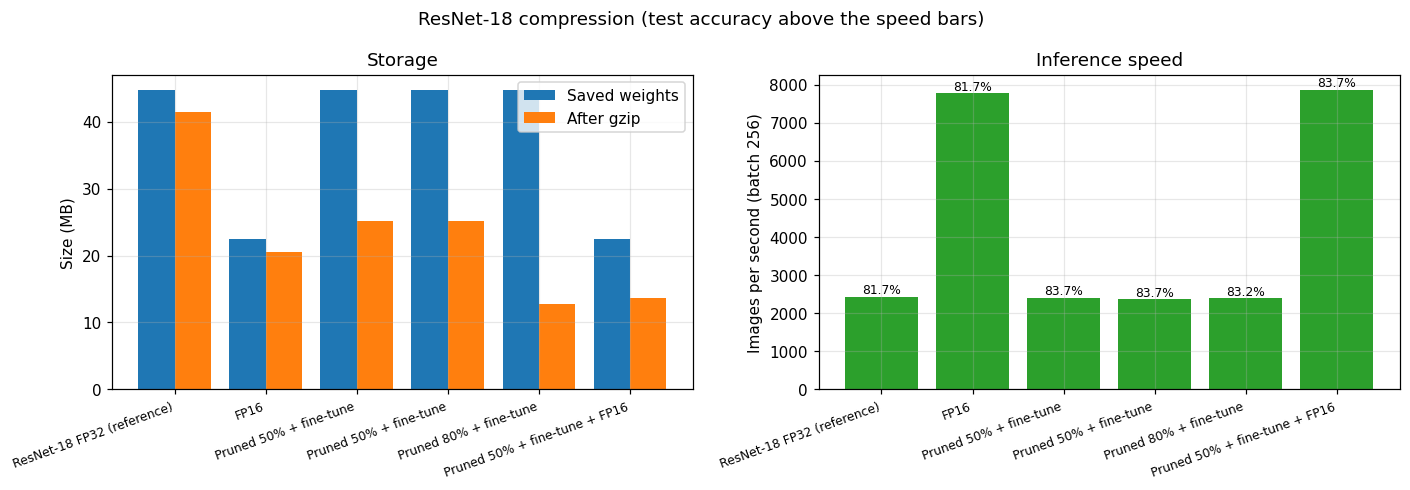

In [242]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
names = compression_df["Model"]
positions = np.arange(len(names))

axes[0].bar(positions - 0.2, compression_df["File (MB)"], width=0.4, label="Saved weights")
axes[0].bar(positions + 0.2, compression_df["Gzip File (MB)"], width=0.4, label="After gzip")
axes[0].set_ylabel("Size (MB)")
axes[0].set_title("Storage")
axes[0].legend()

axes[1].bar(positions, compression_df["Throughput (img/s, bs 256)"], color="tab:green")
axes[1].set_ylabel("Images per second (batch 256)")
axes[1].set_title("Inference speed")

for ax in axes:
    ax.set_xticks(positions)
    ax.set_xticklabels(names, rotation=20, ha="right", fontsize=8)

for i, accuracy in enumerate(compression_df["Test Accuracy (%)"]):
    axes[1].annotate(f"{accuracy:.1f}%", (i, compression_df["Throughput (img/s, bs 256)"].iloc[i]),
                     ha="center", va="bottom", fontsize=8)

fig.suptitle("ResNet-18 compression (test accuracy above the speed bars)")
plt.tight_layout()
savefig(fig, "c1_compression")
plt.show()

### C1a. Results of the compression

The reference ResNet-18 reaches **81.71%** test accuracy, stores **44.8 MB** of weights (41.5 MB after gzip) and processes **2,429** images per second at batch size 256.

| Version | Test acc. (%) | Change (pp) | Non-zero weights | Gzip (MB) | Throughput bs 256 |
|---|---|---|---|---|---|
| FP32 reference | 81.71 | 0.00 | 11,164,352 | 41.5 | 1.00× |
| FP16 | 81.72 | +0.01 | 11,164,327 | 20.5 | **3.20×** |
| Pruned 50% + fine-tune | 83.66 | +1.95 | 5,582,176 | 25.1 | 0.99× |
| Pruned 80% + fine-tune | 83.20 | +1.49 | 2,232,870 | **12.8** | 0.99× |
| Pruned 50% + fine-tune + FP16 | 83.65 | +1.94 | 5,582,176 | 13.7 | **3.24×** |

All versions stay inside the 1-point tolerance. (The table above lists the 50% model twice because the pruning cell ran twice in the interrupted session, so both rows are the same model. The cell now drops old rows before it runs.)

**FP16 is the only method that makes inference faster:** It halves the file, keeps the accuracy to within 0.01 points and gives **3.2×** the throughput, because the T4's tensor cores work on half-precision matrices. It costs 0.02 s and no training. For a single image it is slightly slower (3.79 ms against 3.28 ms): at batch size 1 the GPU is mostly idle and the time goes to launching kernels, not to arithmetic.

**Pruning only saves storage:** Removing 80% of the weights shrinks the gzip file to **31%** of the reference, but the saved file stays at 44.8 MB and the throughput does not change (0.99×). The zeros are still stored and multiplied by dense kernels. To turn sparsity into speed one would need structured pruning (removing whole channels) or sparse kernels. The batch-1 latencies of the pruned models (2.5 to 3.5 ms) are within the measurement noise: the same 50% model measured 2.75 and 3.52 ms in two calls.

**Pruning before fine-tuning:** Right after pruning, 50% of the weights could be removed for only **−0.53** points (81.18%), so the network has a lot of small, unimportant weights. At 80% the accuracy collapses to **30.48%**, and one epoch of fine-tuning brings it back to 83.20%.

**Why the pruned models beat the reference:** The +1.5 to +2.0 points do not mean that pruning improves the model. The reference stopped after eight epochs while it was still improving (best epoch 8), and the fine-tuning adds a ninth epoch of training. A fair comparison would also train the unpruned model for one more epoch, which we did not run. What the results do show is that one epoch is enough to recover from removing 80% of the weights. The compression compute is about **47 s** for each pruned model (almost all of it the fine-tuning epoch), against 372 s for the original training.

**What we would use:** If speed matters, FP16 is free and gives a 3.2× higher throughput, which removes much of ResNet-18's speed disadvantage from Task 6 (AlexNet runs at about 15,500 images per second, ResNet-18 in FP16 at about 7,800). If storage or download size matters, pruning 50% and converting to FP16 gives both: a third of the gzip size and 3.24× the throughput. Limits: one seed, one fine-tuning epoch, and timings from one T4 session.

---

## Challenge 2. Generalization to unseen shifts
### C2. Plan: test the selected models on conditions they never saw
The models are fixed before this section: ResNet-18 (our choice for clean accuracy), AlexNet with strong augmentation (our choice for noisy inputs) and the AlexNet baseline as a reference. Nothing here is used to pick a model or an augmentation.

**(a) Unseen corruption families:** Training and model selection only ever involved crops, flips, rotation, shear and Gaussian noise. We now apply three different families to the **10,000 held-out test images**, at three severities each, and keep the image identities paired with the clean test images:
- *Gaussian blur* (5 × 5 kernel, σ = 0.5 / 1.0 / 1.5): removes fine detail, the opposite of added noise.
- *JPEG compression* (quality 60 / 30 / 10): blocky artefacts and colour bleeding, as in images sent over the web.
- *Contrast reduction* (factor 0.6 / 0.4 / 0.2 around each image's mean): a washed-out or foggy image.

Labels are unchanged, and the corrupted images go through the same normalization with training-set statistics. Because the images are paired, we can count the images that were correct when clean and became wrong.

**(b) A new image domain: CIFAR-10.1:** Recht et al. (2019) collected 2,000 new images for the same ten classes following the original CIFAR-10 procedure (version v6). The labels use the same class indices, so no mapping is needed, and the images are already 32 × 32. The shift here is natural: new photographs, not a synthetic corruption.

In [243]:
from PIL import Image
import torchvision.transforms.functional as TF

test_images = to_float(SPLITS["test"].x)
test_labels = SPLITS["test"].y
labels_cpu = test_labels.cpu()


def gaussian_blur(images, sigma):
    return TF.gaussian_blur(images, kernel_size=5, sigma=sigma)


def jpeg_compress(images, quality):
    out = []
    for img in (images * 255).round().byte().cpu().permute(0, 2, 3, 1).numpy():
        buffer = io.BytesIO()
        Image.fromarray(img).save(buffer, format="JPEG", quality=quality)
        out.append(np.array(Image.open(buffer)))
    return torch.from_numpy(np.stack(out)).permute(0, 3, 1, 2).float().div(255).to(device)


def reduce_contrast(images, factor):
    centre = images.mean(dim=(1, 2, 3), keepdim=True)
    return (centre + factor * (images - centre)).clamp(0, 1)


unseen_families = {
    "Gaussian blur": (gaussian_blur, [0.5, 1.0, 1.5]),
    "JPEG compression": (jpeg_compress, [60, 30, 10]),
    "Contrast reduction": (reduce_contrast, [0.6, 0.4, 0.2]),
}

selected_models = {
    "AlexNet baseline": baseline_model,
    "AlexNet strong aug": strong_aug_model,
    "ResNet-18": resnet,
}

clean_predictions = {
    name: get_predictions(model, test_images)
    for name, model in selected_models.items()
}

generalization_results = []
corrupted_predictions = {}

for family, (corrupt, levels) in unseen_families.items():
    for severity, level in enumerate(levels, start=1):
        images = corrupt(test_images, level)

        for name, model in selected_models.items():
            predictions = get_predictions(model, images)
            corrupted_predictions[(family, severity, name)] = predictions
            clean_correct = clean_predictions[name] == labels_cpu

            generalization_results.append({
                "Family": family,
                "Severity": severity,
                "Setting": level,
                "Model": name,
                "Clean Accuracy (%)": 100 * clean_correct.float().mean().item(),
                "Accuracy (%)": 100 * (predictions == labels_cpu).float().mean().item(),
                "New Errors": int((clean_correct & (predictions != labels_cpu)).sum()),
            })

generalization_df = pd.DataFrame(generalization_results)
generalization_df["Drop (pp)"] = generalization_df["Clean Accuracy (%)"] - generalization_df["Accuracy (%)"]

display(
    generalization_df.pivot_table(
        index=["Family", "Severity", "Setting"], columns="Model", values="Accuracy (%)"
    ).round(2)
)
display(
    generalization_df.pivot_table(
        index=["Family", "Severity"], columns="Model", values="New Errors"
    )
)

Model                                AlexNet baseline  AlexNet strong aug  ResNet-18
Family             Severity Setting                                                 
Contrast reduction 1        0.6                 73.30               72.59      79.25
                   2        0.4                 59.99               56.68      71.64
                   3        0.2                 29.54               24.67      40.65
Gaussian blur      1        0.5                 76.03               74.89      79.97
                   2        1.0                 52.68               61.67      49.51
                   3        1.5                 40.08               49.27      35.68
JPEG compression   1        60.0                74.62               73.22      72.93
                   2        30.0                71.17               71.32      66.47
                   3        10.0                61.31               62.39      51.49

Model                        AlexNet baseline  AlexNet strong aug  ResNet-18
Family             Severity                                                 
Contrast reduction 1                    808.0               824.0      549.0
                   2                   2230.0              2505.0     1394.0
                   3                   5358.0              5645.0     4466.0
Gaussian blur      1                    490.0               347.0      425.0
                   2                   3020.0              1988.0     3632.0
                   3                   4285.0              3249.0     5019.0
JPEG compression   1                    626.0               520.0     1183.0
                   2                   1047.0               772.0     1883.0
                   3                   2098.0              1732.0     3376.0

**Plot accuracy against severity:** Severity 0 is the clean test set.

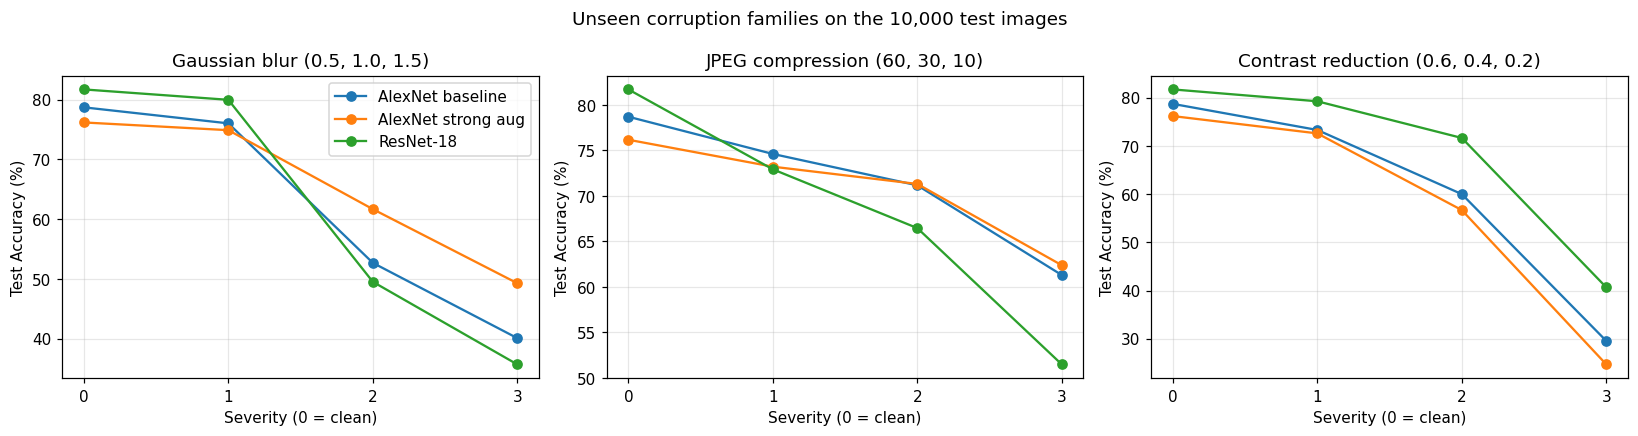

In [244]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, family in zip(axes, unseen_families):
    part = generalization_df[generalization_df["Family"] == family]
    for name in selected_models:
        rows = part[part["Model"] == name]
        severities = [0] + rows["Severity"].tolist()
        accuracies = [rows["Clean Accuracy (%)"].iloc[0]] + rows["Accuracy (%)"].tolist()
        ax.plot(severities, accuracies, marker="o", label=name)

    settings = ", ".join(str(level) for level in unseen_families[family][1])
    ax.set_title(f"{family} ({settings})")
    ax.set_xlabel("Severity (0 = clean)")
    ax.set_xticks([0, 1, 2, 3])
    ax.set_ylabel("Test Accuracy (%)")

axes[0].legend()
fig.suptitle("Unseen corruption families on the 10,000 test images")
plt.tight_layout()
savefig(fig, "c2_unseen_corruptions")
plt.show()

**Look at the failures:** For each family we count, at the highest severity, which class ResNet-18 predicts for the images it newly gets wrong, and show one such image at every severity.

,Family,New Errors (severity 3),Most Common Prediction,Share (%),Top Pairs
0,Gaussian blur,5019,cat,49.8107,"frog → cat (564), automobile → cat (427), dog ..."
1,JPEG compression,3376,cat,21.2974,"automobile → truck (192), frog → cat (176), bi..."
2,Contrast reduction,4466,deer,62.2257,"horse → deer (494), frog → deer (447), truck →..."


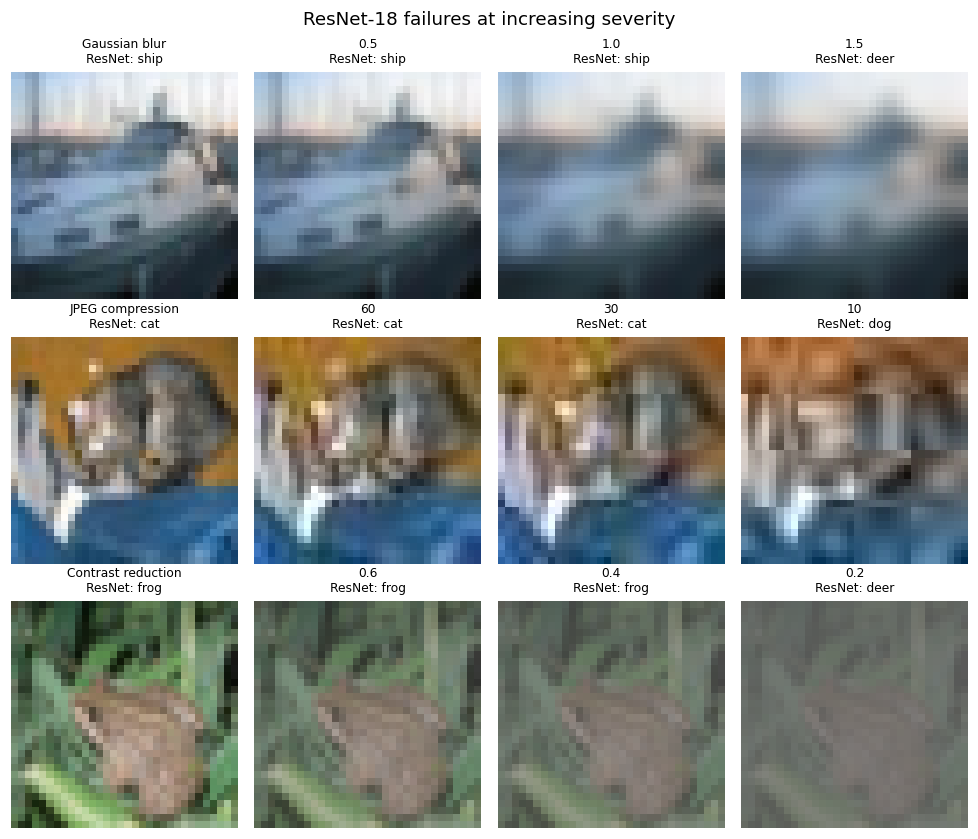

In [245]:
failure_results = []
example_ids = {}

for family in unseen_families:
    clean_correct = clean_predictions["ResNet-18"] == labels_cpu
    predictions = corrupted_predictions[(family, 3, "ResNet-18")]
    new = clean_correct & (predictions != labels_cpu)
    if new.sum() == 0:
        continue

    predicted = pd.Series([CLASSES[p] for p in predictions[new].tolist()]).value_counts()
    pairs = pd.Series([
        f"{CLASSES[t]} → {CLASSES[p]}"
        for t, p in zip(labels_cpu[new].tolist(), predictions[new].tolist())
    ]).value_counts().head(3)

    failure_results.append({
        "Family": family,
        "New Errors (severity 3)": int(new.sum()),
        "Most Common Prediction": predicted.index[0],
        "Share (%)": 100 * predicted.iloc[0] / new.sum().item(),
        "Top Pairs": ", ".join(f"{k} ({v})" for k, v in pairs.items()),
    })
    example_ids[family] = torch.where(new)[0][0].item()

display(pd.DataFrame(failure_results))

fig, axes = plt.subplots(len(example_ids), 4, figsize=(9, 2.6 * len(example_ids)), squeeze=False)

for r, (family, idx) in enumerate(example_ids.items()):
    corrupt, levels = unseen_families[family]
    image = test_images[idx:idx + 1]
    versions = [("clean", image)] + [(str(level), corrupt(image, level)) for level in levels]

    for j, (setting, version) in enumerate(versions):
        prediction = get_predictions(resnet, version)[0].item()
        axes[r, j].imshow(version[0].cpu().permute(1, 2, 0))
        axes[r, j].set_title(f"{family if j == 0 else setting}\nResNet: {CLASSES[prediction]}", fontsize=8)
        axes[r, j].axis("off")

fig.suptitle("ResNet-18 failures at increasing severity")
plt.tight_layout()
savefig(fig, "c2_failure_examples")
plt.show()

**Evaluate on CIFAR-10.1:** The two small `.npy` files (about 6 MB) are downloaded from the authors' repository into the data folder. If the download fails, the cell reports it and the rest of the notebook still runs.

In [246]:
import urllib.request

CIFAR101_URL = "https://github.com/modestyachts/CIFAR-10.1/raw/master/datasets/"
cifar101_images = None

try:
    for file_name in ["cifar10.1_v6_data.npy", "cifar10.1_v6_labels.npy"]:
        if not (DATA_DIR / file_name).exists():
            urllib.request.urlretrieve(CIFAR101_URL + file_name, DATA_DIR / file_name)

    x101 = np.load(DATA_DIR / "cifar10.1_v6_data.npy")
    y101 = np.load(DATA_DIR / "cifar10.1_v6_labels.npy")
    cifar101_images = torch.from_numpy(x101).permute(0, 3, 1, 2).float().div(255).to(device)
    cifar101_labels = torch.from_numpy(y101).long()
    print("CIFAR-10.1:", tuple(x101.shape), "| images per class:", np.bincount(y101).tolist())
except Exception as error:
    print("CIFAR-10.1 could not be loaded:", error)

if cifar101_images is not None:
    domain_results = []
    class_recall = {}

    for name, model in selected_models.items():
        predictions = get_predictions(model, cifar101_images)
        domain_results.append({
            "Model": name,
            "CIFAR-10 Test (%)": 100 * (clean_predictions[name] == labels_cpu).float().mean().item(),
            "CIFAR-10.1 (%)": 100 * (predictions == cifar101_labels).float().mean().item(),
        })
        class_recall[name] = [
            100 * (predictions[cifar101_labels == c] == c).float().mean().item()
            for c in range(NUM_CLASSES)
        ]

    domain_df = pd.DataFrame(domain_results)
    domain_df["Drop (pp)"] = domain_df["CIFAR-10 Test (%)"] - domain_df["CIFAR-10.1 (%)"]
    display(domain_df.round(2))
    display(pd.DataFrame(class_recall, index=CLASSES).round(1))

CIFAR-10.1: (2000, 32, 32, 3) | images per class: [200, 200, 200, 200, 200, 200, 200, 200, 200, 200]


,Model,CIFAR-10 Test (%),CIFAR-10.1 (%),Drop (pp)
0,AlexNet baseline,78.71,66.35,12.36
1,AlexNet strong aug,76.18,62.65,13.53
2,ResNet-18,81.71,71.10,10.61


,AlexNet baseline,AlexNet strong aug,ResNet-18
airplane,51.0,60.5,61.0
automobile,70.5,60.0,73.0
bird,59.0,34.5,54.5
cat,56.5,52.5,56.0
deer,72.5,55.5,75.5
dog,54.5,62.0,65.5
frog,85.0,67.5,84.5
horse,73.5,67.5,81.5
ship,77.0,83.0,79.5
truck,64.0,83.5,80.0


### C2a. Results of the generalization tests

**Unseen corruptions (test accuracy, %):** Clean test accuracy is 78.71 (AlexNet baseline), 76.18 (AlexNet strong augmentation) and 81.71 (ResNet-18).

| Corruption | AlexNet baseline | AlexNet strong aug | ResNet-18 |
|---|---|---|---|
| Blur σ = 0.5 / 1.0 / 1.5 | 76.0 / 52.7 / 40.1 | 74.9 / **61.7** / **49.3** | **80.0** / 49.5 / 35.7 |
| JPEG quality 60 / 30 / 10 | **74.6** / 71.2 / 61.3 | 73.2 / **71.3** / **62.4** | 72.9 / 66.5 / 51.5 |
| Contrast 0.6 / 0.4 / 0.2 | 73.3 / 60.0 / 29.5 | 72.6 / 56.7 / 24.7 | **79.3** / **71.6** / **40.7** |

**No model is robust to every shift:** The ranking depends on the corruption family:
- *Blur.* Strong augmentation transfers best. At σ = 1.0 it loses 14.5 points, against 26.0 for the baseline and 32.2 for ResNet-18. Its training noise and random crops seem to make it rely less on fine detail. ResNet-18 is the most accurate model at σ = 0.5 and the least accurate from σ = 1.0.
- *JPEG.* ResNet-18 is the most fragile. Already at quality 60 it falls below both AlexNets, and at quality 10 it loses 30.2 points against 17.4 (baseline) and 13.8 (strong augmentation). JPEG removes fine high-frequency detail and adds 8 × 8 block edges, and ResNet-18, which keeps the full resolution in its first stage, seems to depend most on that detail.
- *Contrast.* ResNet-18 is clearly the best (40.7% at factor 0.2 against 29.5%), and strong augmentation is now the worst. Noise, rotation and cropping did not teach it anything about washed-out images.

So the robustness that strong augmentation bought in Task 4 transfers to blur and a little to JPEG, but not to contrast. ResNet-18's weakness to noise in Task 4 comes back under blur and JPEG, while it handles contrast loss best.

**How the models fail:** At the highest severity ResNet-18 falls back on one class instead of spreading its mistakes. Under strong blur half of its 5,019 new errors (49.8%) are predicted *cat* (frog → cat 564, automobile → cat 427). Under low contrast 62.2% of 4,466 new errors become *deer* (horse → deer 494, frog → deer 447). JPEG errors are more spread (the top prediction, cat, takes 21.3%), and the largest pair, automobile → truck (192), is a confusion between similar classes. When an image loses most of its information, the model does not become uncertain between neighbouring classes: it assigns one default class that fits a smooth, low-detail image. In the failure examples the ship and the frog are still recognisable to a person at the severity where ResNet-18 fails, apart from the frog at contrast 0.2.

**New photographs (CIFAR-10.1):** All three models lose between **10.6 and 13.5 points** on the 2,000 new images: 66.35% (baseline, −12.36), 62.65% (strong augmentation, −13.53) and **71.10%** (ResNet-18, −10.61). The ranking stays the same as on CIFAR-10, as Recht et al. (2019) also found for many larger models, and ResNet-18 loses the least. Strong augmentation does not help here and even loses the most. Its per-class recall shows uneven changes, for example bird at 34.5% against 59.0% for the baseline, while ship and truck are its best classes (83.0% and 83.5%). Cat, bird and airplane are the weakest classes for ResNet-18 (54.5% to 61.0%). A natural shift in how the photos were collected therefore costs about as much as a moderate synthetic corruption, and augmenting with noise and rotation does not prepare a model for it.

**Conclusion:** Task 4 measured robustness to the corruptions that were also used in training. These tests show that it does not carry over evenly to unseen ones. ResNet-18 is the best choice for new photographs and for contrast changes. AlexNet with strong augmentation is the better choice for blurred or heavily compressed images. A model that should handle all of these would need augmentation that covers them (for example blur, JPEG and contrast changes), which we did not train. Limits: one seed per model, three severities per family, and CIFAR-10.1 has 200 images per class, so per-class numbers can move by several points by chance.

## Recap and report checklist

The CIFAR-10 workflow covers:
- Task 1: data inspection, preprocessing, splitting and randomness
- Task 2: architecture design and baseline evaluation
- Task 3: controlled capacity, L2 and dropout experiments
- Task 4: reproducible corruption and augmentation comparisons
- Task 5: per-class predictions and FGSM adversarial examples
- Task 6: training cost, inference benchmarks, seed and duration sensitivity, and the resulting tradeoffs
- Challenges: compression of ResNet-18 (FP16 and pruning), and generalization to unseen corruption families and CIFAR-10.1

**When reporting results:** explain why adaptations are appropriate for small RGB images, document the exact training and checkpoint-selection procedures, distinguish validation from reserved test metrics, use measured compute costs, and state when evidence is sensitive to short training runs or model-specific attacks. Do not infer unmeasured GPU-only timings or per-epoch history from final checkpoints.

## References

**Dataset**
- A. Krizhevsky. *Learning Multiple Layers of Features from Tiny Images.* Technical report, University of Toronto, 2009. CIFAR-10: https://www.cs.toronto.edu/~kriz/cifar.html
- B. Recht, R. Roelofs, L. Schmidt, V. Shankar. Do ImageNet classifiers generalize to ImageNet? ICML 2019 (CIFAR-10.1 first described in arXiv:1806.00451, 2018). CIFAR-10.1 (v6): https://github.com/modestyachts/CIFAR-10.1 (Challenge 2)

**Architectures and methods**
- A. Krizhevsky, I. Sutskever, G. E. Hinton. ImageNet classification with deep convolutional neural networks. *NeurIPS*, 2012. (AlexNet)
- K. He, X. Zhang, S. Ren, J. Sun. Deep residual learning for image recognition. *CVPR*, 2016. (ResNet)
- S. Ioffe, C. Szegedy. Batch normalization: accelerating deep network training by reducing internal covariate shift. *ICML*, 2015.
- N. Srivastava, G. Hinton, A. Krizhevsky, I. Sutskever, R. Salakhutdinov. Dropout: a simple way to prevent neural networks from overfitting. *JMLR* 15, 2014.
- I. J. Goodfellow, J. Shlens, C. Szegedy. Explaining and harnessing adversarial examples. *ICLR*, 2015. (FGSM)

**Documentation and code**
- PyTorch documentation: https://pytorch.org/docs/stable/ (in particular [`torch.nn`](https://pytorch.org/docs/stable/nn.html), [reproducibility](https://pytorch.org/docs/stable/notes/randomness.html), [`F.affine_grid` / `F.grid_sample`](https://pytorch.org/docs/stable/nn.functional.html))
- PyTorch pruning utilities `torch.nn.utils.prune`: https://pytorch.org/tutorials/intermediate/pruning_tutorial.html (Challenge 1)
- torchvision `CIFAR10` dataset: https://pytorch.org/vision/stable/generated/torchvision.datasets.CIFAR10.html
- scikit-learn metrics (`classification_report`, `confusion_matrix`): https://scikit-learn.org/stable/modules/model_evaluation.html
- Course notebook `ID2223_Lab1.ipynb` (Part A of this notebook).